In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    channel="ibm_cloud",
    token="your token",
    overwrite=True
)

In [1]:
service = QiskitRuntimeService(channel="ibm_cloud")

NameError: name 'QiskitRuntimeService' is not defined

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

print("Connected successfully!")

qiskit_runtime_service.__init__:WARNING:2026-10-02 00:44:08,882: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


Connected successfully!


In [3]:
for backend in service.backends():
    print(backend.name)

qiskit_runtime_service.backends:WARNING:2026-10-02 00:44:16,274: Loading instance: student-ashokp25, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-02 00:44:18,494: Loading instance: QForge Quantum Club, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-02 00:44:18,494: Loading instance: student-otherssuc, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-02 00:44:18,496: Loading instance: student-nagaraju.23phd7022, plan: open


ibm_fez
ibm_kingston
ibm_marrakesh


In [4]:
backend = service.backend("ibm_kingston")

qiskit_runtime_service.backends:WARNING:2026-10-02 00:44:23,688: Using instance: student-ashokp25, plan: open


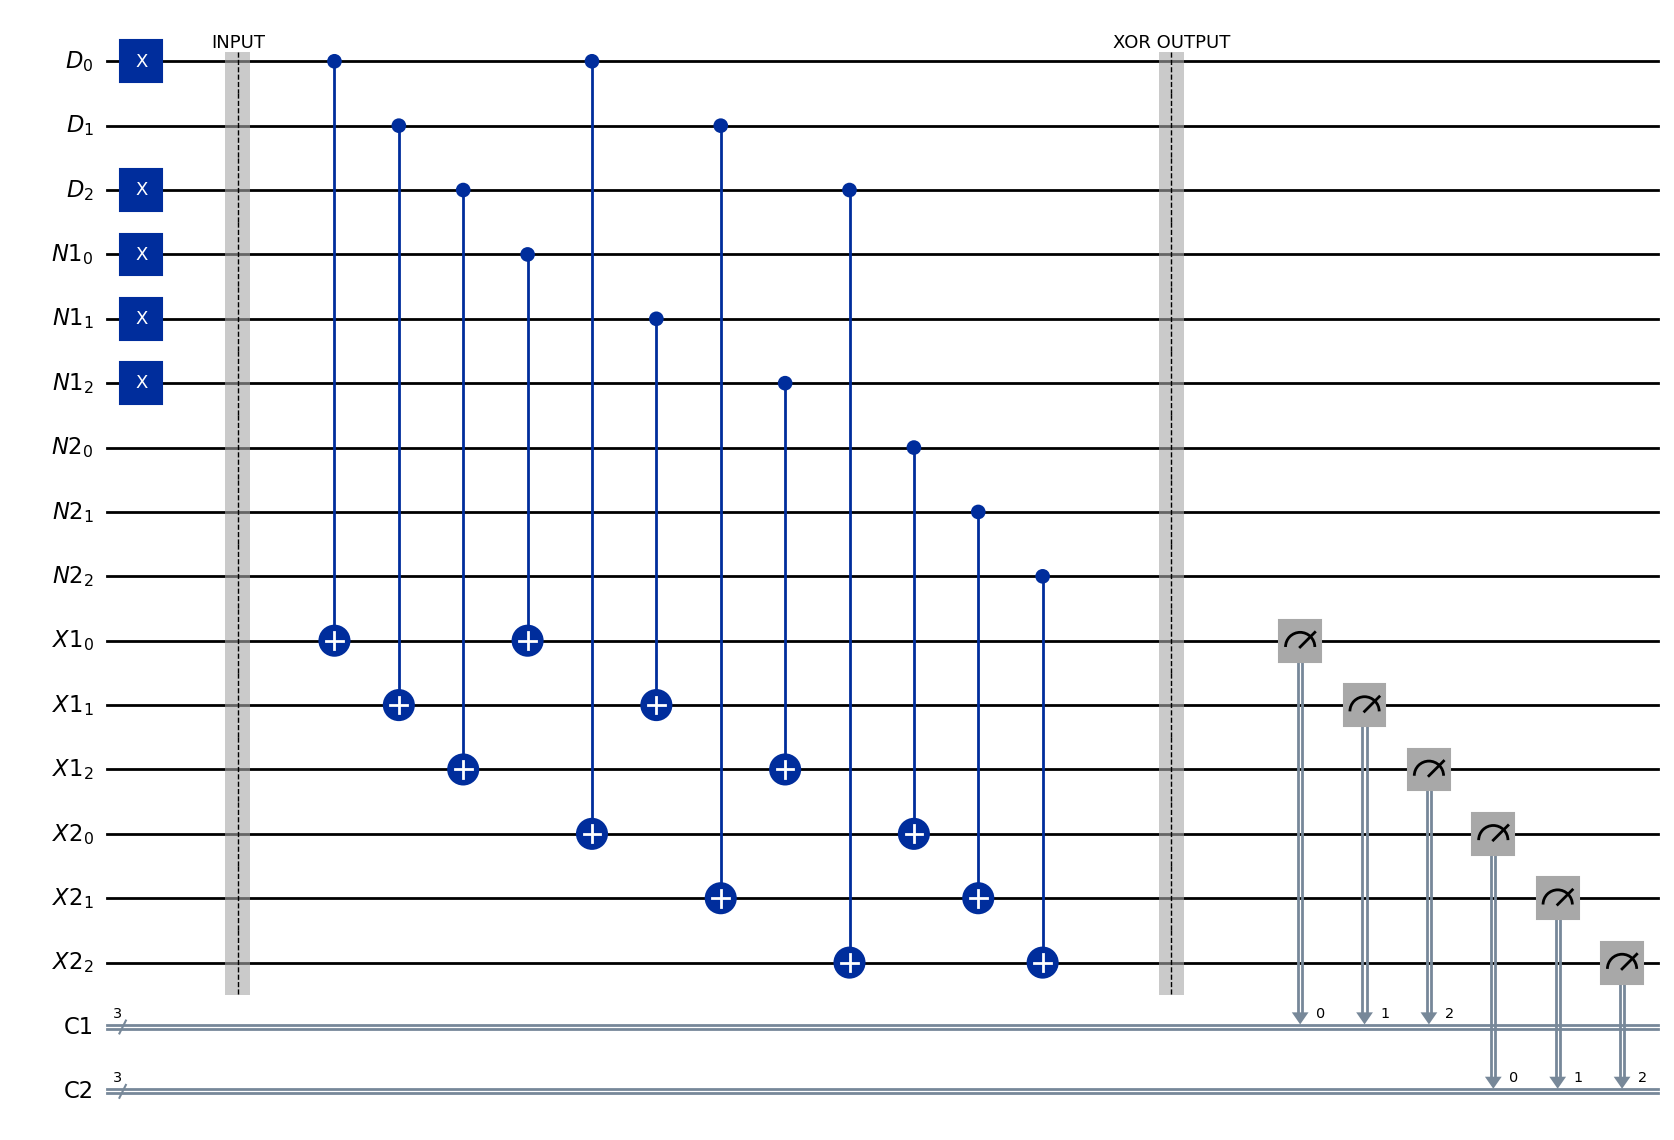


========== IBM HARDWARE METRICS ==========

Backend       : ibm_kingston
Circuit Depth : 10
Circuit Width : 162
Total Qubits  : 156
Circuit Size  : 53

Gate Counts:

OrderedDict([('rz', 18), ('sx', 12), ('cz', 12), ('measure', 6), ('x', 5), ('barrier', 2)])


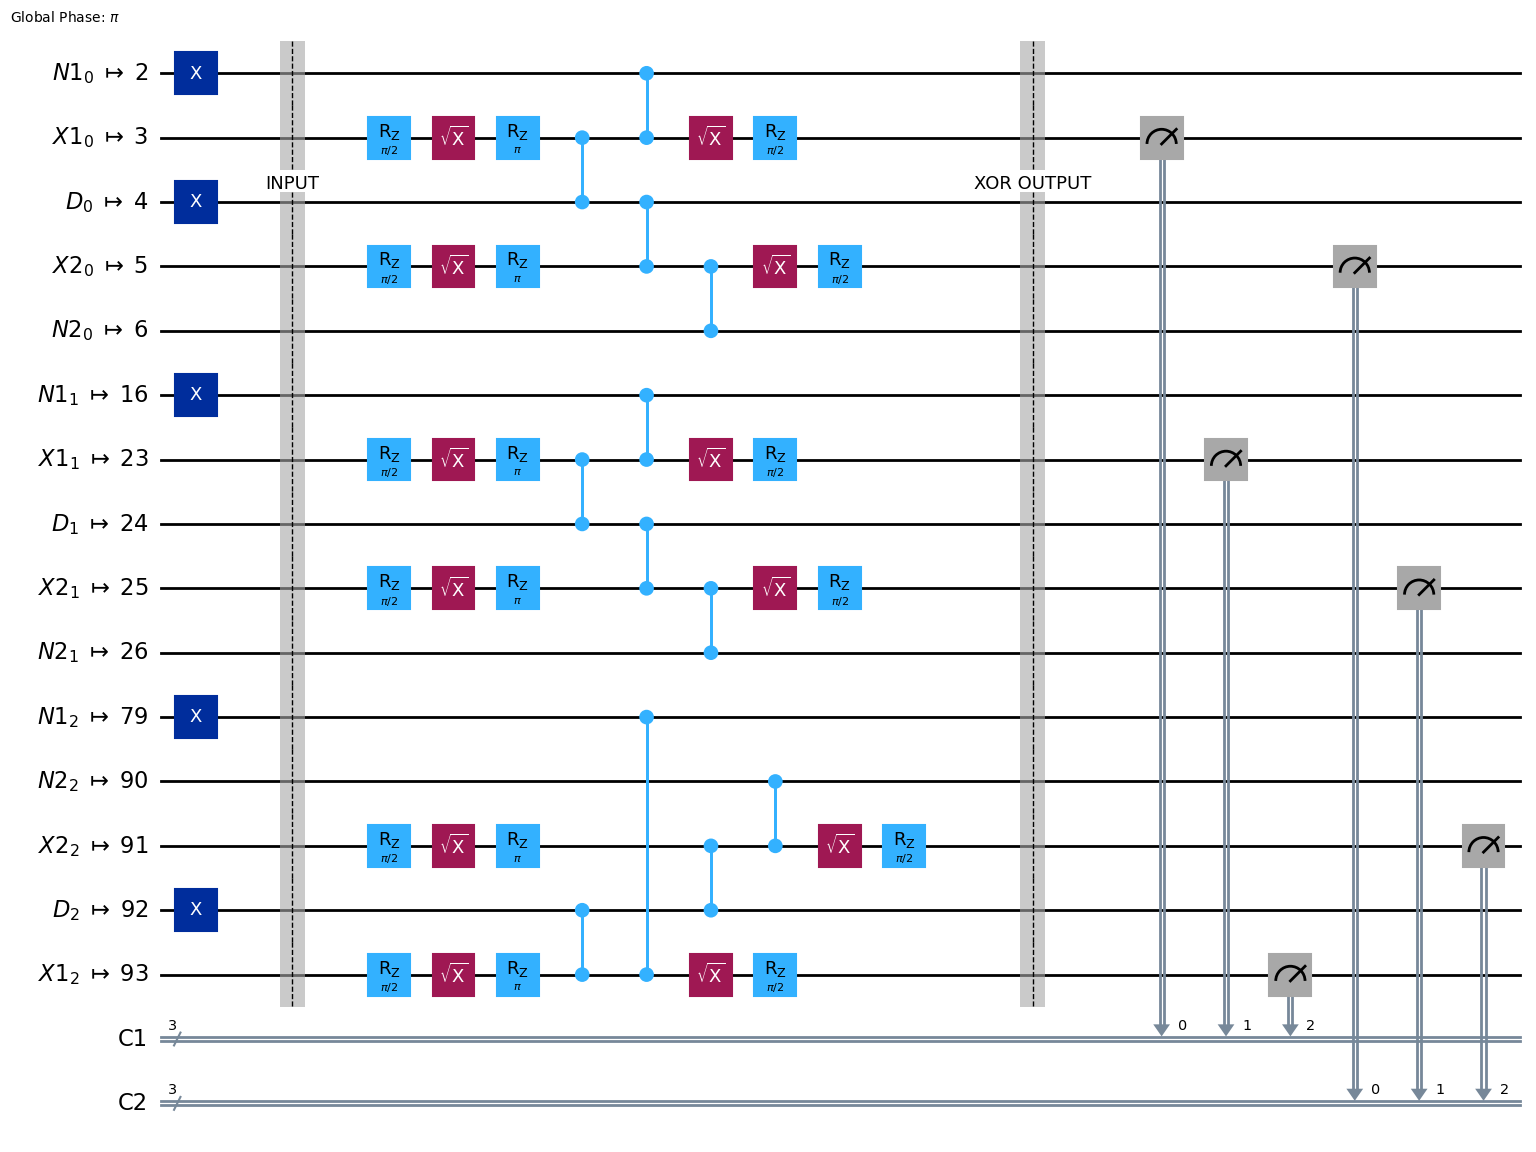


IBM RUNTIME JOB SUBMITTED
Job ID : davb3b492g1c7398k28g

Waiting for execution...

Execution Complete.

Returned Data Structure:

DataBin(C1=BitArray(<shape=(), num_shots=1024, num_bits=3>), C2=BitArray(<shape=(), num_shots=1024, num_bits=3>))

========== X1 RAW COUNTS ==========

{'000': 346, '010': 596, '110': 36, '011': 17, '001': 6, '100': 21, '101': 1, '111': 1}

========== X2 RAW COUNTS ==========

{'101': 908, '111': 26, '001': 50, '100': 39, '000': 1}

========== SUCCESS PROBABILITY ==========

X1 Success : 596/1024 = 58.20%
X2 Success : 908/1024 = 88.67%

========== X1 HISTOGRAM ==========



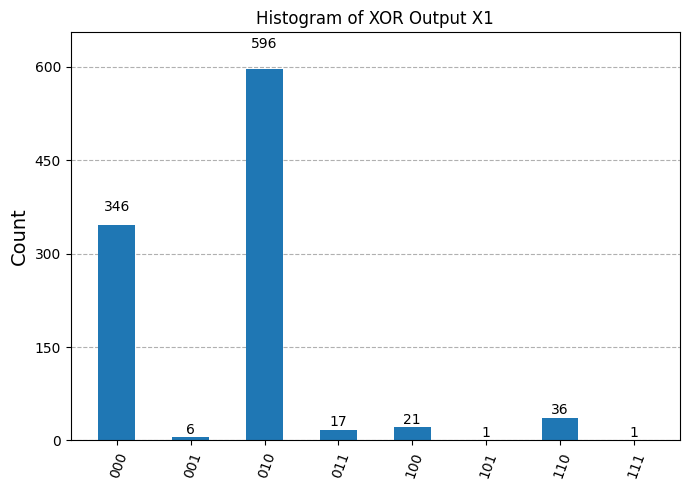


========== X2 HISTOGRAM ==========



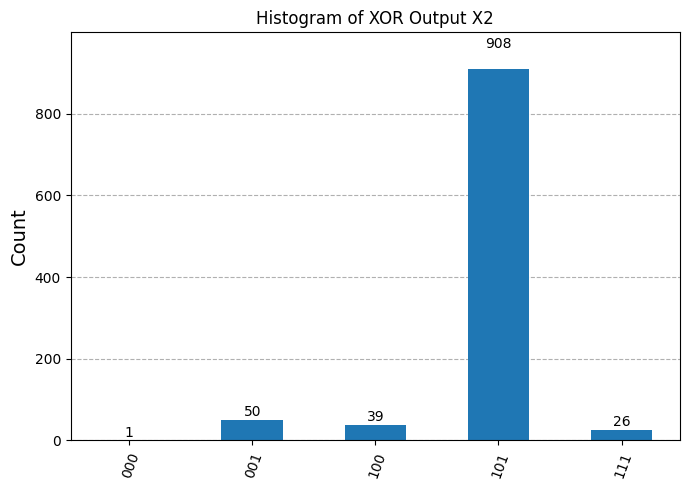


========== EXPECTED OUTPUT ==========

Destination Node : 101
Neighbor 1       : 111
Neighbor 2       : 000

Expected X1 = 010
Expected X2 = 101

Execution completed successfully on IBM Kingston.


In [5]:
# ============================================================
# HISTOGRAM FOR XOR-BASED HAMMING NETWORK
# ============================================================

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister,
    transpile
)


from qiskit.visualization import plot_histogram

import matplotlib.pyplot as plt

# ============================================================
# HELPER FUNCTION
# ============================================================

def initialize_bits(qc, reg, bitstring):

    for i, bit in enumerate(reversed(bitstring)):

        if bit == '1':

            qc.x(reg[i])

# ============================================================
# REGISTERS
# ============================================================

D = QuantumRegister(3, 'D')

N1 = QuantumRegister(3, 'N1')

N2 = QuantumRegister(3, 'N2')

X1 = QuantumRegister(3, 'X1')

X2 = QuantumRegister(3, 'X2')

C1 = ClassicalRegister(3, 'C1')

C2 = ClassicalRegister(3, 'C2')

# ============================================================
# CIRCUIT
# ============================================================

qc = QuantumCircuit(
    D, N1, N2,
    X1, X2,
    C1, C2
)

# ============================================================
# INPUTS
# Destination = 101
# Neighbor1   = 111
# Neighbor2   = 000
# ============================================================

initialize_bits(qc, D,  "101")

initialize_bits(qc, N1, "111")

initialize_bits(qc, N2, "000")

qc.barrier(label='INPUT')

# ============================================================
# XOR NETWORK
# X1 = D XOR N1
# X2 = D XOR N2
# ============================================================

for i in range(3):

    qc.cx(D[i], X1[i])

    qc.cx(N1[i], X1[i])

    qc.cx(D[i], X2[i])

    qc.cx(N2[i], X2[i])

qc.barrier(label='XOR OUTPUT')

# ============================================================
# MEASUREMENT
# ============================================================

qc.measure(X1, C1)

qc.measure(X2, C2)

# ============================================================
# DISPLAY CIRCUIT
# ============================================================

fig = qc.draw(
    output='mpl',
    fold=120,
    idle_wires=False,
    style='iqp'
)
display(fig)
fig.savefig(
    "xor_hamming_network.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
# ============================================================
# TRANSPILE FOR IBM KINGSTON
# ============================================================

transpiled_qc = transpile(
    qc,
    backend=backend,
    optimization_level=3
)

print("\n========== IBM HARDWARE METRICS ==========\n")

print("Backend       :", backend.name)
print("Circuit Depth :", transpiled_qc.depth())
print("Circuit Width :", transpiled_qc.width())
print("Total Qubits  :", transpiled_qc.num_qubits)
print("Circuit Size  :", transpiled_qc.size())

print("\nGate Counts:\n")
print(transpiled_qc.count_ops())

# ============================================================
# DISPLAY TRANSPILED CIRCUIT
# ============================================================

transpiled_fig = transpiled_qc.draw(
    output='mpl',
    fold=120,
    idle_wires=False,
    style='iqp'
)
display(transpiled_fig)
transpiled_fig.savefig(
    "xor_hamming_network_transpiled.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# EXECUTE ON IBM KINGSTON
# ============================================================

from qiskit_ibm_runtime import SamplerV2

sampler = SamplerV2(mode=backend)

job = sampler.run(
    [transpiled_qc],
    shots=1024
)

print("\n====================================================")
print("IBM RUNTIME JOB SUBMITTED")
print("====================================================")

print("Job ID :", job.job_id())

print("\nWaiting for execution...\n")

result = job.result()

print("Execution Complete.")

# ============================================================
# EXTRACT COUNTS
# ============================================================

pub = result[0]

print("\nReturned Data Structure:\n")
print(pub.data)

# Since C1 and C2 are returned separately by IBM Runtime
x1_counts = pub.data.C1.get_counts()
x2_counts = pub.data.C2.get_counts()

print("\n========== X1 RAW COUNTS ==========\n")
print(x1_counts)

print("\n========== X2 RAW COUNTS ==========\n")
print(x2_counts)

# ============================================================
# SUCCESS PROBABILITY
# ============================================================

expected_x1 = "010"
expected_x2 = "101"

x1_success = x1_counts.get(expected_x1, 0)
x2_success = x2_counts.get(expected_x2, 0)

shots = 1024

print("\n========== SUCCESS PROBABILITY ==========\n")

print(f"X1 Success : {x1_success}/{shots} = {100*x1_success/shots:.2f}%")
print(f"X2 Success : {x2_success}/{shots} = {100*x2_success/shots:.2f}%")

# ============================================================
# DISPLAY X1 HISTOGRAM
# ============================================================

print("\n========== X1 HISTOGRAM ==========\n")

x1_fig = plot_histogram(
    x1_counts,
    figsize=(7,5),
    bar_labels=True,
    title="Histogram of XOR Output X1"
)
display(x1_fig)
x1_fig.savefig(
    "x1_histogram_ibm.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# DISPLAY X2 HISTOGRAM
# ============================================================

print("\n========== X2 HISTOGRAM ==========\n")

x2_fig = plot_histogram(
    x2_counts,
    figsize=(7,5),
    bar_labels=True,
    title="Histogram of XOR Output X2"
)
display(x2_fig)
x2_fig.savefig(
    "x2_histogram_ibm.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# EXPECTED RESULTS
# ============================================================

print("\n========== EXPECTED OUTPUT ==========\n")

print("Destination Node : 101")
print("Neighbor 1       : 111")
print("Neighbor 2       : 000")

print()

print("Expected X1 = 010")
print("Expected X2 = 101")

print()

print("Execution completed successfully on IBM Kingston.")

In [ ]:
##POPCOUNT


========== POPCOUNT CIRCUIT ==========



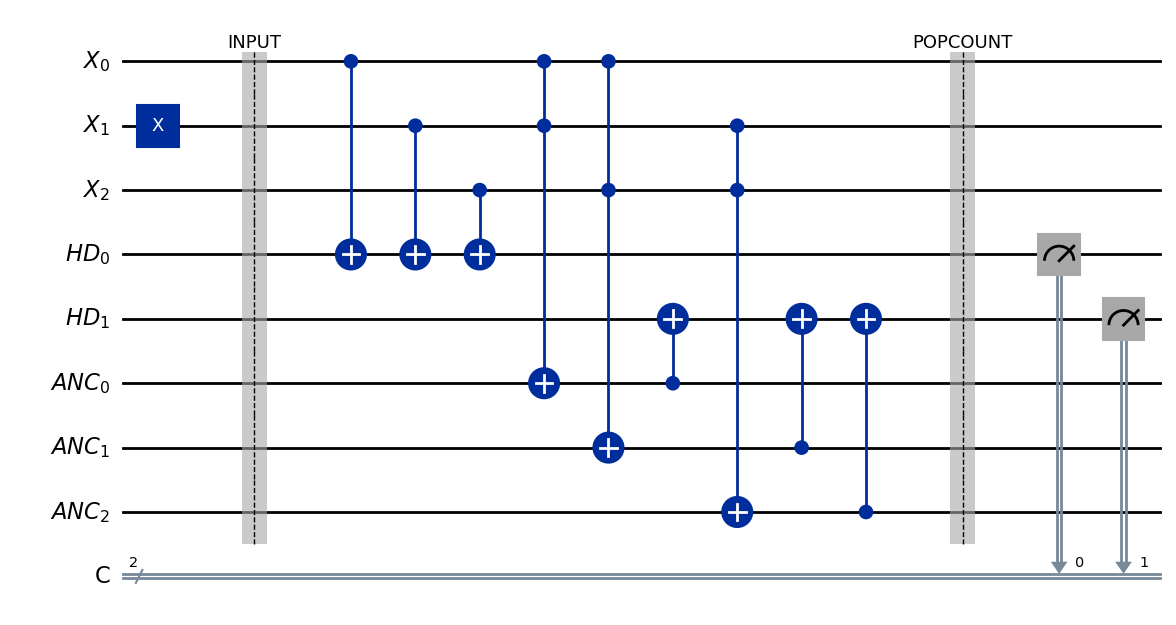

qiskit_runtime_service.__init__:WARNING:2026-10-02 00:48:48,246: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-10-02 00:48:48,246: Using instance: student-ashokp25, plan: open



Backend : ibm_kingston

========== IBM HARDWARE METRICS ==========

Backend       : ibm_kingston
Circuit Depth : 132
Circuit Width : 158
Total Qubits  : 156
Circuit Size  : 221

Gate Counts:

OrderedDict([('sx', 100), ('rz', 64), ('cz', 54), ('barrier', 2), ('measure', 2), ('x', 1)])

IBM RUNTIME JOB SUBMITTED
Job ID : davb47o4oijs73e791v0

Waiting for execution...

Execution Complete.

Returned Data Structure:

DataBin(C=BitArray(<shape=(), num_shots=1024, num_bits=2>))

========== POPCOUNT RAW COUNTS ==========

{'01': 837, '11': 71, '00': 78, '10': 38}

========== SUCCESS PROBABILITY ==========

Success : 837/1024 = 81.74%

========== POPCOUNT HISTOGRAM ==========



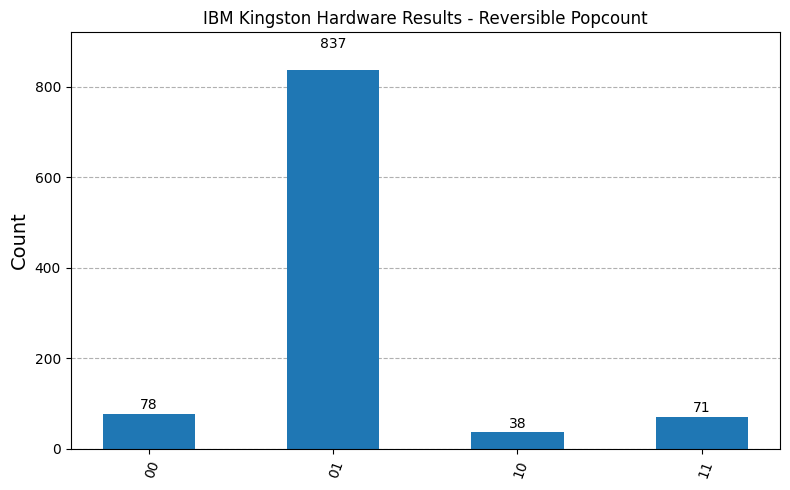


========== EXPECTED OUTPUT ==========

Input XOR Vector : 010
Hamming Weight   : 1
Expected HD      : 01

Execution completed successfully on IBM Kingston.


In [6]:
# ============================================================
# REVERSIBLE POPCOUNT BLOCK
# IBM KINGSTON HARDWARE EXECUTION
# ============================================================

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister
)

from qiskit.visualization import plot_histogram

from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    SamplerV2 as Sampler
)

from qiskit.transpiler import generate_preset_pass_manager

from IPython.display import display

import matplotlib.pyplot as plt

# ============================================================
# REGISTERS
# ============================================================

# XOR Input

X = QuantumRegister(3, "X")

# Hamming Distance Output

HD = QuantumRegister(2, "HD")

# Ancilla

ANC = QuantumRegister(3, "ANC")

# Classical Register

C = ClassicalRegister(2, "C")

# ============================================================
# CIRCUIT
# ============================================================

qc = QuantumCircuit(
    X,
    HD,
    ANC,
    C
)

# ============================================================
# INPUT INITIALIZATION
#
# X = 010
# ============================================================

qc.x(X[1])

qc.barrier(label="INPUT")

# ============================================================
# REVERSIBLE POPCOUNT
# ============================================================

# ----------------------------
# HD[0] = PARITY
# ----------------------------

qc.cx(X[0], HD[0])
qc.cx(X[1], HD[0])
qc.cx(X[2], HD[0])

# ----------------------------
# HD[1] = MAJORITY
# ----------------------------

qc.ccx(X[0], X[1], ANC[0])
qc.ccx(X[0], X[2], ANC[1])
qc.ccx(X[1], X[2], ANC[2])

qc.cx(ANC[0], HD[1])
qc.cx(ANC[1], HD[1])
qc.cx(ANC[2], HD[1])

qc.barrier(label="POPCOUNT")

# ============================================================
# MEASUREMENTS
# ============================================================

qc.measure(HD, C)

# ============================================================
# DRAW CIRCUIT
# ============================================================

print("\n========== POPCOUNT CIRCUIT ==========\n")

fig = qc.draw(
    output="mpl",
    fold=120,
    idle_wires=False,
    style="iqp"
)

display(fig)

plt.show()

fig.savefig(
    "popcount_circuit.png",
    dpi=300,
    bbox_inches="tight"
)

# ============================================================
# IBM QUANTUM SERVICE
# ============================================================

service = QiskitRuntimeService()

backend = service.backend("ibm_kingston")

print("\n====================================================")
print("Backend :", backend.name)
print("====================================================")

# ============================================================
# HARDWARE-AWARE TRANSPILATION
# ============================================================

pm = generate_preset_pass_manager(
    optimization_level=3,
    backend=backend
)

transpiled_qc = pm.run(qc)

# ============================================================
# IBM HARDWARE METRICS
# ============================================================

print("\n========== IBM HARDWARE METRICS ==========\n")

print("Backend       :", backend.name)
print("Circuit Depth :", transpiled_qc.depth())
print("Circuit Width :", transpiled_qc.width())
print("Total Qubits  :", backend.num_qubits)
print("Circuit Size  :", transpiled_qc.size())

print("\nGate Counts:\n")

print(transpiled_qc.count_ops())

# ============================================================
# IBM RUNTIME
# ============================================================

sampler = Sampler(mode=backend)

job = sampler.run(
    [transpiled_qc],
    shots=1024
)

print("\n====================================================")
print("IBM RUNTIME JOB SUBMITTED")
print("====================================================")

print("Job ID :", job.job_id())

print("\nWaiting for execution...\n")

result = job.result()

print("Execution Complete.")

# ============================================================
# DATA
# ============================================================

pub = result[0]

print("\nReturned Data Structure:\n")

print(pub.data)

counts = pub.data.C.get_counts()

# ============================================================
# COUNTS
# ============================================================

print("\n========== POPCOUNT RAW COUNTS ==========\n")

print(counts)

# ============================================================
# SUCCESS PROBABILITY
# ============================================================

expected = "01"

success = counts.get(expected, 0)

shots = sum(counts.values())

print("\n========== SUCCESS PROBABILITY ==========\n")

print(
    f"Success : {success}/{shots} = {100*success/shots:.2f}%"
)

# ============================================================
# HISTOGRAM
# ============================================================

print("\n========== POPCOUNT HISTOGRAM ==========\n")

hist = plot_histogram(
    counts,
    figsize=(8,5),
    title="IBM Kingston Hardware Results - Reversible Popcount"
)

display(hist)

hist.savefig(
    "ibm_popcount_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# EXPECTED OUTPUT
# ============================================================

print("\n========== EXPECTED OUTPUT ==========\n")

print("Input XOR Vector : 010")
print("Hamming Weight   : 1")
print("Expected HD      : 01")

print("\nExecution completed successfully on IBM Kingston.")

In [ ]:
##comparator


========== COMPARATOR CIRCUIT ==========



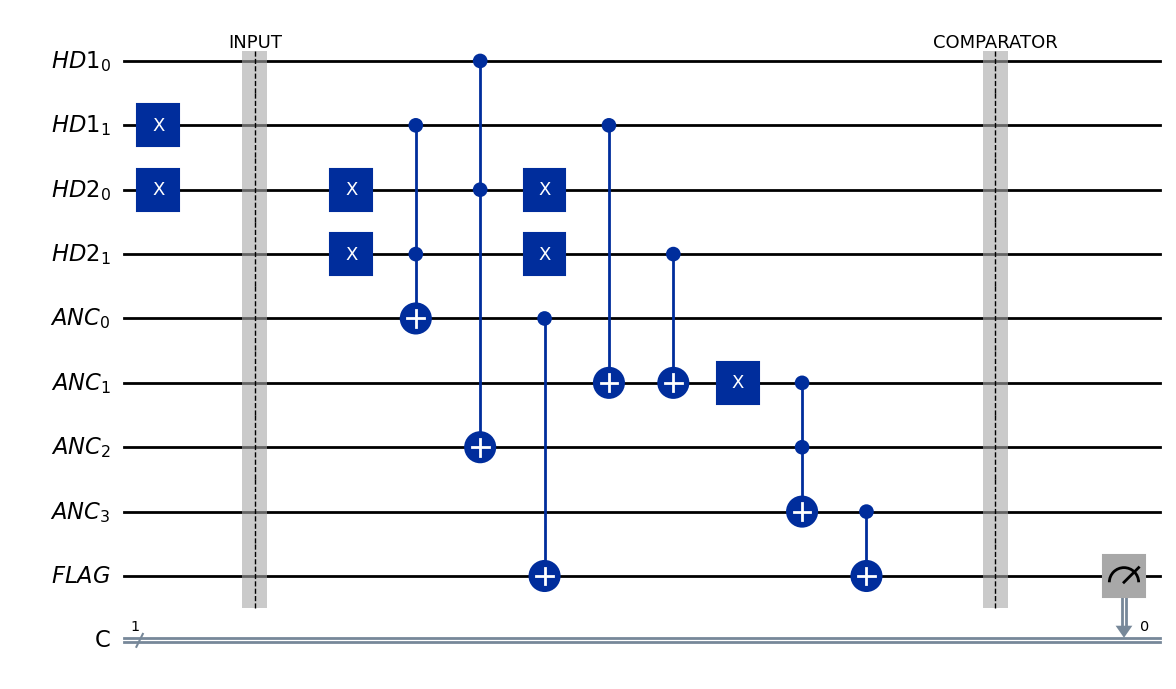

qiskit_runtime_service.__init__:WARNING:2026-10-02 00:51:41,353: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-10-02 00:51:41,363: Using instance: student-ashokp25, plan: open



Backend : ibm_kingston

========== IBM HARDWARE METRICS ==========

Backend       : ibm_kingston
Circuit Depth : 78
Circuit Width : 157
Total Qubits  : 156
Circuit Size  : 171

Gate Counts:

OrderedDict([('sx', 71), ('rz', 58), ('cz', 37), ('x', 4), ('barrier', 2), ('measure', 1)])

IBM RUNTIME JOB SUBMITTED
Job ID : davb5j492g1c7398k5ig

Waiting for execution...

Execution Complete.

Returned Data Structure:

DataBin(C=BitArray(<shape=(), num_shots=1024, num_bits=1>))

========== COMPARATOR RAW COUNTS ==========

{'1': 902, '0': 122}

========== SUCCESS PROBABILITY ==========

Success : 902/1024 = 88.09%

========== COMPARATOR HISTOGRAM ==========



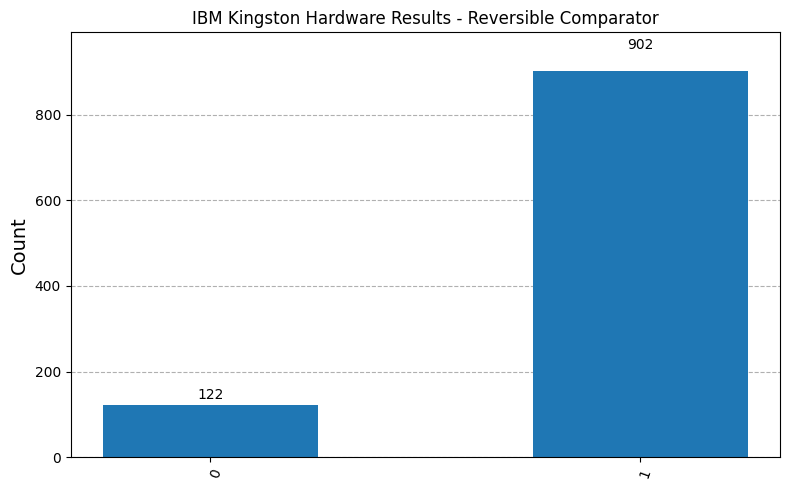


========== EXPECTED OUTPUT ==========

HD1 = 01 (decimal 1)
HD2 = 10 (decimal 2)
Expected FLAG = 1

Execution completed successfully on IBM Kingston.


In [7]:

# ============================================================
# REVERSIBLE COMPARATOR NETWORK
# IBM KINGSTON HARDWARE EXECUTION
# ============================================================

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister
)

from qiskit.visualization import plot_histogram

from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    SamplerV2 as Sampler
)

from qiskit.transpiler import generate_preset_pass_manager

from IPython.display import display

import matplotlib.pyplot as plt

# ============================================================
# REGISTERS
# ============================================================

HD1 = QuantumRegister(2, "HD1")
HD2 = QuantumRegister(2, "HD2")
ANC = QuantumRegister(4, "ANC")
FLAG = QuantumRegister(1, "FLAG")

C = ClassicalRegister(1, "C")

# ============================================================
# CIRCUIT
# ============================================================

qc = QuantumCircuit(
    HD1,
    HD2,
    ANC,
    FLAG,
    C
)

# ============================================================
# INPUT
#
# HD1 = 10
# HD2 = 01
#
# FLAG should become 1
# ============================================================

qc.x(HD1[1])

qc.x(HD2[0])

qc.barrier(label="INPUT")

# ============================================================
# REVERSIBLE COMPARATOR
# ============================================================

# -------------------------
# Compare MSB
# -------------------------

qc.x(HD2[1])

qc.ccx(
    HD1[1],
    HD2[1],
    ANC[0]
)

qc.x(HD2[1])

# -------------------------
# Equality Check
# -------------------------

qc.cx(HD1[1], ANC[1])
qc.cx(HD2[1], ANC[1])

qc.x(ANC[1])

# -------------------------
# Compare LSB
# -------------------------

qc.x(HD2[0])

qc.ccx(
    HD1[0],
    HD2[0],
    ANC[2]
)

qc.x(HD2[0])

# -------------------------
# Final Combination
# -------------------------

qc.ccx(
    ANC[1],
    ANC[2],
    ANC[3]
)

qc.cx(ANC[0], FLAG[0])

qc.cx(ANC[3], FLAG[0])

qc.barrier(label="COMPARATOR")

# ============================================================
# MEASURE
# ============================================================

qc.measure(FLAG, C)

# ============================================================
# DRAW CIRCUIT
# ============================================================

print("\n========== COMPARATOR CIRCUIT ==========\n")

fig = qc.draw(
    output="mpl",
    fold=120,
    idle_wires=False,
    style="iqp"
)

display(fig)

plt.show()

fig.savefig(
    "comparator_circuit.png",
    dpi=300,
    bbox_inches="tight"
)

# ============================================================
# IBM QUANTUM
# ============================================================

service = QiskitRuntimeService()

backend = service.backend("ibm_kingston")

print("\n====================================================")
print("Backend :", backend.name)
print("====================================================")

# ============================================================
# HARDWARE-AWARE TRANSPILATION
# ============================================================

pm = generate_preset_pass_manager(
    optimization_level=3,
    backend=backend
)

transpiled_qc = pm.run(qc)

# ============================================================
# HARDWARE METRICS
# ============================================================

print("\n========== IBM HARDWARE METRICS ==========\n")

print("Backend       :", backend.name)
print("Circuit Depth :", transpiled_qc.depth())
print("Circuit Width :", transpiled_qc.width())
print("Total Qubits  :", backend.num_qubits)
print("Circuit Size  :", transpiled_qc.size())

print("\nGate Counts:\n")

print(transpiled_qc.count_ops())

# ============================================================
# IBM RUNTIME
# ============================================================

sampler = Sampler(mode=backend)

job = sampler.run(
    [transpiled_qc],
    shots=1024
)

print("\n====================================================")
print("IBM RUNTIME JOB SUBMITTED")
print("====================================================")

print("Job ID :", job.job_id())

print("\nWaiting for execution...\n")

result = job.result()

print("Execution Complete.")

# ============================================================
# EXTRACT COUNTS
# ============================================================

pub = result[0]

print("\nReturned Data Structure:\n")

print(pub.data)

counts = pub.data.C.get_counts()

# ============================================================
# RAW COUNTS
# ============================================================

print("\n========== COMPARATOR RAW COUNTS ==========\n")

print(counts)

# ============================================================
# SUCCESS PROBABILITY
# ============================================================

expected = "1"

success = counts.get(expected, 0)

shots = sum(counts.values())

print("\n========== SUCCESS PROBABILITY ==========\n")

print(
    f"Success : {success}/{shots} = {100*success/shots:.2f}%"
)

# ============================================================
# HISTOGRAM
# ============================================================

print("\n========== COMPARATOR HISTOGRAM ==========\n")

hist = plot_histogram(
    counts,
    figsize=(8,5),
    title="IBM Kingston Hardware Results - Reversible Comparator"
)

display(hist)

hist.savefig(
    "ibm_comparator_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# EXPECTED OUTPUT
# ============================================================

print("\n========== EXPECTED OUTPUT ==========\n")

print("HD1 = 01 (decimal 1)")
print("HD2 = 10 (decimal 2)")
print("Expected FLAG = 1")

print("\nExecution completed successfully on IBM Kingston.")


In [8]:
#####fredkin selection

SyntaxError: invalid syntax (252272913.py, line 1)


========== FREDKIN ROUTING CIRCUIT ==========



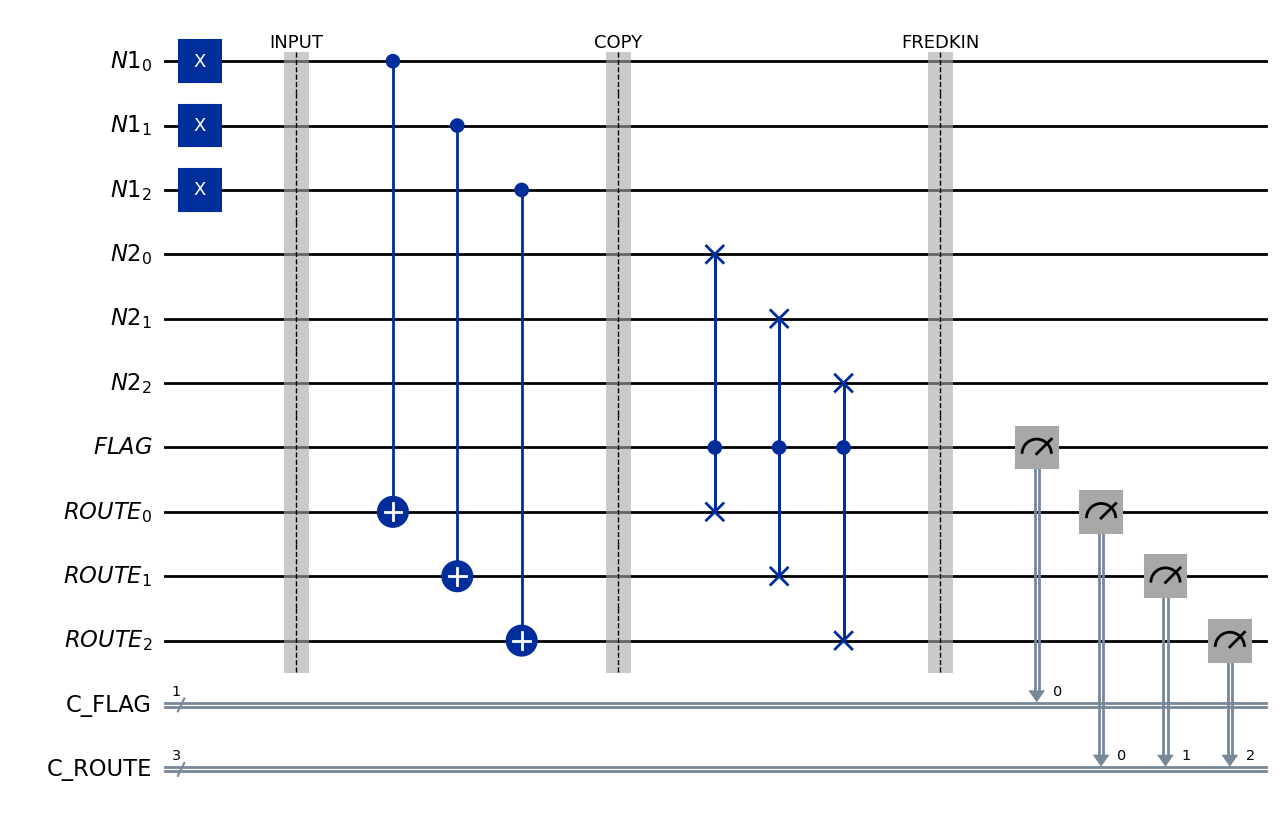

qiskit_runtime_service.__init__:WARNING:2026-10-02 00:52:51,032: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-10-02 00:52:51,032: Using instance: student-ashokp25, plan: open



Backend : ibm_kingston

========== IBM HARDWARE METRICS ==========

Backend       : ibm_kingston
Circuit Depth : 100
Circuit Width : 160
Total Qubits  : 156
Circuit Size  : 157

Gate Counts:

OrderedDict([('sx', 64), ('rz', 49), ('cz', 37), ('measure', 4), ('x', 3), ('barrier', 3)])

IBM RUNTIME JOB SUBMITTED
Job ID : davb64lj371s73dmk6f0

Waiting for execution...

Execution Complete.

Returned Data Structure:

DataBin(C_FLAG=BitArray(<shape=(), num_shots=1024, num_bits=1>), C_ROUTE=BitArray(<shape=(), num_shots=1024, num_bits=3>))

========== FLAG RAW COUNTS ==========

{'0': 895, '1': 129}

========== ROUTE RAW COUNTS ==========

{'010': 8, '111': 693, '011': 54, '000': 100, '110': 112, '101': 34, '100': 16, '001': 7}

========== SUCCESS PROBABILITY ==========

FLAG  : 895/1024 = 87.40%
ROUTE : 693/1024 = 67.68%

========== FLAG HISTOGRAM ==========



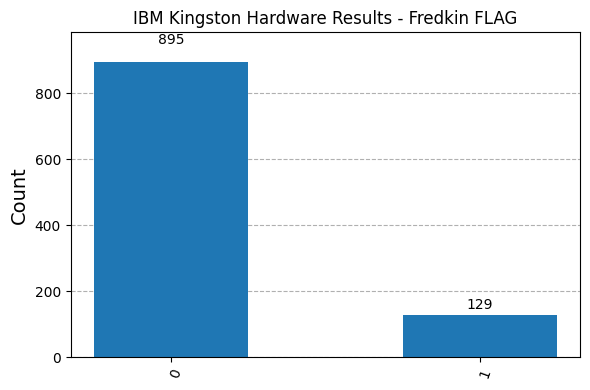


========== ROUTE HISTOGRAM ==========



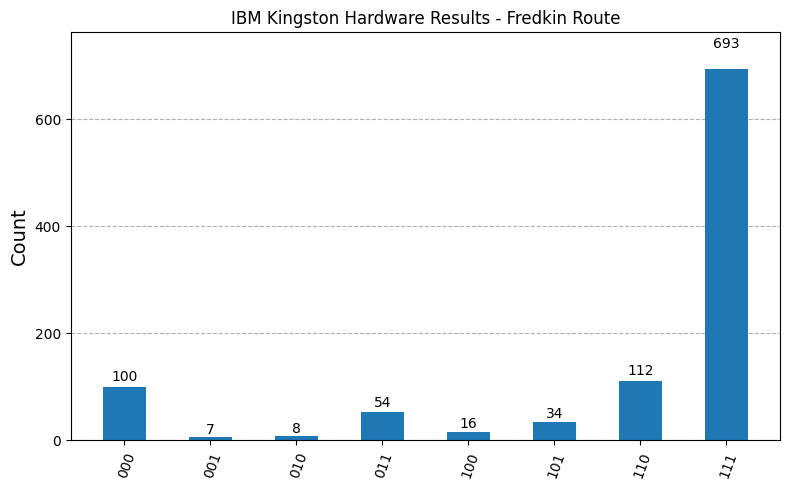


========== EXPECTED OUTPUT ==========

Destination : 101
Neighbor 1  : 111
Neighbor 2  : 000

Comparator FLAG : 0

Expected Route : 111


In [8]:

# ============================================================
# FREDKIN-BASED REVERSIBLE ROUTING
# IBM KINGSTON HARDWARE EXECUTION
# ============================================================

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister
)

from qiskit.visualization import plot_histogram

from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    SamplerV2 as Sampler
)

from qiskit.transpiler import generate_preset_pass_manager

from IPython.display import display

import matplotlib.pyplot as plt

# ============================================================
# REGISTERS
# ============================================================

N1 = QuantumRegister(3,"N1")
N2 = QuantumRegister(3,"N2")
FLAG = QuantumRegister(1,"FLAG")
ROUTE = QuantumRegister(3,"ROUTE")

C_FLAG = ClassicalRegister(1,"C_FLAG")
C_ROUTE = ClassicalRegister(3,"C_ROUTE")

# ============================================================
# CIRCUIT
# ============================================================

qc = QuantumCircuit(
    N1,
    N2,
    FLAG,
    ROUTE,
    C_FLAG,
    C_ROUTE
)

# ============================================================
# INPUT
#
# D  = 101
# N1 = 111
# N2 = 000
#
# Comparator Output
#
# FLAG = 0
#
# Expected ROUTE = 111
# ============================================================

# FLAG = 0
# (No X gate on FLAG)

# N1 = 111

qc.x(N1[0])
qc.x(N1[1])
qc.x(N1[2])

# N2 = 000
# (No initialization required)

qc.barrier(label="INPUT")

# ============================================================
# INITIAL COPY
# ============================================================

for i in range(3):
    qc.cx(N1[i], ROUTE[i])

qc.barrier(label="COPY")

# ============================================================
# FREDKIN ROUTING
# ============================================================

for i in range(3):
    qc.cswap(
        FLAG[0],
        ROUTE[i],
        N2[i]
    )

qc.barrier(label="FREDKIN")

# ============================================================
# MEASUREMENTS
# ============================================================

qc.measure(FLAG,C_FLAG)

qc.measure(ROUTE,C_ROUTE)

# ============================================================
# DRAW CIRCUIT
# ============================================================

print("\n========== FREDKIN ROUTING CIRCUIT ==========\n")

fig = qc.draw(
    output="mpl",
    fold=120,
    idle_wires=False,
    style="iqp"
)

display(fig)

plt.show()

fig.savefig(
    "fredkin_routing_circuit.png",
    dpi=300,
    bbox_inches="tight"
)

# ============================================================
# IBM QUANTUM
# ============================================================

service = QiskitRuntimeService()

backend = service.backend("ibm_kingston")

print("\n====================================================")
print("Backend :", backend.name)
print("====================================================")

# ============================================================
# TRANSPILATION
# ============================================================

pm = generate_preset_pass_manager(
    optimization_level=3,
    backend=backend
)

transpiled_qc = pm.run(qc)

# ============================================================
# HARDWARE METRICS
# ============================================================

print("\n========== IBM HARDWARE METRICS ==========\n")

print("Backend       :",backend.name)
print("Circuit Depth :",transpiled_qc.depth())
print("Circuit Width :",transpiled_qc.width())
print("Total Qubits  :",backend.num_qubits)
print("Circuit Size  :",transpiled_qc.size())

print("\nGate Counts:\n")

print(transpiled_qc.count_ops())

# ============================================================
# IBM RUNTIME
# ============================================================

sampler = Sampler(mode=backend)

job = sampler.run(
    [transpiled_qc],
    shots=1024
)

print("\n====================================================")
print("IBM RUNTIME JOB SUBMITTED")
print("====================================================")

print("Job ID :",job.job_id())

print("\nWaiting for execution...\n")

result = job.result()

print("Execution Complete.")

# ============================================================
# DATA
# ============================================================

pub = result[0]

print("\nReturned Data Structure:\n")

print(pub.data)

flag_counts = pub.data.C_FLAG.get_counts()

route_counts = pub.data.C_ROUTE.get_counts()

# ============================================================
# RAW COUNTS
# ============================================================

print("\n========== FLAG RAW COUNTS ==========\n")

print(flag_counts)

print("\n========== ROUTE RAW COUNTS ==========\n")

print(route_counts)

# ============================================================
# SUCCESS PROBABILITY
# ============================================================
expected_flag="0"

expected_route="111"

flag_success=flag_counts.get(expected_flag,0)

route_success=route_counts.get(expected_route,0)

flag_total=sum(flag_counts.values())

route_total=sum(route_counts.values())

print("\n========== SUCCESS PROBABILITY ==========\n")

print(
    f"FLAG  : {flag_success}/{flag_total} = {100*flag_success/flag_total:.2f}%"
)

print(
    f"ROUTE : {route_success}/{route_total} = {100*route_success/route_total:.2f}%"
)

# ============================================================
# FLAG HISTOGRAM
# ============================================================

print("\n========== FLAG HISTOGRAM ==========\n")

flag_fig=plot_histogram(
    flag_counts,
    figsize=(6,4),
    title="IBM Kingston Hardware Results - Fredkin FLAG"
)

display(flag_fig)

flag_fig.savefig(
    "ibm_fredkin_flag_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# ROUTE HISTOGRAM
# ============================================================

print("\n========== ROUTE HISTOGRAM ==========\n")

route_fig=plot_histogram(
    route_counts,
    figsize=(8,5),
    title="IBM Kingston Hardware Results - Fredkin Route"
)

display(route_fig)

route_fig.savefig(
    "ibm_fredkin_route_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# EXPECTED OUTPUT
# ============================================================

print("\n========== EXPECTED OUTPUT ==========\n")
print("Destination : 101")
print("Neighbor 1  : 111")
print("Neighbor 2  : 000")

print()

print("Comparator FLAG : 0")

print()

print("Expected Route : 111")

In [9]:
# IBM Kingston 512-case batch validation scaffold
from itertools import product
import csv
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler import generate_preset_pass_manager

SHOTS=256
BATCH_SIZE=64

# Paste your existing initialize_bits(), router(), and hamming() functions ABOVE this section.
# =========================
# HELPER
# =========================
def initialize_bits(qc, reg, bitstring):
    for i, b in enumerate(reversed(bitstring)):
        if b == '1':
            qc.x(reg[i])


# =========================
# ROUTER (FULL REVERSIBLE)
# =========================
def router(D_val, N1_val, N2_val):

    D  = QuantumRegister(3, 'D')
    N1 = QuantumRegister(3, 'N1')
    N2 = QuantumRegister(3, 'N2')

    X1 = QuantumRegister(3, 'X1')
    X2 = QuantumRegister(3, 'X2')

    d1 = QuantumRegister(2, 'd1')
    d2 = QuantumRegister(2, 'd2')

    anc = QuantumRegister(9, 'anc')
    flag = QuantumRegister(1, 'flag')

    OUT = QuantumRegister(3, 'OUT')
    c = ClassicalRegister(3, 'c')

    qc = QuantumCircuit(D, N1, N2, X1, X2, d1, d2, anc, flag, OUT, c)

    # INPUT
    initialize_bits(qc, D, D_val)
    initialize_bits(qc, N1, N1_val)
    initialize_bits(qc, N2, N2_val)

    # XOR
    for i in range(3):
        qc.cx(N1[i], X1[i])
        qc.cx(D[i],  X1[i])

        qc.cx(N2[i], X2[i])
        qc.cx(D[i],  X2[i])

    # POPCOUNT d1
    qc.cx(X1[0], d1[0])
    qc.cx(X1[1], d1[0])
    qc.cx(X1[2], d1[0])

    qc.ccx(X1[0], X1[1], anc[0])
    qc.ccx(X1[0], X1[2], anc[1])
    qc.ccx(X1[1], X1[2], anc[2])

    qc.cx(anc[0], d1[1])
    qc.cx(anc[1], d1[1])
    qc.cx(anc[2], d1[1])

    # POPCOUNT d2
    qc.cx(X2[0], d2[0])
    qc.cx(X2[1], d2[0])
    qc.cx(X2[2], d2[0])

    qc.ccx(X2[0], X2[1], anc[3])
    qc.ccx(X2[0], X2[2], anc[4])
    qc.ccx(X2[1], X2[2], anc[5])

    qc.cx(anc[3], d2[1])
    qc.cx(anc[4], d2[1])
    qc.cx(anc[5], d2[1])

    # =========================
    # COMPARATOR (d1 > d2)
    # =========================
    qc.x(d2[1])
    qc.ccx(d1[1], d2[1], flag[0])
    qc.x(d2[1])

    qc.cx(d1[1], anc[6])
    qc.cx(d2[1], anc[6])
    qc.x(anc[6])

    qc.x(d2[0])
    qc.ccx(d1[0], d2[0], anc[7])
    qc.x(d2[0])

    qc.ccx(anc[6], anc[7], anc[8])
    qc.cx(anc[8], flag[0])

    # =========================
    # SELECTION
    # =========================
    for i in range(3):
        qc.ccx(flag[0], N2[i], OUT[i])
        qc.x(flag[0])
        qc.ccx(flag[0], N1[i], OUT[i])
        qc.x(flag[0])

    # =========================
    # UNCOMPUTE
    # =========================

    qc.cx(anc[8], flag[0])
    qc.ccx(anc[6], anc[7], anc[8])

    qc.x(d2[0])
    qc.ccx(d1[0], d2[0], anc[7])
    qc.x(d2[0])

    qc.x(anc[6])
    qc.cx(d2[1], anc[6])
    qc.cx(d1[1], anc[6])

    qc.x(d2[1])
    qc.ccx(d1[1], d2[1], flag[0])
    qc.x(d2[1])

    qc.cx(anc[5], d2[1])
    qc.cx(anc[4], d2[1])
    qc.cx(anc[3], d2[1])

    qc.ccx(X2[1], X2[2], anc[5])
    qc.ccx(X2[0], X2[2], anc[4])
    qc.ccx(X2[0], X2[1], anc[3])

    qc.cx(X2[2], d2[0])
    qc.cx(X2[1], d2[0])
    qc.cx(X2[0], d2[0])

    qc.cx(anc[2], d1[1])
    qc.cx(anc[1], d1[1])
    qc.cx(anc[0], d1[1])

    qc.ccx(X1[1], X1[2], anc[2])
    qc.ccx(X1[0], X1[2], anc[1])
    qc.ccx(X1[0], X1[1], anc[0])

    qc.cx(X1[2], d1[0])
    qc.cx(X1[1], d1[0])
    qc.cx(X1[0], d1[0])

    for i in range(3):
        qc.cx(D[i],  X2[i])
        qc.cx(N2[i], X2[i])

        qc.cx(D[i],  X1[i])
        qc.cx(N1[i], X1[i])

    # MEASURE
    for i in range(3):
        qc.measure(OUT[i], c[i])

    return qc


# =========================
# TEST FUNCTIONS
# =========================
def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))


def run_test(D, N1, N2):

    qc = router(D, N1, N2)

    backend = Aer.get_backend('aer_simulator')
    backend.set_options(method="matrix_product_state")

    result = backend.run(qc, shots=1).result()
    measured = list(result.get_counts().keys())[0]

    d1 = hamming(D, N1)
    d2 = hamming(D, N2)

    expected = N2 if d1 > d2 else N1

    print("====================================")
    print(f"D={D}  N1={N1}  N2={N2}")
    print(f"Expected: {expected}")
    print(f"Measured: {measured}")

    if measured == expected:
        print("✔ PASS")
    else:
        print("❌ FAIL")
def chunks(lst,n):
    for i in range(0,len(lst),n):
        yield lst[i:i+n]

def build_all_cases():
    circuits=[]; expected=[]; metadata=[]
    for D in product("01", repeat=3):
        for N1 in product("01", repeat=3):
            for N2 in product("01", repeat=3):
                D="".join(D); N1="".join(N1); N2="".join(N2)
                qc=router(D,N1,N2)
                d1=hamming(D,N1); d2=hamming(D,N2)
                exp=N2 if d1>d2 else N1
                circuits.append(qc); expected.append(exp); metadata.append((D,N1,N2))
    return circuits,expected,metadata

def run_all_512_ibm():
    circuits,expected,metadata=build_all_cases()
    service=QiskitRuntimeService()
    backend=service.backend("ibm_kingston")
    pm=generate_preset_pass_manager(optimization_level=3, backend=backend)
    rows=[]; passed=0; total=0
    for b,batch in enumerate(chunks(list(range(len(circuits))),BATCH_SIZE),1):
        print(f"Batch {b}")
        trans=pm.run([circuits[i] for i in batch])
        sampler=Sampler(mode=backend)
        job=sampler.run(trans, shots=SHOTS)
        print("Job:",job.job_id())
        res=job.result()
        for li,gi in enumerate(batch):
            counts=res[li].data.c.get_counts()  # adjust if register name differs
            dom=max(counts,key=counts.get)
            prob=counts[dom]/SHOTS
            ok=(dom==expected[gi])
            if ok: passed+=1
            total+=1
            D,N1,N2=metadata[gi]
            rows.append([gi+1,D,N1,N2,expected[gi],dom,prob,"PASS" if ok else "FAIL"])
    with open("ibm_kingston_512_results.csv","w",newline="") as f:
        w=csv.writer(f)
        w.writerow(["Case","D","N1","N2","Expected","Dominant","Probability","Status"])
        w.writerows(rows)
    print("Total",total,"Passed",passed,"Accuracy",100*passed/total)

if __name__=="__main__":
    run_all_512_ibm()


qiskit_runtime_service.__init__:WARNING:2026-10-02 00:54:11,774: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-10-02 00:54:11,774: Using instance: student-ashokp25, plan: open


Batch 1
Job: davb6sg4oijs73e7956g
Batch 2
Job: davb76c92g1c7398k7mg
Batch 3
Job: davb7eil7guc73cek700
Batch 4
Job: davb7mk92g1c7398k8d0
Batch 5
Job: davb7v04oijs73e796e0
Batch 6
Job: davb87k92g1c7398k8u0
Batch 7
Job: davb8fdj371s73dmk9c0
Batch 8
Job: davb8n492g1c7398k9k0
Total 512 Passed 462 Accuracy 90.234375


In [12]:
from qiskit_ibm_runtime import QiskitRuntimeService

print(QiskitRuntimeService.saved_accounts().keys())

dict_keys(['classroom_account', 'default-ibm-cloud', 'default-ibm-quantum-platform', 'my_account'])


In [13]:
from qiskit_ibm_runtime import QiskitRuntimeService
import json

accounts = QiskitRuntimeService.saved_accounts()

for name, details in accounts.items():
    print(f"\n--- {name} ---")
    print(json.dumps({
        k: (
            "<redacted>"
            if any(word in k.lower()
                   for word in ["token", "key", "secret", "password"])
            else v
        )
        for k, v in details.items()
    }, indent=2, default=str))


--- classroom_account ---
{
  "channel": "ibm_cloud",
  "url": "https://cloud.ibm.com",
  "token": "<redacted>",
  "instance": "crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4fba757b-360b-49b3-b9e2-b5670351edb2::",
  "verify": true,
  "private_endpoint": false
}

--- default-ibm-cloud ---
{
  "channel": "ibm_cloud",
  "url": "https://cloud.ibm.com",
  "token": "<redacted>",
  "verify": true,
  "private_endpoint": false
}

--- default-ibm-quantum-platform ---
{
  "channel": "ibm_quantum_platform",
  "url": "https://cloud.ibm.com",
  "token": "<redacted>",
  "verify": true,
  "private_endpoint": false
}

--- my_account ---
{
  "channel": "ibm_cloud",
  "url": "https://cloud.ibm.com",
  "token": "<redacted>",
  "instance": "crn:v1:bluemix:public:quantum-computing:us-east:a/818f00603f1e467d906b566d263bc912:2fd4666c-2ff6-420f-9da5-d676c428b33a::",
  "verify": true,
  "private_endpoint": false,
  "region": "us-east",
  "plans_preference": [
    "open",
 

In [14]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_cloud",
    name="classroom_account"
)

print("Account authenticated successfully.")
print("Active instance:", service.active_instance())

backend = service.backend("ibm_kingston")
print("Backend:", backend.name)
print("Physical qubits:", backend.num_qubits)

qiskit_runtime_service._discover_account:WARNING:2026-10-02 01:41:08,384: Loading account with name classroom_account. Any input 'channel', 'token' or 'url' are ignored.


Account authenticated successfully.
Active instance: crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4fba757b-360b-49b3-b9e2-b5670351edb2::
Backend: ibm_kingston
Physical qubits: 156


In [15]:

from qiskit_ibm_runtime import QiskitRuntimeService
from datetime import datetime, timezone
from pathlib import Path
import json
import csv

# Connect explicitly to the verified Classroom account
service = QiskitRuntimeService(
    channel="ibm_cloud",
    name="classroom_account"
)

backend = service.backend("ibm_kingston")

# Retrieve current backend properties
props = backend.properties()

if props is None:
    raise RuntimeError("Calibration properties are unavailable.")

out_dir = Path("kingston_calibration_evidence")
out_dir.mkdir(exist_ok=True)

# Save the full properties snapshot
with open(out_dir / "backend_properties.json", "w") as f:
    json.dump(props.to_dict(), f, indent=2, default=str)

# Record retrieval and calibration-update timestamps separately
summary = {
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "backend": backend.name,
    "physical_qubits": backend.num_qubits,
    "active_instance": service.active_instance(),
    "properties_last_update_date": str(
        getattr(props, "last_update_date", None)
    ),
}

with open(out_dir / "calibration_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

# Export per-qubit calibration data
with open(out_dir / "qubit_calibration.csv", "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=["qubit", "T1_seconds",
                       "T2_seconds", "readout_error"]
    )
    writer.writeheader()

    for q in range(backend.num_qubits):
        qdata = props.qubit_property(q)

        def get_value(name):
            item = qdata.get(name)
            if isinstance(item, (tuple, list)):
                return item[0] if item else None
            return item

        writer.writerow({
            "qubit": q,
            "T1_seconds": get_value("T1"),
            "T2_seconds": get_value("T2"),
            "readout_error": get_value("readout_error"),
        })

print("Calibration evidence saved to:", out_dir.resolve())
print(json.dumps(summary, indent=2, default=str))
print("Calibration update date:", props.last_update_date)


qiskit_runtime_service._discover_account:WARNING:2026-10-02 01:42:19,981: Loading account with name classroom_account. Any input 'channel', 'token' or 'url' are ignored.


Calibration evidence saved to: C:\Users\DELL\kingston_calibration_evidence
{
  "retrieved_at_utc": "2026-10-01T20:12:31.153377+00:00",
  "backend": "ibm_kingston",
  "physical_qubits": 156,
  "active_instance": "crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4fba757b-360b-49b3-b9e2-b5670351edb2::",
  "properties_last_update_date": "2026-10-02 01:04:29+05:30"
}
Calibration update date: 2026-10-02 01:04:29+05:30


In [17]:

import json
import csv
import statistics
from pathlib import Path

folder = Path(r"C:\Users\DELL\kingston_calibration_evidence")

# Read saved backend properties
with open(folder / "backend_properties.json", "r",
          encoding="utf-8") as f:
    properties = json.load(f)

print("Backend properties keys:")
print(list(properties.keys()))

# Read calibration CSV without pandas
with open(folder / "qubit_calibration.csv", "r",
          newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print("\nNumber of qubit rows:", len(rows))

columns = ["T1_seconds", "T2_seconds", "readout_error"]

for column in columns:
    values = []
    missing = 0

    for row in rows:
        try:
            value = float(row[column])
            if value == value:  # exclude NaN
                values.append(value)
            else:
                missing += 1
        except (ValueError, TypeError, KeyError):
            missing += 1

    print(f"\n{column}")
    print("Valid values:", len(values))
    print("Missing/invalid:", missing)

    if values:
        print("Mean:", statistics.mean(values))
        print("Minimum:", min(values))
        print("Maximum:", max(values))

print("\nCalibration inspection completed.")


Backend properties keys:
['backend_name', 'backend_version', 'last_update_date', 'qubits', 'gates', 'general', 'general_qlists']

Number of qubit rows: 156

T1_seconds
Valid values: 155
Missing/invalid: 1
Mean: 0.0002322621547274969
Minimum: 1.8496539695078972e-05
Maximum: 0.0004439793016261012

T2_seconds
Valid values: 155
Missing/invalid: 1
Mean: 0.00016424191879038817
Minimum: 1.6806438837263645e-05
Maximum: 0.0005613136958260426

readout_error
Valid values: 156
Missing/invalid: 0
Mean: 0.01876205053084936
Minimum: 0.00244140625
Maximum: 0.50244140625

Calibration inspection completed.


In [18]:

import csv
from pathlib import Path

folder = Path(r"C:\Users\DELL\kingston_calibration_evidence")

with open(folder / "qubit_calibration.csv",
          "r", newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

valid = []
for row in rows:
    try:
        valid.append((int(row["qubit"]),
                      float(row["readout_error"])))
    except (ValueError, TypeError):
        pass

print("Qubits with readout error >= 10%:")
for q, err in sorted(valid, key=lambda x: x[1], reverse=True):
    if err >= 0.10:
        print(f"Qubit {q}: {err:.6f} ({err * 100:.2f}%)")

print("\nHighest 10 readout errors:")
for q, err in sorted(valid, key=lambda x: x[1], reverse=True)[:10]:
    print(f"Qubit {q}: {err:.6f} ({err * 100:.2f}%)")


Qubits with readout error >= 10%:
Qubit 146: 0.502441 (50.24%)
Qubit 113: 0.217651 (21.77%)
Qubit 121: 0.202881 (20.29%)

Highest 10 readout errors:
Qubit 146: 0.502441 (50.24%)
Qubit 113: 0.217651 (21.77%)
Qubit 121: 0.202881 (20.29%)
Qubit 131: 0.061646 (6.16%)
Qubit 72: 0.059326 (5.93%)
Qubit 112: 0.050171 (5.02%)
Qubit 84: 0.039062 (3.91%)
Qubit 127: 0.038818 (3.88%)
Qubit 12: 0.037964 (3.80%)
Qubit 111: 0.037720 (3.77%)


In [19]:

import json
from pathlib import Path

path = Path(
    r"C:\Users\DELL\kingston_calibration_evidence\backend_properties.json"
)

with open(path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Backend:", data.get("backend_name"))
print("Backend properties last updated:", data.get("last_update_date"))

for q in [146, 113, 121]:
    print(f"\n--- Qubit {q} ---")

    for prop in data["qubits"][q]:
        if prop.get("name") in [
            "readout_error", "prob_meas0_prep1",
            "prob_meas1_prep0", "T1", "T2"
        ]:
            print({
                "name": prop.get("name"),
                "value": prop.get("value"),
                "unit": prop.get("unit"),
                "date": prop.get("date")
            })


Backend: ibm_kingston
Backend properties last updated: 2026-10-02 01:04:29+05:30

--- Qubit 146 ---
{'name': 'readout_error', 'value': 0.50244140625, 'unit': '', 'date': '2026-10-01 20:43:01+05:30'}
{'name': 'prob_meas0_prep1', 'value': 0.5146484375, 'unit': '', 'date': '2026-10-01 20:43:01+05:30'}
{'name': 'prob_meas1_prep0', 'value': 0.490234375, 'unit': '', 'date': '2026-10-01 20:43:01+05:30'}

--- Qubit 113 ---
{'name': 'T1', 'value': 166.76387893693254, 'unit': 'us', 'date': '2026-09-30 04:45:53+05:30'}
{'name': 'T2', 'value': 71.36843275194575, 'unit': 'us', 'date': '2026-10-01 05:49:16+05:30'}
{'name': 'readout_error', 'value': 0.2176513671875, 'unit': '', 'date': '2026-10-01 20:43:01+05:30'}
{'name': 'prob_meas0_prep1', 'value': 0.236572265625, 'unit': '', 'date': '2026-10-01 20:43:01+05:30'}
{'name': 'prob_meas1_prep0', 'value': 0.19873046875, 'unit': '', 'date': '2026-10-01 20:43:01+05:30'}

--- Qubit 121 ---
{'name': 'T1', 'value': 18.496539695078972, 'unit': 'us', 'date': '

In [22]:

from qiskit_ibm_runtime import QiskitRuntimeService
import json

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4be8a719-af03-4d65-87d6-ae9bdf7e27b8::"
)

job = service.job("davb8n492g1c7398k9k0")

print("Job ID:", job.job_id())
print("Status:", job.status())
print("Backend:", job.backend().name)

for method_name in ["creation_date", "running_date", "done_date"]:
    try:
        value = getattr(job, method_name)()
        print(f"{method_name}:", value)
    except Exception as exc:
        print(f"{method_name}: unavailable ({exc})")

print("\nJob inputs/metadata:")
try:
    print(json.dumps(job.inputs(), indent=2, default=str))
except Exception as exc:
    print("Job inputs unavailable:", exc)

result = job.result()
print("\nNumber of PUB results:", len(result))

for i, pub_result in enumerate(result):
    print(f"\nPUB {i}")
    print("Data register names:", list(pub_result.data.keys()))
    for name in pub_result.data.keys():
        register = getattr(pub_result.data, name)
        if hasattr(register, "get_counts"):
            counts = register.get_counts()
            print(f"Register {name}: {counts}")


Job ID: davb8n492g1c7398k9k0
Status: DONE
Backend: ibm_kingston
creation_date: unavailable ('datetime.datetime' object is not callable)
running_date: unavailable ('RuntimeJobV2' object has no attribute 'running_date')
done_date: unavailable ('RuntimeJobV2' object has no attribute 'done_date')

Job inputs/metadata:
Job inputs unavailable: 'dict' object is not callable

Number of PUB results: 64

PUB 0
Data register names: ['c']
Register c: {'001': 67, '000': 121, '100': 26, '101': 13, '010': 15, '011': 5, '110': 6, '111': 3}

PUB 1
Data register names: ['c']
Register c: {'001': 90, '100': 17, '111': 2, '010': 26, '110': 7, '000': 77, '101': 12, '011': 25}

PUB 2
Data register names: ['c']
Register c: {'101': 2, '000': 99, '010': 108, '100': 19, '110': 9, '001': 7, '011': 10, '111': 2}

PUB 3
Data register names: ['c']
Register c: {'000': 63, '010': 60, '001': 41, '011': 55, '101': 8, '110': 13, '100': 13, '111': 3}

PUB 4
Data register names: ['c']
Register c: {'000': 82, '011': 2, '110

In [23]:

from qiskit_ibm_runtime import QiskitRuntimeService
import json

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4be8a719-af03-4d65-87d6-ae9bdf7e27b8::"
)

job = service.job("davb8n492g1c7398k9k0")

print("Job ID:", job.job_id())
print("Backend:", job.backend().name)
print("Status:", job.status())
print("Creation date:", getattr(job, "creation_date", None))
print("Program ID:", getattr(job, "program_id", None))

inputs = getattr(job, "inputs", {})
print("\nInput keys:",
      list(inputs.keys()) if isinstance(inputs, dict) else type(inputs))

# Inspect the saved job inputs without printing credentials
for key, value in inputs.items() if isinstance(inputs, dict) else []:
    print(f"\n{key}:")
    if key.lower() in {"token", "api_key", "apikey", "secret"}:
        print("<redacted>")
    else:
        print(str(value)[:1500])


Job ID: davb8n492g1c7398k9k0
Backend: ibm_kingston
Status: DONE
Creation date: 2026-10-02 00:58:28.639192+05:30
Program ID: None

Input keys: ['options', 'pubs', 'support_qiskit', 'version']

options:
{}

pubs:
[[<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433E210>, array([], dtype=float64), 256], [<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433E710>, array([], dtype=float64), 256], [<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433EB10>, array([], dtype=float64), 256], [<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433EE90>, array([], dtype=float64), 256], [<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433F290>, array([], dtype=float64), 256], [<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433FA50>, array([], dtype=float64), 256], [<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002678433D090>, array([], dtype=float64), 256], [<qiskit.circuit.q

In [25]:

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4be8a719-af03-4d65-87d6-ae9bdf7e27b8::"
)

job = service.job("davb8n492g1c7398k9k0")

# inputs is a property, so do not use ()
inputs = job.inputs
pubs = inputs["pubs"]

print("Job:", job.job_id())
print("Backend:", job.backend().name)
print("Number of circuits:", len(pubs))

for i in [0, 1, 63]:
    circuit = pubs[i][0]

    print(f"\n--- Circuit {i} ---")
    print("Name:", circuit.name)
    print("Qubits:", circuit.num_qubits)
    print("Classical bits:", circuit.num_clbits)
    print("Depth:", circuit.depth())
    print("Operations:", circuit.count_ops())
    print("Has layout:", circuit.layout is not None)

    if circuit.layout is not None:
        try:
            print("Final index layout:",
                  circuit.layout.final_index_layout())
        except Exception as exc:
            print("Layout inspection error:", exc)


Job: davb8n492g1c7398k9k0
Backend: ibm_kingston
Number of circuits: 64

--- Circuit 0 ---
Name: circuit-497
Qubits: 156
Classical bits: 3
Depth: 790
Operations: OrderedDict([('sx', 1273), ('cz', 656), ('rz', 538), ('x', 8), ('measure', 3)])
Has layout: True
Final index layout: [69, 72, 39, 50, 75, 52, 57, 71, 33, 51, 74, 53, 67, 70, 34, 93, 94, 68, 79, 92, 91, 95, 78, 66, 47, 49, 73, 38, 58, 48, 55, 54]

--- Circuit 1 ---
Name: circuit-498
Qubits: 156
Classical bits: 3
Depth: 758
Operations: OrderedDict([('sx', 1334), ('cz', 672), ('rz', 569), ('x', 5), ('measure', 3)])
Has layout: True
Final index layout: [57, 48, 78, 37, 49, 51, 67, 46, 52, 45, 50, 71, 68, 47, 58, 53, 33, 69, 64, 39, 38, 54, 66, 65, 89, 72, 90, 73, 70, 44, 25, 29]

--- Circuit 63 ---
Name: circuit-560
Qubits: 156
Classical bits: 3
Depth: 809
Operations: OrderedDict([('sx', 1366), ('cz', 723), ('rz', 490), ('x', 11), ('measure', 3)])
Has layout: True
Final index layout: [88, 109, 72, 78, 111, 74, 106, 87, 71, 89, 110,

In [26]:

targets = {113, 121, 146}

for i, pub in enumerate(pubs):
    circuit = pub[0]
    layout = circuit.layout

    if layout is None:
        print(f"{circuit.name}: no layout")
        continue

    try:
        mapping = layout.final_index_layout()
        used = sorted(targets.intersection(mapping))
        print(
            f"{circuit.name}: "
            f"layout entries={len(mapping)}, "
            f"high-error qubits in mapping={used}"
        )
    except Exception as exc:
        print(f"{circuit.name}: layout check failed: {exc}")


circuit-497: layout entries=32, high-error qubits in mapping=[]
circuit-498: layout entries=32, high-error qubits in mapping=[]
circuit-499: layout entries=32, high-error qubits in mapping=[]
circuit-500: layout entries=32, high-error qubits in mapping=[]
circuit-501: layout entries=32, high-error qubits in mapping=[]
circuit-502: layout entries=32, high-error qubits in mapping=[]
circuit-503: layout entries=32, high-error qubits in mapping=[]
circuit-504: layout entries=32, high-error qubits in mapping=[]
circuit-505: layout entries=32, high-error qubits in mapping=[]
circuit-506: layout entries=32, high-error qubits in mapping=[]
circuit-507: layout entries=32, high-error qubits in mapping=[]
circuit-508: layout entries=32, high-error qubits in mapping=[]
circuit-509: layout entries=32, high-error qubits in mapping=[]
circuit-510: layout entries=32, high-error qubits in mapping=[]
circuit-511: layout entries=32, high-error qubits in mapping=[]
circuit-512: layout entries=32, high-err

In [27]:
targets = {113, 121, 146}
pubs = job.inputs["pubs"]

for i, pub in enumerate(pubs):
    circuit = pub[0]
    used_qubits = set()
    measured_qubits = set()

    for inst in circuit.data:
        for q in inst.qubits:
            qidx = circuit.find_bit(q).index
            used_qubits.add(qidx)

        if inst.operation.name == "measure":
            measured_qubits.add(
                circuit.find_bit(inst.qubits[0]).index
            )

    touched = sorted(targets & used_qubits)
    measured = sorted(targets & measured_qubits)

    if touched or measured:
        print(
            f"{circuit.name}: "
            f"high-error qubits touched={touched}, "
            f"measured={measured}"
        )

print("Verification completed.")

Verification completed.


In [30]:
from qiskit_ibm_runtime import QiskitRuntimeService
import csv
from datetime import datetime
from pathlib import Path

# ============================================================
# 1. IBM QUANTUM ACCOUNT
# ============================================================
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance=(
        "crn:v1:bluemix:public:quantum-computing:us-east:"
        "a/949b60e7380d4ae99e7cbf138c3fcf18:"
        "4be8a719-af03-4d65-87d6-ae9bdf7e27b8::"
    )
)

# ============================================================
# 2. JOBS AND HIGH-ERROR PHYSICAL QUBITS
# ============================================================
job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

high_error_qubits = {113, 121, 146}

# Output files are saved in the current working directory.
output_dir = Path.cwd()
circuit_csv = output_dir / "IBM_AllJobs_QubitUsage_Details.csv"
summary_csv = output_dir / "IBM_AllJobs_QubitUsage_Summary.csv"

circuit_rows = []
summary_rows = []

# ============================================================
# 3. PROCESS EACH JOB
# ============================================================
for job_id in job_ids:
    print("\n" + "=" * 75)
    print("JOB:", job_id)
    print("=" * 75)

    try:
        job = service.job(job_id)
        print("Status:", job.status())
        print("Backend:", job.backend().name)
        print("Created:", job.creation_date)

        # Runtime V2 inputs are accessed as a property.
        pubs = job.inputs["pubs"]

        total_circuits = 0
        circuits_with_target_use = 0
        circuits_measuring_target = 0

        job_used_qubits = set()
        job_measured_qubits = set()

        for pub_index, pub in enumerate(pubs):
            circuit = pub[0]
            total_circuits += 1

            # Physical wire indices in the transpiled circuit.
            used_qubits = set()
            measured_qubits = set()
            gate_qubits = set()
            measurement_map = {}

            for instruction in circuit.data:
                operation = instruction.operation

                if operation.name == "measure":
                    q_index = circuit.find_bit(
                        instruction.qubits[0]
                    ).index
                    c_index = circuit.find_bit(
                        instruction.clbits[0]
                    ).index

                    measured_qubits.add(q_index)
                    measurement_map[q_index] = c_index
                    used_qubits.add(q_index)

                else:
                    for qubit in instruction.qubits:
                        q_index = circuit.find_bit(qubit).index
                        used_qubits.add(q_index)
                        gate_qubits.add(q_index)

            job_used_qubits.update(used_qubits)
            job_measured_qubits.update(measured_qubits)

            touched_targets = sorted(
                high_error_qubits & used_qubits
            )
            gate_targets = sorted(
                high_error_qubits & gate_qubits
            )
            measured_targets = sorted(
                high_error_qubits & measured_qubits
            )

            if touched_targets:
                circuits_with_target_use += 1

            if measured_targets:
                circuits_measuring_target += 1

            # Mapping from original logical qubits to physical positions.
            layout_targets = []

            if circuit.layout is not None:
                try:
                    mapping = circuit.layout.final_index_layout()
                    layout_targets = sorted(
                        high_error_qubits & set(mapping)
                    )
                except Exception as layout_error:
                    layout_targets = []
                    print(
                        "Layout inspection warning:",
                        circuit.name,
                        str(layout_error)
                    )

            # Print details only when a target qubit is used.
            if touched_targets:
                print(
                    f"{circuit.name}: "
                    f"used={touched_targets}, "
                    f"gate-used={gate_targets}, "
                    f"measured={measured_targets}, "
                    f"layout-mapped={layout_targets}"
                )

            circuit_rows.append({
                "job_id": job_id,
                "circuit_name": circuit.name,
                "pub_index": pub_index,
                "num_qubits": circuit.num_qubits,
                "num_clbits": circuit.num_clbits,
                "depth": circuit.depth(),
                "used_target_qubits": ",".join(
                    map(str, touched_targets)
                ),
                "gate_target_qubits": ",".join(
                    map(str, gate_targets)
                ),
                "measured_target_qubits": ",".join(
                    map(str, measured_targets)
                ),
                "layout_target_qubits": ",".join(
                    map(str, layout_targets)
                ),
                "used_qubit_count": len(used_qubits),
                "measured_qubit_count": len(measured_qubits),
                "measurement_map": str(measurement_map),
            })

        # ----------------------------------------------------
        # 4. JOB SUMMARY
        # ----------------------------------------------------
        summary_rows.append({
            "job_id": job_id,
            "status": str(job.status()),
            "backend": job.backend().name,
            "creation_date": str(job.creation_date),
            "circuit_count": total_circuits,
            "circuits_using_target_qubits": circuits_with_target_use,
            "circuits_measuring_target_qubits": circuits_measuring_target,
            "target_qubits_used_anywhere": ",".join(
                map(str, sorted(high_error_qubits & job_used_qubits))
            ),
            "target_qubits_measured_anywhere": ",".join(
                map(str, sorted(high_error_qubits & job_measured_qubits))
            ),
            "result": (
                "TARGET QUBITS USED"
                if high_error_qubits & job_used_qubits
                else "NO TARGET-QUBIT INSTRUCTIONS FOUND"
            ),
        })

        print("\nJob summary:")
        print("Circuits checked:", total_circuits)
        print("Circuits touching target qubits:",
              circuits_with_target_use)
        print("Circuits measuring target qubits:",
              circuits_measuring_target)
        print("Target qubits used:",
              sorted(high_error_qubits & job_used_qubits))
        print("Target qubits measured:",
              sorted(high_error_qubits & job_measured_qubits))

    except Exception as error:
        print("ERROR processing job:", job_id)
        print(type(error).__name__, str(error))

        summary_rows.append({
            "job_id": job_id,
            "status": "ERROR",
            "backend": "",
            "creation_date": "",
            "circuit_count": 0,
            "circuits_using_target_qubits": 0,
            "circuits_measuring_target_qubits": 0,
            "target_qubits_used_anywhere": "",
            "target_qubits_measured_anywhere": "",
            "result": f"ERROR: {type(error).__name__}: {error}",
        })

# ============================================================
# 5. SAVE CIRCUIT-LEVEL CSV
# ============================================================
if circuit_rows:
    with open(circuit_csv, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file, fieldnames=list(circuit_rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(circuit_rows)

# ============================================================
# 6. SAVE JOB-LEVEL SUMMARY CSV
# ============================================================
if summary_rows:
    with open(summary_csv, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file, fieldnames=list(summary_rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(summary_rows)

# ============================================================
# 7. FINAL SUMMARY
# ============================================================
print("\n" + "=" * 75)
print("FINAL VERIFICATION")
print("=" * 75)

print("Jobs requested:", len(job_ids))
print("Jobs summarized:", len(summary_rows))
print("Circuits inspected:", len(circuit_rows))
print("High-error qubits checked:", sorted(high_error_qubits))

for row in summary_rows:
    print(
        row["job_id"],
        "|", row["result"],
        "| circuits:", row["circuit_count"],
        "| used:", row["target_qubits_used_anywhere"],
        "| measured:", row["target_qubits_measured_anywhere"],
    )

print("\nFiles saved:")
print(circuit_csv)
print(summary_csv)



JOB: davb6sg4oijs73e7956g
Status: DONE
Backend: ibm_kingston
Created: 2026-10-02 00:54:34.316171+05:30

Job summary:
Circuits checked: 64
Circuits touching target qubits: 0
Circuits measuring target qubits: 0
Target qubits used: []
Target qubits measured: []

JOB: davb76c92g1c7398k7mg
Status: DONE
Backend: ibm_kingston
Created: 2026-10-02 00:55:13.171260+05:30

Job summary:
Circuits checked: 64
Circuits touching target qubits: 0
Circuits measuring target qubits: 0
Target qubits used: []
Target qubits measured: []

JOB: davb7eil7guc73cek700
Status: DONE
Backend: ibm_kingston
Created: 2026-10-02 00:55:46.359365+05:30

Job summary:
Circuits checked: 64
Circuits touching target qubits: 0
Circuits measuring target qubits: 0
Target qubits used: []
Target qubits measured: []

JOB: davb7mk92g1c7398k8d0
Status: DONE
Backend: ibm_kingston
Created: 2026-10-02 00:56:18.120651+05:30

Job summary:
Circuits checked: 64
Circuits touching target qubits: 0
Circuits measuring target qubits: 0
Target qub

In [31]:

from qiskit_ibm_runtime import QiskitRuntimeService
from collections import Counter, defaultdict
from pathlib import Path
import csv
import json
from datetime import datetime, timezone

# ============================================================
# 1. CONNECT TO THE IBM QUANTUM INSTANCE USED FOR THESE JOBS
# ============================================================
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance=(
        "crn:v1:bluemix:public:quantum-computing:us-east:"
        "a/949b60e7380d4ae99e7cbf138c3fcf18:"
        "4be8a719-af03-4d65-87d6-ae9bdf7e27b8::"
    )
)

backend = service.backend("ibm_kingston")
props = backend.properties()

job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

out_dir = Path.cwd()
circuit_csv = out_dir / "IBM_PhysicalQubits_PerCircuit.csv"
qubit_csv = out_dir / "IBM_UsedQubits_Calibration.csv"
summary_csv = out_dir / "IBM_PhysicalQubit_Usage_Summary.csv"

# ============================================================
# 2. EXTRACT CURRENT CALIBRATION PROPERTIES
# ============================================================
calibration = {}

for physical_id, parameters in enumerate(props.qubits):
    values = {}
    dates = {}

    for parameter in parameters:
        name = parameter.name
        values[name] = parameter.value
        dates[name] = (
            str(parameter.date) if parameter.date is not None else ""
        )

    calibration[physical_id] = {
        "T1_seconds": values.get("T1"),
        "T2_seconds": values.get("T2"),
        "readout_error": values.get("readout_error"),
        "T1_date": dates.get("T1", ""),
        "T2_date": dates.get("T2", ""),
        "readout_error_date": dates.get("readout_error", ""),
    }

retrieved_utc = datetime.now(timezone.utc).isoformat()

print("Backend:", backend.name)
print("Physical qubits:", backend.num_qubits)
print("Calibration last-update date:", props.last_update_date)
print("Properties retrieved at UTC:", retrieved_utc)

# ============================================================
# 3. INSPECT ALL JOBS AND CIRCUITS
# ============================================================
circuit_rows = []
qubit_job_usage = defaultdict(set)
qubit_circuit_usage = Counter()
qubit_gate_usage = Counter()
qubit_measure_usage = Counter()
operation_counts_by_qubit = defaultdict(Counter)
measured_classical_bits = defaultdict(set)
job_rows = []

for job_id in job_ids:
    print("\nProcessing:", job_id)

    try:
        job = service.job(job_id)
        pubs = job.inputs["pubs"]

        job_used = set()
        job_gate_used = set()
        job_measured = set()
        job_circuit_count = 0

        for pub_index, pub in enumerate(pubs):
            circuit = pub[0]
            job_circuit_count += 1

            used = set()
            gate_used = set()
            measured = set()
            gate_counts = Counter()
            measurement_map = []

            for instruction in circuit.data:
                op = instruction.operation
                q_indices = [
                    circuit.find_bit(q).index
                    for q in instruction.qubits
                ]

                if op.name == "measure":
                    qidx = q_indices[0]
                    cidx = circuit.find_bit(
                        instruction.clbits[0]
                    ).index

                    used.add(qidx)
                    measured.add(qidx)
                    measurement_map.append((qidx, cidx))
                    measured_classical_bits[qidx].add(cidx)

                else:
                    for qidx in q_indices:
                        used.add(qidx)
                        gate_used.add(qidx)
                        operation_counts_by_qubit[qidx][op.name] += 1

                    gate_counts[op.name] += 1

            job_used.update(used)
            job_gate_used.update(gate_used)
            job_measured.update(measured)

            for qidx in used:
                qubit_job_usage[qidx].add(job_id)
                qubit_circuit_usage[qidx] += 1

            for qidx in gate_used:
                qubit_gate_usage[qidx] += 1

            for qidx in measured:
                qubit_measure_usage[qidx] += 1

            # Logical-to-physical layout mapping, if available.
            layout_map = []
            if circuit.layout is not None:
                try:
                    layout_map = circuit.layout.final_index_layout()
                except Exception:
                    layout_map = []

            circuit_rows.append({
                "job_id": job_id,
                "circuit_name": circuit.name,
                "pub_index": pub_index,
                "depth": circuit.depth(),
                "num_qubits": circuit.num_qubits,
                "num_clbits": circuit.num_clbits,
                "used_physical_indices": ",".join(map(str, sorted(used))),
                "gate_physical_indices": ",".join(map(str, sorted(gate_used))),
                "measured_physical_indices": ",".join(map(str, sorted(measured))),
                "measurement_qubit_to_clbit": json.dumps(measurement_map),
                "layout_logical_to_physical": json.dumps(layout_map),
                "operation_counts": json.dumps(dict(gate_counts)),
            })

        job_rows.append({
            "job_id": job_id,
            "status": str(job.status()),
            "backend": job.backend().name,
            "creation_date": str(job.creation_date),
            "circuits_checked": job_circuit_count,
            "unique_physical_qubits_touched": len(job_used),
            "unique_qubits_in_gates": len(job_gate_used),
            "unique_qubits_measured": len(job_measured),
            "physical_qubits_touched": ",".join(map(str, sorted(job_used))),
            "physical_qubits_in_gates": ",".join(map(str, sorted(job_gate_used))),
            "physical_qubits_measured": ",".join(map(str, sorted(job_measured))),
            "result": "OK",
        })

        print("Status:", job.status())
        print("Circuits:", job_circuit_count)
        print("Unique qubits touched:", len(job_used))
        print("Unique qubits in gates:", len(job_gate_used))
        print("Unique qubits measured:", len(job_measured))
        print("Physical qubits measured:", sorted(job_measured))

    except Exception as exc:
        print("ERROR:", job_id, type(exc).__name__, str(exc))
        job_rows.append({
            "job_id": job_id,
            "status": "ERROR",
            "backend": "",
            "creation_date": "",
            "circuits_checked": 0,
            "unique_physical_qubits_touched": 0,
            "unique_qubits_in_gates": 0,
            "unique_qubits_measured": 0,
            "physical_qubits_touched": "",
            "physical_qubits_in_gates": "",
            "physical_qubits_measured": "",
            "result": f"{type(exc).__name__}: {exc}",
        })

# ============================================================
# 4. CALIBRATION REPORT FOR QUbits ACTUALLY USED
# ============================================================
qubit_rows = []

for qidx in sorted(qubit_job_usage):
    cal = calibration.get(qidx, {})

    t1 = cal.get("T1_seconds")
    t2 = cal.get("T2_seconds")
    ro = cal.get("readout_error")

    qubit_rows.append({
        "physical_qubit": qidx,
        "jobs_using_qubit": len(qubit_job_usage[qidx]),
        "job_ids": ",".join(sorted(qubit_job_usage[qidx])),
        "circuit_uses": qubit_circuit_usage[qidx],
        "gate_instruction_uses": qubit_gate_usage[qidx],
        "measurement_uses": qubit_measure_usage[qidx],
        "T1_us": t1 * 1e6 if t1 is not None else None,
        "T2_us": t2 * 1e6 if t2 is not None else None,
        "readout_error_percent": ro * 100 if ro is not None else None,
        "readout_fidelity_percent": (1 - ro) * 100 if ro is not None else None,
        "T1_calibration_date": cal.get("T1_date", ""),
        "T2_calibration_date": cal.get("T2_date", ""),
        "readout_calibration_date": cal.get("readout_error_date", ""),
        "operation_counts": json.dumps(
            dict(operation_counts_by_qubit[qidx])
        ),
        "classical_bits_measured": ",".join(
            map(str, sorted(measured_classical_bits[qidx]))
        ),
    })

# ============================================================
# 5. WRITE CSV FILES
# ============================================================
def write_csv(path, rows):
    if not rows:
        print("No rows to write:", path)
        return

    with open(path, "w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

write_csv(circuit_csv, circuit_rows)
write_csv(qubit_csv, qubit_rows)
write_csv(summary_csv, job_rows)

# ============================================================
# 6. PRINT HIGH-READOUT-ERROR QUBITS AMONG THE USED QUBITS
# ============================================================
print("\n" + "=" * 75)
print("USED-QUBIT CALIBRATION REVIEW")
print("=" * 75)

valid_ro = [
    row["readout_error_percent"]
    for row in qubit_rows
    if row["readout_error_percent"] is not None
]

for row in sorted(
    qubit_rows,
    key=lambda r: (
        r["readout_error_percent"]
        if r["readout_error_percent"] is not None
        else -1
    ),
    reverse=True
):
    print(
        f"Qubit {row['physical_qubit']:3}: "
        f"readout error={row['readout_error_percent']}, "
        f"T1={row['T1_us']}, T2={row['T2_us']}, "
        f"measurements={row['measurement_uses']}, "
        f"gate uses={row['gate_instruction_uses']}"
    )

print("\nUnique physical qubits observed:", len(qubit_rows))
print("Circuit records:", len(circuit_rows))
print("Job records:", len(job_rows))

print("\nSaved reports:")
print(circuit_csv)
print(qubit_csv)
print(summary_csv)


Backend: ibm_kingston
Physical qubits: 156
Calibration last-update date: 2026-10-02 01:45:52+05:30
Properties retrieved at UTC: 2026-10-01T20:43:06.196534+00:00

Processing: davb6sg4oijs73e7956g
Status: DONE
Circuits: 64
Unique qubits touched: 72
Unique qubits in gates: 72
Unique qubits measured: 55
Physical qubits measured: [16, 25, 27, 28, 29, 30, 31, 32, 33, 37, 38, 39, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 63, 64, 65, 66, 67, 68, 69, 70, 71, 73, 74, 75, 78, 79, 87, 88, 89, 90, 91, 92, 93, 94, 95, 97, 98, 99, 108, 111]

Processing: davb76c92g1c7398k7mg
Status: DONE
Circuits: 64
Unique qubits touched: 76
Unique qubits in gates: 76
Unique qubits measured: 57
Physical qubits measured: [17, 21, 25, 26, 29, 32, 33, 34, 37, 38, 39, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 63, 64, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 77, 78, 79, 87, 88, 89, 90, 91, 92, 93, 94, 95, 97, 98, 105, 108, 109, 110, 111]

Processing: davb7eil7guc73cek700
Status: DONE
Cir

In [32]:

# Inspect raw calibration properties for selected physical qubits.
# Reuse the existing `backend` and `props` variables.

for qidx in [72, 127, 111, 32, 78, 146]:
    print(f"\nPhysical qubit {qidx}")

    for parameter in props.qubits[qidx]:
        if parameter.name in {
            "T1",
            "T2",
            "readout_error",
            "prob_meas0_prep1",
            "prob_meas1_prep0",
        }:
            print(
                "name =", parameter.name,
                "| raw value =", repr(parameter.value),
                "| date =", repr(parameter.date),
            )

print("\nBackend properties last_update_date:",
      repr(props.last_update_date))



Physical qubit 72
name = T1 | raw value = 257.44851690551957 | date = datetime.datetime(2026, 10, 1, 5, 48, 39, tzinfo=tzlocal())
name = T2 | raw value = 116.6584565394671 | date = datetime.datetime(2026, 10, 1, 5, 49, 33, tzinfo=tzlocal())
name = readout_error | raw value = 0.059326171875 | date = datetime.datetime(2026, 10, 1, 20, 43, 1, tzinfo=tzlocal())
name = prob_meas0_prep1 | raw value = 0.05224609375 | date = datetime.datetime(2026, 10, 1, 20, 43, 1, tzinfo=tzlocal())
name = prob_meas1_prep0 | raw value = 0.06640625 | date = datetime.datetime(2026, 10, 1, 20, 43, 1, tzinfo=tzlocal())

Physical qubit 127
name = T1 | raw value = 300.8146442316843 | date = datetime.datetime(2026, 10, 1, 5, 48, 54, tzinfo=tzlocal())
name = T2 | raw value = 322.1173560397564 | date = datetime.datetime(2026, 10, 1, 5, 49, 17, tzinfo=tzlocal())
name = readout_error | raw value = 0.038818359375 | date = datetime.datetime(2026, 10, 1, 20, 43, 1, tzinfo=tzlocal())
name = prob_meas0_prep1 | raw value = 0

In [35]:

# ============================================================
# FIXED: IBM KINGSTON CALIBRATION CONVERSIONS
# Compatible with list-based Qiskit BackendProperties
# ============================================================

import csv
import json
from pathlib import Path
from datetime import datetime, timezone

# Reuse the existing objects:
# service, backend, properties
# from your successfully connected notebook cell.

rows = []

def get_calibration_value(parameters, parameter_name):
    """Extract a calibration value from a list of parameter objects."""
    for parameter in parameters:
        if parameter.name == parameter_name:
            return parameter.value
    return None

def to_percent(value):
    return float(value) * 100 if value is not None else None

for qubit_index, parameters in enumerate(properties.qubits):

    t1 = get_calibration_value(parameters, "T1")
    t2 = get_calibration_value(parameters, "T2")

    readout_error = get_calibration_value(
        parameters, "readout_error"
    )
    p01 = get_calibration_value(
        parameters, "prob_meas0_prep1"
    )
    p10 = get_calibration_value(
        parameters, "prob_meas1_prep0"
    )

    t1 = float(t1) if t1 is not None else None
    t2 = float(t2) if t2 is not None else None
    readout_error = (
        float(readout_error) if readout_error is not None else None
    )
    p01 = float(p01) if p01 is not None else None
    p10 = float(p10) if p10 is not None else None

    rows.append({
        "physical_qubit": qubit_index,

        # T1 and T2 are already in microseconds.
        "T1_us": t1,
        "T1_ns": t1 * 1000 if t1 is not None else None,
        "T1_seconds": t1 * 1e-6 if t1 is not None else None,

        "T2_us": t2,
        "T2_ns": t2 * 1000 if t2 is not None else None,
        "T2_seconds": t2 * 1e-6 if t2 is not None else None,

        "readout_error_fraction": readout_error,
        "readout_error_percent": to_percent(readout_error),
        "readout_fidelity_fraction": (
            1 - readout_error if readout_error is not None else None
        ),
        "readout_fidelity_percent": (
            to_percent(1 - readout_error)
            if readout_error is not None else None
        ),

        "P_meas0_given_prep1_fraction": p01,
        "P_meas0_given_prep1_percent": to_percent(p01),
        "P_meas1_given_prep0_fraction": p10,
        "P_meas1_given_prep0_percent": to_percent(p10),

        "readout_asymmetry_percent": (
            to_percent(abs(p01 - p10))
            if p01 is not None and p10 is not None else None
        ),

        "T2_over_T1": (
            t2 / t1
            if t1 is not None and t1 != 0 and t2 is not None
            else None
        ),
    })

# ------------------------------------------------------------
# Export complete converted CSV
# ------------------------------------------------------------
output_dir = Path.cwd()
csv_path = output_dir / "IBM_Kingston_Calibration_Converted.csv"

with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

# ------------------------------------------------------------
# Save raw calibration snapshot
# ------------------------------------------------------------
raw_path = output_dir / "IBM_Kingston_Backend_Properties.json"

with raw_path.open("w", encoding="utf-8") as f:
    json.dump(properties.to_dict(), f, indent=2, default=str)

# ------------------------------------------------------------
# Print metadata and data-quality counts
# ------------------------------------------------------------
print("Backend:", backend.name)
print("Physical qubits:", backend.num_qubits)
print("Calibration update:", properties.last_update_date)
print("Retrieved UTC:", datetime.now(timezone.utc).isoformat())
print("Qubit records:", len(rows))
print("Qubits with T1:", sum(r["T1_us"] is not None for r in rows))
print("Qubits with T2:", sum(r["T2_us"] is not None for r in rows))
print("Qubits with readout error:",
      sum(r["readout_error_fraction"] is not None for r in rows))

print("\nTOP 10 QUBITS BY READOUT ERROR")
valid = [
    r for r in rows
    if r["readout_error_fraction"] is not None
]
worst = sorted(
    valid,
    key=lambda r: r["readout_error_fraction"],
    reverse=True
)

for r in worst[:10]:
    print(
        f"Qubit {r['physical_qubit']:3d} | "
        f"Readout error: {r['readout_error_percent']:.4f}% | "
        f"Fidelity: {r['readout_fidelity_percent']:.4f}% | "
        f"T1: {r['T1_us']} us | T2: {r['T2_us']} us"
    )

print("\nCSV saved:", csv_path.resolve())
print("Raw snapshot saved:", raw_path.resolve())
print("\nCalibration conversion completed.")


Backend: ibm_kingston
Physical qubits: 156
Calibration update: 2026-10-02 01:45:52+05:30
Retrieved UTC: 2026-10-01T20:52:45.179945+00:00
Qubit records: 156
Qubits with T1: 155
Qubits with T2: 155
Qubits with readout error: 156

TOP 10 QUBITS BY READOUT ERROR
Qubit 146 | Readout error: 50.2441% | Fidelity: 49.7559% | T1: None us | T2: None us
Qubit 113 | Readout error: 21.7651% | Fidelity: 78.2349% | T1: 166.76387893693254 us | T2: 71.36843275194575 us
Qubit 121 | Readout error: 20.2881% | Fidelity: 79.7119% | T1: 18.496539695078972 us | T2: 25.636631187774977 us
Qubit 131 | Readout error: 6.1646% | Fidelity: 93.8354% | T1: 66.07270112755594 us | T2: 56.8457970693481 us
Qubit  72 | Readout error: 5.9326% | Fidelity: 94.0674% | T1: 257.44851690551957 us | T2: 116.6584565394671 us
Qubit 112 | Readout error: 5.0171% | Fidelity: 94.9829% | T1: 169.650985683356 us | T2: 171.62280072976935 us
Qubit  84 | Readout error: 3.9062% | Fidelity: 96.0938% | T1: 215.67482687507675 us | T2: 59.47110796

In [36]:

from pathlib import Path
import csv

base = Path.cwd()

required_files = {
    "Calibration": "IBM_Kingston_Calibration_Converted.csv",
    "Qubit usage": "IBM_UsedQubits_Calibration.csv",
    "Physical-qubit summary": "IBM_PhysicalQubit_Usage_Summary.csv",
}

print("Working directory:", base)
print()

for label, filename in required_files.items():
    path = base / filename
    print(f"{label}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print("  Path:", path)

    if path.exists():
        with path.open("r", newline="", encoding="utf-8-sig") as f:
            reader = csv.DictReader(f)
            print("  Columns:", reader.fieldnames)
            print("  Sample rows:", list(next(iter([reader]), [])) if False else "")
    print()


Working directory: C:\Users\DELL

Calibration: FOUND
  Path: C:\Users\DELL\IBM_Kingston_Calibration_Converted.csv
  Columns: ['physical_qubit', 'T1_us', 'T1_ns', 'T1_seconds', 'T2_us', 'T2_ns', 'T2_seconds', 'readout_error_fraction', 'readout_error_percent', 'readout_fidelity_fraction', 'readout_fidelity_percent', 'P_meas0_given_prep1_fraction', 'P_meas0_given_prep1_percent', 'P_meas1_given_prep0_fraction', 'P_meas1_given_prep0_percent', 'readout_asymmetry_percent', 'T2_over_T1']
  Sample rows: 

Qubit usage: FOUND
  Path: C:\Users\DELL\IBM_UsedQubits_Calibration.csv
  Columns: ['physical_qubit', 'jobs_using_qubit', 'job_ids', 'circuit_uses', 'gate_instruction_uses', 'measurement_uses', 'T1_us', 'T2_us', 'readout_error_percent', 'readout_fidelity_percent', 'T1_calibration_date', 'T2_calibration_date', 'readout_calibration_date', 'operation_counts', 'classical_bits_measured']
  Sample rows: 

Physical-qubit summary: FOUND
  Path: C:\Users\DELL\IBM_PhysicalQubit_Usage_Summary.csv
  Colum

In [37]:

import csv
import ast
import json
import math
from pathlib import Path
from collections import defaultdict

base = Path(r"C:\Users\DELL")

cal_file = base / "IBM_Kingston_Calibration_Converted.csv"
usage_file = base / "IBM_UsedQubits_Calibration.csv"
jobs_file = base / "IBM_PhysicalQubit_Usage_Summary.csv"

def read_csv(path):
    with path.open("r", newline="", encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

def write_csv(path, rows):
    if not rows:
        print("No rows to save:", path.name)
        return
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)
    print("Saved:", path)

def number(value):
    try:
        if value is None or str(value).strip() in ("", "None", "N/A"):
            return None
        x = float(value)
        return x if math.isfinite(x) else None
    except (TypeError, ValueError):
        return None

def parse_qubit_list(value):
    """Parse a list of qubit IDs from common CSV representations."""
    if value is None:
        return []
    s = str(value).strip()
    if not s or s.lower() in ("none", "nan", "[]"):
        return []
    try:
        parsed = ast.literal_eval(s)
        if isinstance(parsed, (list, tuple, set)):
            return sorted(set(int(x) for x in parsed))
    except (ValueError, SyntaxError, TypeError):
        pass
    try:
        parsed = json.loads(s)
        if isinstance(parsed, list):
            return sorted(set(int(x) for x in parsed))
    except (ValueError, TypeError):
        pass
    # Fallback for strings such as "16, 17, 18"
    cleaned = s.strip("[](){}")
    result = []
    for item in cleaned.split(","):
        try:
            result.append(int(item.strip()))
        except ValueError:
            continue
    return sorted(set(result))

calibration = read_csv(cal_file)
usage = read_csv(usage_file)
jobs = read_csv(jobs_file)

# ------------------------------------------------------------
# 1. Merge the latest converted calibration into usage records
# ------------------------------------------------------------
cal_by_qubit = {
    int(r["physical_qubit"]): r for r in calibration
}

merged = []

for u in usage:
    q = int(u["physical_qubit"])
    c = cal_by_qubit.get(q, {})

    merged.append({
        "physical_qubit": q,
        "jobs_using_qubit": u.get("jobs_using_qubit", ""),
        "job_ids": u.get("job_ids", ""),
        "circuit_uses": u.get("circuit_uses", ""),
        "gate_instruction_uses": u.get("gate_instruction_uses", ""),
        "measurement_uses": u.get("measurement_uses", ""),
        "T1_us_latest": c.get("T1_us", ""),
        "T2_us_latest": c.get("T2_us", ""),
        "readout_error_percent_latest": c.get(
            "readout_error_percent", ""
        ),
        "readout_fidelity_percent_latest": c.get(
            "readout_fidelity_percent", ""
        ),
        "readout_asymmetry_percent_latest": c.get(
            "readout_asymmetry_percent", ""
        ),
        "T2_over_T1_latest": c.get("T2_over_T1", ""),
        "T1_calibration_date_usage_file": u.get(
            "T1_calibration_date", ""
        ),
        "T2_calibration_date_usage_file": u.get(
            "T2_calibration_date", ""
        ),
        "readout_calibration_date_usage_file": u.get(
            "readout_calibration_date", ""
        ),
        "operation_counts": u.get("operation_counts", ""),
    })

write_csv(base / "IBM_Merged_Qubit_Calibration_Usage.csv", merged)

# ------------------------------------------------------------
# 2. Summarize calibration for each job's physical qubits
# ------------------------------------------------------------
job_summaries = []

for job in jobs:
    job_id = job.get("job_id", "")

    touched = parse_qubit_list(job.get("physical_qubits_touched", ""))
    gate_qubits = parse_qubit_list(job.get("physical_qubits_in_gates", ""))
    measured = parse_qubit_list(job.get("physical_qubits_measured", ""))

    def calibration_stats(qubit_ids):
        records = [
            cal_by_qubit[q] for q in qubit_ids if q in cal_by_qubit
        ]

        t1_values = [
            number(r.get("T1_us")) for r in records
            if number(r.get("T1_us")) is not None
        ]
        t2_values = [
            number(r.get("T2_us")) for r in records
            if number(r.get("T2_us")) is not None
        ]
        ro_values = [
            number(r.get("readout_error_percent"))
            for r in records
            if number(r.get("readout_error_percent")) is not None
        ]

        return {
            "T1_mean_us": (
                sum(t1_values) / len(t1_values) if t1_values else None
            ),
            "T2_mean_us": (
                sum(t2_values) / len(t2_values) if t2_values else None
            ),
            "readout_error_mean_percent": (
                sum(ro_values) / len(ro_values) if ro_values else None
            ),
            "readout_error_max_percent": (
                max(ro_values) if ro_values else None
            ),
            "qubits_with_calibration": len(records),
        }

    touched_stats = calibration_stats(touched)
    gate_stats = calibration_stats(gate_qubits)
    measured_stats = calibration_stats(measured)

    job_summaries.append({
        "job_id": job_id,
        "status": job.get("status", ""),
        "backend": job.get("backend", ""),
        "creation_date": job.get("creation_date", ""),
        "circuits_checked": job.get("circuits_checked", ""),
        "unique_qubits_touched": len(touched),
        "unique_qubits_in_gates": len(gate_qubits),
        "unique_qubits_measured": len(measured),
        "touched_mean_T1_us": touched_stats["T1_mean_us"],
        "touched_mean_T2_us": touched_stats["T2_mean_us"],
        "touched_mean_readout_error_percent":
            touched_stats["readout_error_mean_percent"],
        "touched_max_readout_error_percent":
            touched_stats["readout_error_max_percent"],
        "measured_mean_readout_error_percent":
            measured_stats["readout_error_mean_percent"],
        "measured_max_readout_error_percent":
            measured_stats["readout_error_max_percent"],
        "touched_qubits": str(touched),
        "gate_qubits": str(gate_qubits),
        "measured_qubits": str(measured),
    })

write_csv(base / "IBM_Job_Calibration_Summary.csv", job_summaries)

# ------------------------------------------------------------
# 3. Print key checks
# ------------------------------------------------------------
print("\nINPUT RECORD COUNTS")
print("Calibration records:", len(calibration))
print("Qubit usage records:", len(usage))
print("Job summary records:", len(jobs))

print("\nJOB-LEVEL CALIBRATION SNAPSHOT")
for r in job_summaries:
    print(
        r["job_id"],
        "| measured qubits:", r["unique_qubits_measured"],
        "| mean measured-qubit readout error:",
        r["measured_mean_readout_error_percent"],
        "| max measured-qubit readout error:",
        r["measured_max_readout_error_percent"]
    )

print("\nAnalysis files created in:", base)


Saved: C:\Users\DELL\IBM_Merged_Qubit_Calibration_Usage.csv
Saved: C:\Users\DELL\IBM_Job_Calibration_Summary.csv

INPUT RECORD COUNTS
Calibration records: 156
Qubit usage records: 91
Job summary records: 8

JOB-LEVEL CALIBRATION SNAPSHOT
davb6sg4oijs73e7956g | measured qubits: 55 | mean measured-qubit readout error: 1.2167080965909092 | max measured-qubit readout error: 3.77197265625
davb76c92g1c7398k7mg | measured qubits: 57 | mean measured-qubit readout error: 1.2354800575657894 | max measured-qubit readout error: 5.9326171875
davb7eil7guc73cek700 | measured qubits: 53 | mean measured-qubit readout error: 1.0921838148584906 | max measured-qubit readout error: 3.77197265625
davb7mk92g1c7398k8d0 | measured qubits: 54 | mean measured-qubit readout error: 1.1447482638888888 | max measured-qubit readout error: 3.77197265625
davb7v04oijs73e796e0 | measured qubits: 51 | mean measured-qubit readout error: 1.2628293504901962 | max measured-qubit readout error: 5.9326171875
davb87k92g1c7398k8u

In [38]:

import csv
import math
from pathlib import Path

base = Path(r"C:\Users\DELL")

with (base / "IBM_Job_Calibration_Summary.csv").open(
    newline="", encoding="utf-8-sig"
) as f:
    calibration_rows = list(csv.DictReader(f))

# Batch-level dominant-output classification results.
correct_cases = [59, 58, 59, 58, 60, 58, 60, 50]
total_cases = 64

accuracy_by_job = {
    row["job_id"]: correct / total_cases * 100
    for row, correct in zip(calibration_rows, correct_cases)
}

def pearson(x, y):
    pairs = [
        (float(a), float(b))
        for a, b in zip(x, y)
        if a is not None and b is not None
        and math.isfinite(float(a)) and math.isfinite(float(b))
    ]
    if len(pairs) < 3:
        return None

    xs = [p[0] for p in pairs]
    ys = [p[1] for p in pairs]
    mx = sum(xs) / len(xs)
    my = sum(ys) / len(ys)

    numerator = sum((a - mx) * (b - my) for a, b in pairs)
    denominator = math.sqrt(
        sum((a - mx) ** 2 for a in xs) *
        sum((b - my) ** 2 for b in ys)
    )
    return numerator / denominator if denominator else None

metrics = [
    ("touched_mean_readout_error_percent",
     "Mean measured-qubit readout error"),
    ("measured_max_readout_error_percent",
     "Maximum measured-qubit readout error"),
    ("touched_mean_T1_us",
     "Mean T1 of touched qubits"),
    ("touched_mean_T2_us",
     "Mean T2 of touched qubits"),
]

print("BATCH-LEVEL CALIBRATION / CLASSIFICATION ANALYSIS")
print("-" * 72)

for row in calibration_rows:
    job_id = row["job_id"]
    print(
        job_id,
        "| accuracy =", f"{accuracy_by_job[job_id]:.2f}%",
        "| mean RO error =",
        row["measured_mean_readout_error_percent"],
        "| max RO error =",
        row["measured_max_readout_error_percent"]
    )

print("\nPEARSON CORRELATIONS (8 BATCHES)")
print("-" * 72)

accuracies = [
    accuracy_by_job[row["job_id"]]
    for row in calibration_rows
]

for field, label in metrics:
    values = []
    for row in calibration_rows:
        # Use measured-qubit readout fields for readout metrics.
        if field == "touched_mean_readout_error_percent":
            value = row.get("measured_mean_readout_error_percent")
        elif field == "measured_max_readout_error_percent":
            value = row.get("measured_max_readout_error_percent")
        else:
            value = row.get(field)

        try:
            values.append(float(value) if value not in ("", None) else None)
        except (ValueError, TypeError):
            values.append(None)

    r = pearson(values, accuracies)
    print(f"{label}: r = {r if r is not None else 'not available'}")

print("\nCaution: only eight batch-level observations are available.")
print("These correlations are exploratory, not causal evidence.")
print("The calibration snapshot may postdate the executed jobs.")


BATCH-LEVEL CALIBRATION / CLASSIFICATION ANALYSIS
------------------------------------------------------------------------
davb6sg4oijs73e7956g | accuracy = 92.19% | mean RO error = 1.2167080965909092 | max RO error = 3.77197265625
davb76c92g1c7398k7mg | accuracy = 90.62% | mean RO error = 1.2354800575657894 | max RO error = 5.9326171875
davb7eil7guc73cek700 | accuracy = 92.19% | mean RO error = 1.0921838148584906 | max RO error = 3.77197265625
davb7mk92g1c7398k8d0 | accuracy = 90.62% | mean RO error = 1.1447482638888888 | max RO error = 3.77197265625
davb7v04oijs73e796e0 | accuracy = 93.75% | mean RO error = 1.2628293504901962 | max RO error = 5.9326171875
davb87k92g1c7398k8u0 | accuracy = 90.62% | mean RO error = 1.1345358455882353 | max RO error = 3.77197265625
davb8fdj371s73dmk9c0 | accuracy = 93.75% | mean RO error = 1.1236893503289473 | max RO error = 3.77197265625
davb8n492g1c7398k9k0 | accuracy = 78.12% | mean RO error = 1.2041877297794117 | max RO error = 5.9326171875

PEARSON

In [39]:

from pathlib import Path
import csv

base = Path(r"C:\Users\DELL")

job8_id = "davb8n492g1c7398k9k0"

# Locate likely per-case result files in the working directory.
print("BATCH 8:", job8_id)
print("\nPotential result files:")

for p in sorted(base.glob("*.csv")):
    name = p.name.lower()
    if any(word in name for word in (
        "case", "result", "routing", "512", "batch", "kingston"
    )):
        print(" -", p.name)

print("\nChecking known analysis workbook...")
xlsx = base / "IBM_Kingston_512_Case_Analysis.xlsx"
print("Workbook exists:", xlsx.exists())

# Check the job-level summary for the exact batch record.
summary_file = base / "IBM_PhysicalQubit_Usage_Summary.csv"

if summary_file.exists():
    with summary_file.open(
        "r", newline="", encoding="utf-8-sig"
    ) as f:
        jobs = list(csv.DictReader(f))

    for row in jobs:
        if row.get("job_id") == job8_id:
            print("\nBatch 8 metadata:")
            for key, value in row.items():
                if key not in (
                    "physical_qubits_touched",
                    "physical_qubits_in_gates",
                    "physical_qubits_measured",
                ):
                    print(f"{key}: {value}")


BATCH 8: davb8n492g1c7398k9k0

Potential result files:
 - ibm_kingston_512_results.csv
 - IBM_Kingston_Calibration_Converted.csv

Checking known analysis workbook...
Workbook exists: False

Batch 8 metadata:
job_id: davb8n492g1c7398k9k0
status: DONE
backend: ibm_kingston
creation_date: 2026-10-02 00:58:28.639192+05:30
circuits_checked: 64
unique_physical_qubits_touched: 74
unique_qubits_in_gates: 74
unique_qubits_measured: 51
result: OK


In [40]:

import csv
from pathlib import Path

file_path = Path(r"C:\Users\DELL\ibm_kingston_512_results.csv")

with file_path.open("r", newline="", encoding="utf-8-sig") as f:
    reader = csv.DictReader(f)
    columns = reader.fieldnames
    records = list(reader)

print("Total records:", len(records))
print("\nCOLUMN NAMES")
for i, column in enumerate(columns or [], 1):
    print(f"{i:2}. {column}")

print("\nFIRST 5 RECORDS")
for row in records[:5]:
    print(row)

print("\nLAST 5 RECORDS")
for row in records[-5:]:
    print(row)

# Find columns that may identify jobs or batches.
print("\nPOSSIBLE JOB/BATCH COLUMNS")
for column in columns or []:
    if any(term in column.lower() for term in ("job", "batch", "case", "pub", "index")):
        print(column)

# Search for the Batch 8 job ID wherever it appears in a row.
job_id = "davb8n492g1c7398k9k0"
matches = [
    row for row in records
    if any(job_id in str(value) for value in row.values())
]

print("\nROWS MATCHING BATCH 8 JOB ID:", len(matches))
for row in matches[:5]:
    print(row)


Total records: 512

COLUMN NAMES
 1. Case
 2. D
 3. N1
 4. N2
 5. Expected
 6. Dominant
 7. Probability
 8. Status

FIRST 5 RECORDS
{'Case': '1', 'D': '000', 'N1': '000', 'N2': '000', 'Expected': '000', 'Dominant': '000', 'Probability': '0.71875', 'Status': 'PASS'}
{'Case': '2', 'D': '000', 'N1': '000', 'N2': '001', 'Expected': '000', 'Dominant': '000', 'Probability': '0.58984375', 'Status': 'PASS'}
{'Case': '3', 'D': '000', 'N1': '000', 'N2': '010', 'Expected': '000', 'Dominant': '000', 'Probability': '0.4609375', 'Status': 'PASS'}
{'Case': '4', 'D': '000', 'N1': '000', 'N2': '011', 'Expected': '000', 'Dominant': '000', 'Probability': '0.52734375', 'Status': 'PASS'}
{'Case': '5', 'D': '000', 'N1': '000', 'N2': '100', 'Expected': '000', 'Dominant': '000', 'Probability': '0.66796875', 'Status': 'PASS'}

LAST 5 RECORDS
{'Case': '508', 'D': '111', 'N1': '111', 'N2': '011', 'Expected': '111', 'Dominant': '111', 'Probability': '0.25', 'Status': 'PASS'}
{'Case': '509', 'D': '111', 'N1': '111

In [41]:

import csv
from pathlib import Path
from collections import Counter, defaultdict

base = Path(r"C:\Users\DELL")
input_file = base / "ibm_kingston_512_results.csv"

with input_file.open("r", newline="", encoding="utf-8-sig") as f:
    rows = list(csv.DictReader(f))

# Parse the 3-bit binary fields.
for r in rows:
    r["Case"] = int(r["Case"])
    r["D"] = r["D"].strip()
    r["N1"] = r["N1"].strip()
    r["N2"] = r["N2"].strip()
    r["Expected"] = r["Expected"].strip()
    r["Dominant"] = r["Dominant"].strip()
    r["Probability"] = float(r["Probability"])
    r["Status"] = r["Status"].strip().upper()

# Verify expected routing rule:
# Select N2 only when Hamming distance(D,N1) > Hamming distance(D,N2).
def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))

def expected_route(d, n1, n2):
    return n2 if hamming(d, n2) < hamming(d, n1) else n1

mismatches = [
    r for r in rows
    if expected_route(r["D"], r["N1"], r["N2"]) != r["Expected"]
]

print("TOTAL CASES:", len(rows))
print("Expected-route formula mismatches:", len(mismatches))

# Assumption: cases were submitted in order, 64 cases per job.
batch8 = [r for r in rows if 449 <= r["Case"] <= 512]
failures = [r for r in batch8 if r["Status"] == "FAIL"]

print("\nBATCH 8 ASSUMPTION: cases 449-512")
print("Cases:", len(batch8))
print("PASS:", sum(r["Status"] == "PASS" for r in batch8))
print("FAIL:", len(failures))
print("Accuracy:",
      f"{100 * sum(r['Status'] == 'PASS' for r in batch8) / len(batch8):.2f}%")

print("\nFAILED CASES")
for r in failures:
    d1 = hamming(r["D"], r["N1"])
    d2 = hamming(r["D"], r["N2"])
    print(
        f"Case {r['Case']:3d} | D={r['D']} N1={r['N1']} N2={r['N2']} "
        f"| Expected={r['Expected']} Dominant={r['Dominant']} "
        f"| P(expected)={r['Probability']:.4f} "
        f"| HD(D,N1)={d1} HD(D,N2)={d2}"
    )

# Summarize failure types.
print("\nFAILURES BY EXPECTED ROUTE")
print(Counter(r["Expected"] for r in failures))

print("\nFAILURES BY DOMINANT OUTPUT")
print(Counter(r["Dominant"] for r in failures))

print("\nFAILURES BY DISTANCE COMPARISON")
distance_groups = Counter()
for r in failures:
    d1 = hamming(r["D"], r["N1"])
    d2 = hamming(r["D"], r["N2"])
    if d1 == d2:
        group = "tie"
    elif d1 < d2:
        group = "N1 closer"
    else:
        group = "N2 closer"
    distance_groups[group] += 1
print(distance_groups)

# Export failed cases.
failed_file = base / "IBM_Kingston_Batch8_Failed_Cases.csv"
fields = [
    "Case", "D", "N1", "N2", "Expected", "Dominant",
    "Probability", "Status"
]
with failed_file.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows([{k: r[k] for k in fields} for r in failures])

print("\nSaved failed-case report:", failed_file)


TOTAL CASES: 512
Expected-route formula mismatches: 0

BATCH 8 ASSUMPTION: cases 449-512
Cases: 64
PASS: 50
FAIL: 14
Accuracy: 78.12%

FAILED CASES
Case 452 | D=111 N1=000 N2=011 | Expected=011 Dominant=000 | P(expected)=0.2461 | HD(D,N1)=3 HD(D,N2)=1
Case 456 | D=111 N1=000 N2=111 | Expected=111 Dominant=110 | P(expected)=0.2852 | HD(D,N1)=3 HD(D,N2)=0
Case 460 | D=111 N1=001 N2=011 | Expected=011 Dominant=001 | P(expected)=0.2578 | HD(D,N1)=2 HD(D,N2)=1
Case 463 | D=111 N1=001 N2=110 | Expected=110 Dominant=001 | P(expected)=0.2578 | HD(D,N1)=2 HD(D,N2)=1
Case 464 | D=111 N1=001 N2=111 | Expected=111 Dominant=011 | P(expected)=0.2070 | HD(D,N1)=2 HD(D,N2)=0
Case 471 | D=111 N1=010 N2=110 | Expected=110 Dominant=010 | P(expected)=0.2930 | HD(D,N1)=2 HD(D,N2)=1
Case 472 | D=111 N1=010 N2=111 | Expected=111 Dominant=010 | P(expected)=0.2305 | HD(D,N1)=2 HD(D,N2)=0
Case 474 | D=111 N1=011 N2=001 | Expected=011 Dominant=111 | P(expected)=0.1875 | HD(D,N1)=1 HD(D,N2)=2
Case 480 | D=111 N1=

In [42]:

import csv
from pathlib import Path

base = Path(r"C:\Users\DELL")
input_file = base / "ibm_kingston_512_results.csv"

with input_file.open("r", newline="", encoding="utf-8-sig") as f:
    rows = list(csv.DictReader(f))

batch8 = [
    r for r in rows
    if 449 <= int(r["Case"]) <= 512
]

passed = [r for r in batch8 if r["Status"].upper() == "PASS"]
failed = [r for r in batch8 if r["Status"].upper() == "FAIL"]

def mean_probability(records):
    return (
        sum(float(r["Probability"]) for r in records) / len(records)
        if records else 0
    )

print("BATCH 8 EXPECTED-OUTPUT PROBABILITY")
print("----------------------------------")
print(f"All cases : {mean_probability(batch8):.4f}")
print(f"PASS cases: {mean_probability(passed):.4f}")
print(f"FAIL cases: {mean_probability(failed):.4f}")

print("\nFAILURES WITH EXPECTED-OUTPUT PROBABILITY")
print("-----------------------------------------")
for r in failed:
    print(
        f"Case {r['Case']:>3} | "
        f"D={r['D']} N1={r['N1']} N2={r['N2']} | "
        f"Expected={r['Expected']} | "
        f"Dominant={r['Dominant']} | "
        f"P(expected)={float(r['Probability']):.4f}"
    )

print("\nLOWEST-PROBABILITY CASES IN BATCH 8")
print("----------------------------------")
for r in sorted(batch8, key=lambda x: float(x["Probability"]))[:10]:
    print(
        f"Case {r['Case']:>3} | "
        f"Expected={r['Expected']} | Dominant={r['Dominant']} | "
        f"P(expected)={float(r['Probability']):.4f} | "
        f"Status={r['Status']}"
    )


BATCH 8 EXPECTED-OUTPUT PROBABILITY
----------------------------------
All cases : 0.3396
PASS cases: 0.3639
FAIL cases: 0.2528

FAILURES WITH EXPECTED-OUTPUT PROBABILITY
-----------------------------------------
Case 452 | D=111 N1=000 N2=011 | Expected=011 | Dominant=000 | P(expected)=0.2461
Case 456 | D=111 N1=000 N2=111 | Expected=111 | Dominant=110 | P(expected)=0.2852
Case 460 | D=111 N1=001 N2=011 | Expected=011 | Dominant=001 | P(expected)=0.2578
Case 463 | D=111 N1=001 N2=110 | Expected=110 | Dominant=001 | P(expected)=0.2578
Case 464 | D=111 N1=001 N2=111 | Expected=111 | Dominant=011 | P(expected)=0.2070
Case 471 | D=111 N1=010 N2=110 | Expected=110 | Dominant=010 | P(expected)=0.2930
Case 472 | D=111 N1=010 N2=111 | Expected=111 | Dominant=010 | P(expected)=0.2305
Case 474 | D=111 N1=011 N2=001 | Expected=011 | Dominant=111 | P(expected)=0.1875
Case 480 | D=111 N1=011 N2=111 | Expected=111 | Dominant=011 | P(expected)=0.2891
Case 495 | D=111 N1=101 N2=110 | Expected=101 | D

In [43]:

from pathlib import Path

base = Path(r"C:\Users\DELL")

print("CSV files that may contain IBM job results:")
for p in sorted(base.glob("*kingston*.csv")):
    print(p.name)

print("\nJSON files that may contain complete counts:")
for p in sorted(base.glob("*kingston*.json")):
    print(p.name)


CSV files that may contain IBM job results:
ibm_kingston_512_results.csv
IBM_Kingston_Batch8_Failed_Cases.csv
IBM_Kingston_Calibration_Converted.csv

JSON files that may contain complete counts:
IBM_Kingston_Backend_Properties.json


In [45]:

from qiskit_ibm_runtime import QiskitRuntimeService

accounts = QiskitRuntimeService.saved_accounts()

print("Saved account names:")
for name, details in accounts.items():
    print(f"\nAccount: {name}")
    print("Channel:", details.get("channel"))
    print("Instance:", details.get("instance"))
    print("URL:", details.get("url"))


Saved account names:

Account: classroom_account
Channel: ibm_cloud
Instance: crn:v1:bluemix:public:quantum-computing:us-east:a/949b60e7380d4ae99e7cbf138c3fcf18:4fba757b-360b-49b3-b9e2-b5670351edb2::
URL: https://cloud.ibm.com

Account: default-ibm-cloud
Channel: ibm_cloud
Instance: None
URL: https://cloud.ibm.com

Account: default-ibm-quantum-platform
Channel: ibm_quantum_platform
Instance: None
URL: https://cloud.ibm.com

Account: my_account
Channel: ibm_cloud
Instance: crn:v1:bluemix:public:quantum-computing:us-east:a/818f00603f1e467d906b566d263bc912:2fd4666c-2ff6-420f-9da5-d676c428b33a::
URL: https://cloud.ibm.com


In [48]:

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    name="classroom_account"
)

print("Backend:", service.backend("ibm_kingston").name)

job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

for job_id in job_ids:
    try:
        job = service.job(job_id)
        print(job_id, "->", job.status())
    except Exception as exc:
        print(job_id, "->", type(exc).__name__, str(exc)[:150])


Backend: ibm_kingston
davb6sg4oijs73e7956g -> RuntimeJobNotFound 'Job not found: davb6sg4oijs73e7956g'
davb76c92g1c7398k7mg -> RuntimeJobNotFound 'Job not found: davb76c92g1c7398k7mg'
davb7eil7guc73cek700 -> RuntimeJobNotFound 'Job not found: davb7eil7guc73cek700'
davb7mk92g1c7398k8d0 -> RuntimeJobNotFound 'Job not found: davb7mk92g1c7398k8d0'
davb7v04oijs73e796e0 -> RuntimeJobNotFound 'Job not found: davb7v04oijs73e796e0'
davb87k92g1c7398k8u0 -> RuntimeJobNotFound 'Job not found: davb87k92g1c7398k8u0'
davb8fdj371s73dmk9c0 -> RuntimeJobNotFound 'Job not found: davb8fdj371s73dmk9c0'
davb8n492g1c7398k9k0 -> RuntimeJobNotFound 'Job not found: davb8n492g1c7398k9k0'


In [49]:

# Inspect notebook variables that may hold original Sampler results.
# This does not print credentials or submit new jobs.

keywords = (
    "job", "result", "sampler", "pub", "counts",
    "quasi", "bitarray", "distribution", "probability",
    "histogram", "batch"
)

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in keywords):
        if name.startswith("_") or "token" in name.lower() or "key" in name.lower():
            continue

        try:
            summary = repr(obj)
            if len(summary) > 350:
                summary = summary[:350] + "..."
            print(f"{name}: {type(obj).__name__} | {summary}")
        except Exception:
            print(f"{name}: {type(obj).__name__}")


plot_histogram: function | <function plot_histogram at 0x00000267D9F5C400>
SamplerV2: ABCMeta | <class 'qiskit_ibm_runtime.sampler.SamplerV2'>
sampler: SamplerV2 | <qiskit_ibm_runtime.sampler.SamplerV2 object at 0x00000267DA1FD2D0>
job: dict | {'job_id': 'davb8n492g1c7398k9k0', 'status': 'DONE', 'backend': 'ibm_kingston', 'creation_date': '2026-10-02 00:58:28.639192+05:30', 'circuits_checked': '64', 'unique_physical_qubits_touched': '74', 'unique_qubits_in_gates': '74', 'unique_qubits_measured': '51', 'physical_qubits_touched': '24,25,26,27,28,29,30,31,32,33,34,37,38,39,43,44,45,46,47,48...
result: PrimitiveResult | PrimitiveResult([SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=256, num_bits=3>)), metadata={'circuit_metadata': {}}), SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=256, num_bits=3>)), metadata={'circuit_metadata': {}}), SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=256, num_bits=3>)), metadata={'circ...
pub: list | [<qiskit.c

In [50]:

import pandas as pd
from pathlib import Path
from collections import Counter

# IMPORTANT: use the existing in-memory result object.
# Do not reinitialize the IBM account or resubmit jobs.

output_dir = Path(r"C:\Users\DELL")
records = []

if "result" not in globals():
    raise RuntimeError(
        "The in-memory 'result' variable is missing. "
        "Run this in the original notebook kernel."
    )

print("Number of circuit results:", len(result))

for i, pub_result in enumerate(result):
    bit_array = pub_result.data.c
    counts = bit_array.get_counts()

    total_shots = sum(counts.values())
    probabilities = {
        bitstring: count / total_shots
        for bitstring, count in counts.items()
    }

    row = {
        "Circuit_Index": i,
        "Case": 449 + i,
        "Shots": total_shots,
        "Counts": str(dict(counts)),
        "Probabilities": str(probabilities),
    }

    for output in [f"{x:03b}" for x in range(8)]:
        row[f"Count_{output}"] = counts.get(output, 0)
        row[f"P_{output}"] = probabilities.get(output, 0.0)

    records.append(row)

distribution_df = pd.DataFrame(records)

csv_path = output_dir / "IBM_Kingston_Batch8_Full_Distributions.csv"
distribution_df.to_csv(csv_path, index=False)

print("Saved:", csv_path)
print("\nFirst five circuits:")
print(distribution_df[
    ["Case", "Shots", "Counts"]
].head().to_string(index=False))


ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [51]:

import csv
from pathlib import Path

output_dir = Path(r"C:\Users\DELL")
output_file = output_dir / "IBM_Kingston_Batch8_Full_Distributions.csv"

if "result" not in globals():
    raise RuntimeError(
        "The in-memory 'result' object is missing. "
        "Do not restart the kernel; check the original notebook."
    )

print("Result objects available:", len(result))

output_bits = [format(i, "03b") for i in range(8)]
fieldnames = (
    ["Circuit_Index", "Case", "Shots"]
    + [f"Count_{b}" for b in output_bits]
    + [f"P_{b}" for b in output_bits]
)

with output_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()

    for i, pub_result in enumerate(result):
        counts = pub_result.data.c.get_counts()
        total_shots = sum(counts.values())

        row = {
            "Circuit_Index": i,
            "Case": 449 + i,  # Provisional mapping; verify before analysis
            "Shots": total_shots,
        }

        for bits in output_bits:
            count = counts.get(bits, 0)
            row[f"Count_{bits}"] = count
            row[f"P_{bits}"] = count / total_shots if total_shots else 0

        writer.writerow(row)

print("Saved:", output_file)
print("First five distributions:")

with output_file.open("r", newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in list(reader)[:5]:
        print(
            "Case", row["Case"],
            "| Shots:", row["Shots"],
            "| Counts:", {
                bits: int(row[f"Count_{bits}"])
                for bits in output_bits
            }
        )


Result objects available: 64
Saved: C:\Users\DELL\IBM_Kingston_Batch8_Full_Distributions.csv
First five distributions:
Case 449 | Shots: 256 | Counts: {'000': 121, '001': 67, '010': 15, '011': 5, '100': 26, '101': 13, '110': 6, '111': 3}
Case 450 | Shots: 256 | Counts: {'000': 77, '001': 90, '010': 26, '011': 25, '100': 17, '101': 12, '110': 7, '111': 2}
Case 451 | Shots: 256 | Counts: {'000': 99, '001': 7, '010': 108, '011': 10, '100': 19, '101': 2, '110': 9, '111': 2}
Case 452 | Shots: 256 | Counts: {'000': 63, '001': 41, '010': 60, '011': 55, '100': 13, '101': 8, '110': 13, '111': 3}
Case 453 | Shots: 256 | Counts: {'000': 82, '001': 24, '010': 28, '011': 2, '100': 93, '101': 9, '110': 18, '111': 0}


In [52]:

print("Number of submitted PUBs:", len(pubs))

for i in [0, 1, 2, 3, 4, 10, 20, 40, 63]:
    item = pubs[i]
    circuit = item[0] if isinstance(item, (list, tuple)) else item

    print(f"\nResult index: {i}")
    print("Circuit name:", circuit.name)
    print("Circuit metadata:", circuit.metadata)

    if i < len(result):
        print("Result metadata:", result[i].metadata)


Number of submitted PUBs: 64

Result index: 0
Circuit name: circuit-497
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 1
Circuit name: circuit-498
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 2
Circuit name: circuit-499
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 3
Circuit name: circuit-500
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 4
Circuit name: circuit-501
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 10
Circuit name: circuit-507
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 20
Circuit name: circuit-517
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 40
Circuit name: circuit-537
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}

Result index: 63
Circuit name: circuit-560
Circuit metadata: {}
Result metadata: {'circuit_metadata': {}}


In [53]:

# Inspect relevant in-memory variables without printing credentials.

terms = (
    "case", "input", "expected", "circuit",
    "pubs", "batch", "data", "route"
)

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue
    if not any(term in name.lower() for term in terms):
        continue
    if name.lower() in {"accounts", "service", "sampler"}:
        continue

    try:
        if isinstance(obj, (list, tuple)):
            print(f"\n{name}: {type(obj).__name__}, length={len(obj)}")
            if obj and all(isinstance(x, dict) for x in obj[:3]):
                print("First item:", obj[0])
                print("Last item:", obj[-1])
            elif name.lower() in {
                "case_inputs", "input_cases", "all_cases",
                "cases", "batch8"
            }:
                print("First 3:", obj[:3])
                print("Last 3:", obj[-3:])
        elif isinstance(obj, dict):
            print(f"\n{name}: dict, keys={list(obj.keys())[:15]}")
    except Exception:
        pass



route_counts: dict, keys=['010', '111', '011', '000', '110', '101', '100', '001']

qdata: dict, keys=['T1', 'T2', 'readout_error', 'init_error', 'prob_meas0_prep1', 'prob_meas1_prep0', 'readout_length']

data: dict, keys=['backend_name', 'backend_version', 'last_update_date', 'qubits', 'gates', 'general', 'general_qlists']

inputs: dict, keys=['options', 'pubs', 'support_qiskit', 'version']

pubs: list, length=64

circuit_rows: list, length=512
First item: {'job_id': 'davb6sg4oijs73e7956g', 'circuit_name': 'circuit-49', 'pub_index': 0, 'depth': 829, 'num_qubits': 156, 'num_clbits': 3, 'used_physical_indices': '29,30,38,47,48,49,50,51,52,53,54,55,57,58,59,64,65,66,67,68,69,70,71,72,73,74,75,77,78,79,88,89,90,91,92,93', 'gate_physical_indices': '29,30,38,47,48,49,50,51,52,53,54,55,57,58,59,64,65,66,67,68,69,70,71,72,73,74,75,77,78,79,88,89,90,91,92,93', 'measured_physical_indices': '30,69,75', 'measurement_qubit_to_clbit': '[[69, 0], [75, 1], [30, 2]]', 'layout_logical_to_physical': '[5

In [54]:

# Inspect the final batch's circuit-to-result mapping.

batch8_rows = [
    row for row in circuit_rows
    if row["job_id"] == "davb8n492g1c7398k9k0"
]

print("Batch 8 records:", len(batch8_rows))
print("First record:", batch8_rows[0]["circuit_name"],
      "| PUB index:", batch8_rows[0]["pub_index"])
print("Last record:", batch8_rows[-1]["circuit_name"],
      "| PUB index:", batch8_rows[-1]["pub_index"])

print("\nCircuit name | PUB index | Proposed case")
for row in batch8_rows:
    circuit_num = int(row["circuit_name"].split("-")[-1])
    proposed_case = circuit_num - 48
    print(
        row["circuit_name"],
        "|", row["pub_index"],
        "|", proposed_case
    )

print("\nCheck: PUB indices are sequential:",
      [int(r["pub_index"]) for r in batch8_rows]
      == list(range(64)))


Batch 8 records: 64
First record: circuit-497 | PUB index: 0
Last record: circuit-560 | PUB index: 63

Circuit name | PUB index | Proposed case
circuit-497 | 0 | 449
circuit-498 | 1 | 450
circuit-499 | 2 | 451
circuit-500 | 3 | 452
circuit-501 | 4 | 453
circuit-502 | 5 | 454
circuit-503 | 6 | 455
circuit-504 | 7 | 456
circuit-505 | 8 | 457
circuit-506 | 9 | 458
circuit-507 | 10 | 459
circuit-508 | 11 | 460
circuit-509 | 12 | 461
circuit-510 | 13 | 462
circuit-511 | 14 | 463
circuit-512 | 15 | 464
circuit-513 | 16 | 465
circuit-514 | 17 | 466
circuit-515 | 18 | 467
circuit-516 | 19 | 468
circuit-517 | 20 | 469
circuit-518 | 21 | 470
circuit-519 | 22 | 471
circuit-520 | 23 | 472
circuit-521 | 24 | 473
circuit-522 | 25 | 474
circuit-523 | 26 | 475
circuit-524 | 27 | 476
circuit-525 | 28 | 477
circuit-526 | 29 | 478
circuit-527 | 30 | 479
circuit-528 | 31 | 480
circuit-529 | 32 | 481
circuit-530 | 33 | 482
circuit-531 | 34 | 483
circuit-532 | 35 | 484
circuit-533 | 36 | 485
circuit-534 | 3

In [55]:

# Verify batch-8 circuit ordering against the submitted PUBs.
# This is read-only: it does not submit any jobs.

job8_id = "davb8n492g1c7398k9k0"

rows8 = sorted(
    [r for r in circuit_rows if r["job_id"] == job8_id],
    key=lambda r: int(r["pub_index"])
)

print("PUB count:", len(pubs))
print("Batch-8 metadata rows:", len(rows8))
print("Batch-8 case rows:", len(batch8))

print("\nFirst and last batch-8 input tuples:")
for i in [0, 1, 62, 63]:
    r = batch8[i]
    print(
        "PUB index:", i,
        "| Case:", r["Case"],
        "| D:", r["D"],
        "| N1:", r["N1"],
        "| N2:", r["N2"],
        "| Expected:", r["Expected"]
    )

print("\nCircuit-name alignment:")
for i in [0, 1, 62, 63]:
    r = rows8[i]
    proposed_case = int(r["circuit_name"].split("-")[-1]) - 48
    print(
        "PUB index:", r["pub_index"],
        "| Circuit:", r["circuit_name"],
        "| Proposed case:", proposed_case,
        "| batch8 case:", batch8[i]["Case"],
        "| Match:", str(proposed_case) == batch8[i]["Case"]
    )


PUB count: 64
Batch-8 metadata rows: 64
Batch-8 case rows: 64

First and last batch-8 input tuples:
PUB index: 0 | Case: 449 | D: 111 | N1: 000 | N2: 000 | Expected: 000
PUB index: 1 | Case: 450 | D: 111 | N1: 000 | N2: 001 | Expected: 001
PUB index: 62 | Case: 511 | D: 111 | N1: 111 | N2: 110 | Expected: 111
PUB index: 63 | Case: 512 | D: 111 | N1: 111 | N2: 111 | Expected: 111

Circuit-name alignment:
PUB index: 0 | Circuit: circuit-497 | Proposed case: 449 | batch8 case: 449 | Match: True
PUB index: 1 | Circuit: circuit-498 | Proposed case: 450 | batch8 case: 450 | Match: True
PUB index: 62 | Circuit: circuit-559 | Proposed case: 511 | batch8 case: 511 | Match: True
PUB index: 63 | Circuit: circuit-560 | Proposed case: 512 | batch8 case: 512 | Match: True


In [56]:

import csv
from pathlib import Path

output_bits = [format(i, "03b") for i in range(8)]
output_file = Path(r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv")

assert len(result) == 64
assert len(batch8) == 64
assert len(rows8) == 64

fields = [
    "PUB_Index", "Case", "D", "N1", "N2", "Expected",
    "Dominant", "Dominant_Probability", "Expected_Probability",
    "Status", "Shots"
]
fields += [f"Count_{b}" for b in output_bits]
fields += [f"P_{b}" for b in output_bits]

summary = {
    "cases": 0,
    "correct": 0,
    "expected_probability_sum": 0.0,
    "pass_expected_probability_sum": 0.0,
    "fail_expected_probability_sum": 0.0,
    "pass_count": 0,
    "fail_count": 0
}

with output_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()

    for i, pub_result in enumerate(result):
        case_row = batch8[i]
        counts = pub_result.data.c.get_counts()
        shots = sum(counts.values())

        dominant = max(output_bits, key=lambda b: counts.get(b, 0))
        expected = case_row["Expected"]
        expected_probability = counts.get(expected, 0) / shots if shots else 0.0
        dominant_probability = counts.get(dominant, 0) / shots if shots else 0.0
        status = "PASS" if dominant == expected else "FAIL"

        row = {
            "PUB_Index": i,
            "Case": case_row["Case"],
            "D": case_row["D"],
            "N1": case_row["N1"],
            "N2": case_row["N2"],
            "Expected": expected,
            "Dominant": dominant,
            "Dominant_Probability": dominant_probability,
            "Expected_Probability": expected_probability,
            "Status": status,
            "Shots": shots
        }

        for bits in output_bits:
            count = counts.get(bits, 0)
            row[f"Count_{bits}"] = count
            row[f"P_{bits}"] = count / shots if shots else 0.0

        writer.writerow(row)

        summary["cases"] += 1
        summary["correct"] += (status == "PASS")
        summary["expected_probability_sum"] += expected_probability

        if status == "PASS":
            summary["pass_count"] += 1
            summary["pass_expected_probability_sum"] += expected_probability
        else:
            summary["fail_count"] += 1
            summary["fail_expected_probability_sum"] += expected_probability

print("Saved:", output_file)
print("Cases:", summary["cases"])
print("Correct dominant outputs:", summary["correct"])
print("Classification accuracy:",
      f'{100 * summary["correct"] / summary["cases"]:.2f}%')
print("Mean expected-output probability:",
      f'{summary["expected_probability_sum"] / summary["cases"]:.4f}')
print("PASS / FAIL:", summary["pass_count"], "/", summary["fail_count"])

if summary["pass_count"]:
    print("Mean expected-output probability on PASS cases:",
          f'{summary["pass_expected_probability_sum"] / summary["pass_count"]:.4f}')
if summary["fail_count"]:
    print("Mean expected-output probability on FAIL cases:",
          f'{summary["fail_expected_probability_sum"] / summary["fail_count"]:.4f}')


Saved: C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv
Cases: 64
Correct dominant outputs: 50
Classification accuracy: 78.12%
Mean expected-output probability: 0.3256
PASS / FAIL: 50 / 14
Mean expected-output probability on PASS cases: 0.3639
Mean expected-output probability on FAIL cases: 0.1889


In [57]:

import csv
from pathlib import Path

input_file = Path(
    r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv"
)
output_file = Path(
    r"C:\Users\DELL\IBM_Kingston_Batch8_Failure_Analysis.csv"
)

with input_file.open("r", newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

output_bits = [format(i, "03b") for i in range(8)]
failed = [r for r in rows if r["Status"] == "FAIL"]
passed = [r for r in rows if r["Status"] == "PASS"]

# Sort failures by expected-output probability, lowest first.
failed.sort(key=lambda r: float(r["Expected_Probability"]))

fields = [
    "Case", "D", "N1", "N2", "Expected", "Dominant",
    "Dominant_Probability", "Expected_Probability",
    "Probability_Gap", "Shots"
] + [f"P_{b}" for b in output_bits]

with output_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()

    for r in failed:
        expected_p = float(r["Expected_Probability"])
        dominant_p = float(r["Dominant_Probability"])
        out = {k: r[k] for k in [
            "Case", "D", "N1", "N2", "Expected", "Dominant", "Shots"
        ]}
        out["Dominant_Probability"] = dominant_p
        out["Expected_Probability"] = expected_p
        out["Probability_Gap"] = dominant_p - expected_p

        for b in output_bits:
            out[f"P_{b}"] = float(r[f"P_{b}"])

        writer.writerow(out)

print("Failed cases:", len(failed))
print("Passing cases:", len(passed))
print("\nFailed cases, lowest expected-output probability first:")
for r in failed:
    print(
        f'Case {r["Case"]}: expected={r["Expected"]}, '
        f'dominant={r["Dominant"]}, '
        f'P(expected)={float(r["Expected_Probability"]):.4f}, '
        f'P(dominant)={float(r["Dominant_Probability"]):.4f}'
    )

print("\nMean probability of the expected output:")
print("PASS:", f'{sum(float(r["Expected_Probability"]) for r in passed)/len(passed):.4f}')
print("FAIL:", f'{sum(float(r["Expected_Probability"]) for r in failed)/len(failed):.4f}')

print("\nSaved failure analysis:", output_file)


Failed cases: 14
Passing cases: 50

Failed cases, lowest expected-output probability first:
Case 456: expected=111, dominant=110, P(expected)=0.0664, P(dominant)=0.2852
Case 474: expected=011, dominant=111, P(expected)=0.0820, P(dominant)=0.1875
Case 460: expected=011, dominant=001, P(expected)=0.1680, P(dominant)=0.2578
Case 507: expected=111, dominant=101, P(expected)=0.1680, P(dominant)=0.1797
Case 463: expected=110, dominant=001, P(expected)=0.1797, P(dominant)=0.2578
Case 495: expected=101, dominant=100, P(expected)=0.1836, P(dominant)=0.1875
Case 506: expected=111, dominant=101, P(expected)=0.1836, P(dominant)=0.3086
Case 464: expected=111, dominant=011, P(expected)=0.1953, P(dominant)=0.2070
Case 452: expected=011, dominant=000, P(expected)=0.2148, P(dominant)=0.2461
Case 472: expected=111, dominant=010, P(expected)=0.2227, P(dominant)=0.2305
Case 480: expected=111, dominant=011, P(expected)=0.2266, P(dominant)=0.2891
Case 510: expected=111, dominant=101, P(expected)=0.2266, P(d

In [1]:

import csv
from pathlib import Path
from collections import defaultdict

file_path = Path(
    r"C:\Users\DELL\IBM_Kingston_Batch8_Failure_Analysis.csv"
)

def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))

with file_path.open("r", newline="", encoding="utf-8") as f:
    failures = list(csv.DictReader(f))

groups = defaultdict(list)
mismatches = []

for r in failures:
    D, N1, N2 = r["D"], r["N1"], r["N2"]
    d1, d2 = hamming(D, N1), hamming(D, N2)

    # Original routing rule: ties select N1.
    calculated_expected = N2 if d1 > d2 else N1

    if calculated_expected != r["Expected"]:
        mismatches.append((r["Case"], r["Expected"], calculated_expected))

    if d1 > d2:
        group = "N2 closer"
    elif d1 < d2:
        group = "N1 closer"
    else:
        group = "Tie: N1 selected"

    r["d1"] = d1
    r["d2"] = d2
    r["Calculated_Expected"] = calculated_expected
    r["Probability_Gap"] = (
        float(r["Dominant_Probability"])
        - float(r["Expected_Probability"])
    )
    groups[group].append(r)

print("Failure rows checked:", len(failures))
print("Expected-output mismatches:", len(mismatches))
if mismatches:
    print("Mismatches:", mismatches)

print("\nGROUP STATISTICS")
for name in ["N2 closer", "N1 closer", "Tie: N1 selected"]:
    items = groups[name]
    if not items:
        continue

    mean_expected_p = sum(
        float(r["Expected_Probability"]) for r in items
    ) / len(items)

    mean_dominant_p = sum(
        float(r["Dominant_Probability"]) for r in items
    ) / len(items)

    mean_gap = sum(r["Probability_Gap"] for r in items) / len(items)

    print(f"\n{name}: n={len(items)}")
    print(f"  Mean P(expected): {mean_expected_p:.4f}")
    print(f"  Mean P(dominant): {mean_dominant_p:.4f}")
    print(f"  Mean dominant-minus-expected gap: {mean_gap:.4f}")
    print("  Cases:", ", ".join(r["Case"] for r in items))

print("\nCASE-LEVEL DISTANCES")
for r in sorted(failures, key=lambda x: int(x["Case"])):
    print(
        f'Case {r["Case"]}: d1={r["d1"]}, d2={r["d2"]}, '
        f'expected={r["Expected"]}, dominant={r["Dominant"]}, '
        f'P(expected)={float(r["Expected_Probability"]):.4f}'
    )


Failure rows checked: 14
Expected-output mismatches: 0

GROUP STATISTICS

N2 closer: n=8
  Mean P(expected): 0.1919
  Mean P(dominant): 0.2583
  Mean dominant-minus-expected gap: 0.0664
  Cases: 456, 460, 463, 464, 452, 472, 480, 471

N1 closer: n=5
  Mean P(expected): 0.1852
  Mean P(dominant): 0.2570
  Mean dominant-minus-expected gap: 0.0719
  Cases: 474, 507, 506, 510, 511

Tie: N1 selected: n=1
  Mean P(expected): 0.1836
  Mean P(dominant): 0.1875
  Mean dominant-minus-expected gap: 0.0039
  Cases: 495

CASE-LEVEL DISTANCES
Case 452: d1=3, d2=1, expected=011, dominant=000, P(expected)=0.2148
Case 456: d1=3, d2=0, expected=111, dominant=110, P(expected)=0.0664
Case 460: d1=2, d2=1, expected=011, dominant=001, P(expected)=0.1680
Case 463: d1=2, d2=1, expected=110, dominant=001, P(expected)=0.1797
Case 464: d1=2, d2=0, expected=111, dominant=011, P(expected)=0.1953
Case 471: d1=2, d2=1, expected=110, dominant=010, P(expected)=0.2617
Case 472: d1=2, d2=0, expected=111, dominant=010, P

In [2]:
#Next: compare passing and failing cases under the same conditions

import csv
from pathlib import Path
from collections import defaultdict

path = Path(
    r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv"
)

def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))

with path.open("r", newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

groups = defaultdict(list)

for r in rows:
    d1 = hamming(r["D"], r["N1"])
    d2 = hamming(r["D"], r["N2"])

    if d1 > d2:
        decision = "N2 closer"
    elif d1 < d2:
        decision = "N1 closer"
    else:
        decision = "Tie (N1 selected)"

    groups[decision].append(r)

print("BATCH 8: PASS/FAIL BY ROUTING CONDITION")
print("=" * 58)

for decision in ["N2 closer", "N1 closer", "Tie (N1 selected)"]:
    items = groups[decision]
    if not items:
        continue

    n = len(items)
    passed = sum(r["Status"] == "PASS" for r in items)
    failed = n - passed
    accuracy = 100 * passed / n
    mean_p = sum(
        float(r["Expected_Probability"]) for r in items
    ) / n

    print(f"\n{decision}")
    print(f"  Total cases: {n}")
    print(f"  PASS: {passed}; FAIL: {failed}")
    print(f"  Classification accuracy: {accuracy:.2f}%")
    print(f"  Mean expected-output probability: {mean_p:.4f}")

print("\nCheck total cases:", sum(len(v) for v in groups.values()))


BATCH 8: PASS/FAIL BY ROUTING CONDITION

N2 closer
  Total cases: 22
  PASS: 14; FAIL: 8
  Classification accuracy: 63.64%
  Mean expected-output probability: 0.2935

N1 closer
  Total cases: 22
  PASS: 17; FAIL: 5
  Classification accuracy: 77.27%
  Mean expected-output probability: 0.2887

Tie (N1 selected)
  Total cases: 20
  PASS: 19; FAIL: 1
  Classification accuracy: 95.00%
  Mean expected-output probability: 0.4016

Check total cases: 64


In [3]:
#Next analysis: verify all 512 cases
print("Available result-related variables:")
for name in ["result", "results", "all_results", "pubs",
             "batch_results", "circuit_rows", "batch8"]:
    if name in globals():
        obj = globals()[name]
        try:
            print(f"{name}: type={type(obj).__name__}, length={len(obj)}")
        except TypeError:
            print(f"{name}: type={type(obj).__name__}")

Available result-related variables:


In [4]:

import os

files_to_check = [
    r"C:\Users\DELL\ibm_kingston_512_results.csv",
    r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv",
    r"C:\Users\DELL\IBM_Kingston_Batch8_Failure_Analysis.csv",
    r"C:\Users\DELL\IBM_Job_Calibration_Summary.csv",
]

for path in files_to_check:
    print(("FOUND  " if os.path.isfile(path) else "MISSING"), path)


FOUND   C:\Users\DELL\ibm_kingston_512_results.csv
FOUND   C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv
FOUND   C:\Users\DELL\IBM_Kingston_Batch8_Failure_Analysis.csv
FOUND   C:\Users\DELL\IBM_Job_Calibration_Summary.csv


In [5]:
import csv, os
from collections import defaultdict

base = r"C:\Users\DELL"
overall_path = os.path.join(base, "ibm_kingston_512_results.csv")
batch8_path = os.path.join(base, "IBM_Kingston_Batch8_Verified_Distributions.csv")

def read_csv(path):
    with open(path, "r", newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
        return reader.fieldnames, rows

fields, overall_rows = read_csv(overall_path)
b8_fields, b8_rows = read_csv(batch8_path)

print("OVERALL CSV COLUMNS:", fields)
print("OVERALL ROW COUNT:", len(overall_rows))
print("BATCH 8 CSV COLUMNS:", b8_fields)
print("BATCH 8 ROW COUNT:", len(b8_rows))
print("\nFIRST 3 OVERALL ROWS:")
for row in overall_rows[:3]:
    print(row)
print("\nFIRST 2 BATCH 8 ROWS:")
for row in b8_rows[:2]:
    print(row)


OVERALL CSV COLUMNS: ['Case', 'D', 'N1', 'N2', 'Expected', 'Dominant', 'Probability', 'Status']
OVERALL ROW COUNT: 512
BATCH 8 CSV COLUMNS: ['PUB_Index', 'Case', 'D', 'N1', 'N2', 'Expected', 'Dominant', 'Dominant_Probability', 'Expected_Probability', 'Status', 'Shots', 'Count_000', 'Count_001', 'Count_010', 'Count_011', 'Count_100', 'Count_101', 'Count_110', 'Count_111', 'P_000', 'P_001', 'P_010', 'P_011', 'P_100', 'P_101', 'P_110', 'P_111']
BATCH 8 ROW COUNT: 64

FIRST 3 OVERALL ROWS:
{'Case': '1', 'D': '000', 'N1': '000', 'N2': '000', 'Expected': '000', 'Dominant': '000', 'Probability': '0.71875', 'Status': 'PASS'}
{'Case': '2', 'D': '000', 'N1': '000', 'N2': '001', 'Expected': '000', 'Dominant': '000', 'Probability': '0.58984375', 'Status': 'PASS'}
{'Case': '3', 'D': '000', 'N1': '000', 'N2': '010', 'Expected': '000', 'Dominant': '000', 'Probability': '0.4609375', 'Status': 'PASS'}

FIRST 2 BATCH 8 ROWS:
{'PUB_Index': '0', 'Case': '449', 'D': '111', 'N1': '000', 'N2': '000', 'Expect

In [6]:

import csv
from collections import defaultdict

overall_path = r"C:\Users\DELL\ibm_kingston_512_results.csv"
batch8_path = r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv"

def load_csv(path):
    with open(path, newline="", encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))

def analyze(rows, label):
    groups = defaultdict(lambda: {
        "n": 0, "pass": 0, "fail": 0,
        "expected_prob_sum": 0.0, "has_expected_prob": 0
    })

    for r in rows:
        D, N1, N2 = r["D"], r["N1"], r["N2"]
        expected, dominant = r["Expected"], r["Dominant"]

        d1, d2 = hamming(D, N1), hamming(D, N2)
        condition = (
            "N1 closer" if d1 < d2 else
            "N2 closer" if d2 < d1 else
            "Tie (N1 selected)"
        )

        calculated = N2 if d1 > d2 else N1
        if calculated != expected:
            raise ValueError(
                f"{label}: expected-output mismatch at case {r['Case']}"
            )

        g = groups[condition]
        g["n"] += 1
        g["pass" if dominant == expected else "fail"] += 1

        p = r.get("Expected_Probability", "")
        if p != "":
            g["expected_prob_sum"] += float(p)
            g["has_expected_prob"] += 1

    print(f"\n{label}")
    print("-" * 62)
    total = correct = 0

    for condition in ["N1 closer", "N2 closer", "Tie (N1 selected)"]:
        g = groups[condition]
        n = g["n"]
        total += n
        correct += g["pass"]

        print(f"\n{condition}: n={n}")
        print(f"  PASS={g['pass']}, FAIL={g['fail']}")
        print(f"  Accuracy={100*g['pass']/n:.2f}%" if n else "  Accuracy=N/A")

        if g["has_expected_prob"]:
            print(
                "  Mean expected-output probability="
                f"{g['expected_prob_sum']/g['has_expected_prob']:.4f}"
            )
        else:
            print("  Expected-output probability: not available in this file")

    print(f"\nTotal cases={total}; correct={correct}; incorrect={total-correct}")
    print(f"Overall accuracy={100*correct/total:.2f}%")

overall = load_csv(overall_path)
batch8 = load_csv(batch8_path)

analyze(overall, "ALL 512 CASES")
analyze(batch8, "BATCH 8 CROSS-CHECK")



ALL 512 CASES
--------------------------------------------------------------

N1 closer: n=176
  PASS=163, FAIL=13
  Accuracy=92.61%
  Expected-output probability: not available in this file

N2 closer: n=176
  PASS=144, FAIL=32
  Accuracy=81.82%
  Expected-output probability: not available in this file

Tie (N1 selected): n=160
  PASS=155, FAIL=5
  Accuracy=96.88%
  Expected-output probability: not available in this file

Total cases=512; correct=462; incorrect=50
Overall accuracy=90.23%

BATCH 8 CROSS-CHECK
--------------------------------------------------------------

N1 closer: n=22
  PASS=17, FAIL=5
  Accuracy=77.27%
  Mean expected-output probability=0.2887

N2 closer: n=22
  PASS=14, FAIL=8
  Accuracy=63.64%
  Mean expected-output probability=0.2935

Tie (N1 selected): n=20
  PASS=19, FAIL=1
  Accuracy=95.00%
  Mean expected-output probability=0.4016

Total cases=64; correct=50; incorrect=14
Overall accuracy=78.12%


In [7]:
#Find the saved distribution files

import os
import glob

folder = r"C:\Users\DELL"

patterns = [
    "*Kingston*Distribution*.csv",
    "*Kingston*Batch*.csv",
    "*Kingston*512*.csv",
    "*Kingston*Results*.csv"
]

found = set()
for pattern in patterns:
    found.update(glob.glob(os.path.join(folder, pattern)))

print("Potential result files:")
for path in sorted(found):
    print(os.path.basename(path))

print("\nBatch-8 distribution file exists:",
      os.path.isfile(os.path.join(
          folder, "IBM_Kingston_Batch8_Verified_Distributions.csv"
      )))


Potential result files:
IBM_Kingston_Batch8_Failed_Cases.csv
IBM_Kingston_Batch8_Failure_Analysis.csv
IBM_Kingston_Batch8_Full_Distributions.csv
IBM_Kingston_Batch8_Verified_Distributions.csv
ibm_kingston_512_results.csv

Batch-8 distribution file exists: True


In [8]:

import csv
import os

folder = r"C:\Users\DELL"

files = [
    "IBM_Kingston_Batch8_Full_Distributions.csv",
    "IBM_Kingston_Batch8_Verified_Distributions.csv",
    "ibm_kingston_512_results.csv",
]

for filename in files:
    path = os.path.join(folder, filename)
    print("\n" + "=" * 65)
    print("FILE:", filename)

    with open(path, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        rows = list(reader)

    print("Rows:", len(rows))
    print("Columns:", reader.fieldnames)

    if rows:
        print("First row:", rows[0])

# Check whether the notebook still contains job-result objects
print("\n" + "=" * 65)
print("POSSIBLE SAVED JOB RESULTS")

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["result", "job", "batch", "distribution", "counts"]):
        if name.startswith("_"):
            continue
        try:
            length = len(obj)
        except Exception:
            length = "N/A"
        if isinstance(obj, (list, tuple, dict)) or "result" in name.lower():
            print(f"{name}: {type(obj).__name__}, length={length}")



FILE: IBM_Kingston_Batch8_Full_Distributions.csv
Rows: 64
Columns: ['Circuit_Index', 'Case', 'Shots', 'Count_000', 'Count_001', 'Count_010', 'Count_011', 'Count_100', 'Count_101', 'Count_110', 'Count_111', 'P_000', 'P_001', 'P_010', 'P_011', 'P_100', 'P_101', 'P_110', 'P_111']
First row: {'Circuit_Index': '0', 'Case': '449', 'Shots': '256', 'Count_000': '121', 'Count_001': '67', 'Count_010': '15', 'Count_011': '5', 'Count_100': '26', 'Count_101': '13', 'Count_110': '6', 'Count_111': '3', 'P_000': '0.47265625', 'P_001': '0.26171875', 'P_010': '0.05859375', 'P_011': '0.01953125', 'P_100': '0.1015625', 'P_101': '0.05078125', 'P_110': '0.0234375', 'P_111': '0.01171875'}

FILE: IBM_Kingston_Batch8_Verified_Distributions.csv
Rows: 64
Columns: ['PUB_Index', 'Case', 'D', 'N1', 'N2', 'Expected', 'Dominant', 'Dominant_Probability', 'Expected_Probability', 'Status', 'Shots', 'Count_000', 'Count_001', 'Count_010', 'Count_011', 'Count_100', 'Count_101', 'Count_110', 'Count_111', 'P_000', 'P_001', 

In [9]:

job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

print("Recorded job IDs:", len(job_ids))
print("Batch 8 job ID:", job_ids[-1])

print("\nRuntime service/backend variables:")
for name in ["service", "backend"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
    else:
        print(f"{name}: not currently defined")


Recorded job IDs: 8
Batch 8 job ID: davb8n492g1c7398k9k0

Runtime service/backend variables:
service: not currently defined
backend: not currently defined


In [10]:

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_cloud",
    name="classroom_account"
)

backend = service.backend("ibm_kingston")

print("Account connection: successful")
print("Backend:", backend.name)
print("Physical qubits:", backend.num_qubits)


qiskit_runtime_service._discover_account:WARNING:2026-10-02 10:39:56,634: Loading account with name classroom_account. Any input 'channel', 'token' or 'url' are ignored.


Account connection: successful
Backend: ibm_kingston
Physical qubits: 156


In [11]:

job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

for job_id in job_ids:
    try:
        job = service.job(job_id)
        print(job_id, "| status:", job.status())
    except Exception as exc:
        print(job_id, "| retrieval failed:", type(exc).__name__, str(exc)[:200])


davb6sg4oijs73e7956g | retrieval failed: RuntimeJobNotFound 'Job not found: davb6sg4oijs73e7956g'
davb76c92g1c7398k7mg | retrieval failed: RuntimeJobNotFound 'Job not found: davb76c92g1c7398k7mg'
davb7eil7guc73cek700 | retrieval failed: RuntimeJobNotFound 'Job not found: davb7eil7guc73cek700'
davb7mk92g1c7398k8d0 | retrieval failed: RuntimeJobNotFound 'Job not found: davb7mk92g1c7398k8d0'
davb7v04oijs73e796e0 | retrieval failed: RuntimeJobNotFound 'Job not found: davb7v04oijs73e796e0'
davb87k92g1c7398k8u0 | retrieval failed: RuntimeJobNotFound 'Job not found: davb87k92g1c7398k8u0'
davb8fdj371s73dmk9c0 | retrieval failed: RuntimeJobNotFound 'Job not found: davb8fdj371s73dmk9c0'
davb8n492g1c7398k9k0 | retrieval failed: RuntimeJobNotFound 'Job not found: davb8n492g1c7398k9k0'


In [12]:

from qiskit_ibm_runtime import QiskitRuntimeService

saved = QiskitRuntimeService.saved_accounts()

print("Locally saved account names:")
for name in saved.keys():
    print("-", name)

print("\nTesting the first job against each saved account:")
test_job_id = "davb6sg4oijs73e7956g"

for name in saved.keys():
    try:
        svc = QiskitRuntimeService(name=name)
        job = svc.job(test_job_id)
        print(name, "| FOUND | status:", job.status())
        break
    except Exception as exc:
        print(name, "|", type(exc).__name__)


Locally saved account names:
- classroom_account
- default-ibm-cloud
- default-ibm-quantum-platform
- my_account

Testing the first job against each saved account:
classroom_account | RuntimeJobNotFound
default-ibm-cloud | InvalidAccountError


qiskit_runtime_service.__init__:WARNING:2026-10-02 10:42:25,370: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


default-ibm-quantum-platform | FOUND | status: DONE


In [13]:

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(name="default-ibm-quantum-platform")

job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

retrieved_jobs = {}

for job_id in job_ids:
    try:
        job = service.job(job_id)
        status = job.status()
        retrieved_jobs[job_id] = job
        print(job_id, "|", status)
    except Exception as exc:
        print(job_id, "|", type(exc).__name__, str(exc)[:160])

print("\nJobs retrieved:", len(retrieved_jobs), "of", len(job_ids))


qiskit_runtime_service.__init__:WARNING:2026-10-02 10:44:16,502: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


davb6sg4oijs73e7956g | DONE
davb76c92g1c7398k7mg | DONE
davb7eil7guc73cek700 | DONE
davb7mk92g1c7398k8d0 | DONE
davb7v04oijs73e796e0 | DONE
davb87k92g1c7398k8u0 | DONE
davb8fdj371s73dmk9c0 | DONE
davb8n492g1c7398k9k0 | DONE

Jobs retrieved: 8 of 8


In [14]:

import csv
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(name="default-ibm-quantum-platform")

batch8_job_id = "davb8n492g1c7398k9k0"
job = service.job(batch8_job_id)
result = job.result()

print("Job status:", job.status())
print("Number of PUB results:", len(result))

# Load the saved batch-8 reference
path = r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv"
with open(path, newline="", encoding="utf-8-sig") as f:
    saved_rows = list(csv.DictReader(f))

# Inspect the first PUB's classical-register counts
pub0 = result[0]
print("PUB result type:", type(pub0).__name__)
print("Available data fields:", list(pub0.data.keys()))

counts = pub0.data.c.get_counts()
print("Recovered counts for first PUB:", counts)

reference = {
    bitstring: int(saved_rows[0][f"Count_{bitstring}"])
    for bitstring in [
        "000", "001", "010", "011",
        "100", "101", "110", "111"
    ]
}
reference = {k: v for k, v in reference.items() if v != 0}

print("Saved reference counts:", reference)
print("Counts match:", counts == reference)


qiskit_runtime_service.__init__:WARNING:2026-10-02 10:46:20,429: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


Job status: DONE
Number of PUB results: 64
PUB result type: SamplerPubResult
Available data fields: ['c']
Recovered counts for first PUB: {'001': 67, '000': 121, '100': 26, '101': 13, '010': 15, '011': 5, '110': 6, '111': 3}
Saved reference counts: {'000': 121, '001': 67, '010': 15, '011': 5, '100': 26, '101': 13, '110': 6, '111': 3}
Counts match: True


In [15]:

import csv
from collections import defaultdict
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(name="default-ibm-quantum-platform")

job_ids = [
    "davb6sg4oijs73e7956g",
    "davb76c92g1c7398k7mg",
    "davb7eil7guc73cek700",
    "davb7mk92g1c7398k8d0",
    "davb7v04oijs73e796e0",
    "davb87k92g1c7398k8u0",
    "davb8fdj371s73dmk9c0",
    "davb8n492g1c7398k9k0",
]

bits = ["000", "001", "010", "011", "100", "101", "110", "111"]

# Load known-good batch-8 data for validation
reference_path = r"C:\Users\DELL\IBM_Kingston_Batch8_Verified_Distributions.csv"
with open(reference_path, newline="", encoding="utf-8-sig") as f:
    reference_rows = {
        int(r["Case"]): r for r in csv.DictReader(f)
    }

def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))

all_rows = []
batch_summary = []

for batch_num, job_id in enumerate(job_ids, start=1):
    job = service.job(job_id)
    result = job.result()

    if len(result) != 64:
        raise ValueError(f"Batch {batch_num}: expected 64 PUBs, got {len(result)}")

    batch_correct = 0
    expected_prob_sum = 0.0
    counts_match = True

    for pub_index, pub in enumerate(result):
        case = (batch_num - 1) * 64 + pub_index + 1
        raw_counts = pub.data.c.get_counts()

        counts = {b: int(raw_counts.get(b, 0)) for b in bits}
        shots = sum(counts.values())
        if shots == 0:
            raise ValueError(f"No shots for case {case}")

        # Recover the original test inputs using the established case ordering.
        # Three-bit values cycle with N2 fastest, then N1, then D.
        value = case - 1
        D = format(value // 64, "03b")
        N1 = format((value % 64) // 8, "03b")
        N2 = format(value % 8, "03b")

        d1, d2 = hamming(D, N1), hamming(D, N2)
        expected = N2 if d1 > d2 else N1

        probabilities = {b: counts[b] / shots for b in bits}
        dominant = max(bits, key=lambda b: counts[b])
        status = "PASS" if dominant == expected else "FAIL"
        p_expected = probabilities[expected]

        condition = (
            "N1 closer" if d1 < d2 else
            "N2 closer" if d2 < d1 else
            "Tie (N1 selected)"
        )

        # Check recovered counts against the verified batch-8 reference.
        if case in reference_rows:
            ref = reference_rows[case]
            for b in bits:
                if counts[b] != int(ref[f"Count_{b}"]):
                    counts_match = False
            if expected != ref["Expected"]:
                raise ValueError(f"Expected-output mismatch for case {case}")

        all_rows.append({
            "Case": case, "Batch": batch_num,
            "D": D, "N1": N1, "N2": N2,
            "Expected": expected, "Dominant": dominant,
            "Status": status, "Routing_Condition": condition,
            "Shots": shots,
            "Dominant_Probability": counts[dominant] / shots,
            "Expected_Probability": p_expected,
            **{f"Count_{b}": counts[b] for b in bits},
            **{f"P_{b}": probabilities[b] for b in bits},
        })

        batch_correct += (status == "PASS")
        expected_prob_sum += p_expected

    batch_summary.append({
        "Batch": batch_num,
        "Job_ID": job_id,
        "Cases": 64,
        "Correct": batch_correct,
        "Incorrect": 64 - batch_correct,
        "Accuracy": batch_correct / 64,
        "Mean_Expected_Probability": expected_prob_sum / 64,
        "Batch8_Counts_Match": counts_match if batch_num == 8 else "N/A",
    })

# Validate complete case coverage
assert len(all_rows) == 512
assert sorted(r["Case"] for r in all_rows) == list(range(1, 513))

# Routing-condition and PASS/FAIL summaries
groups = defaultdict(list)
for r in all_rows:
    groups[(r["Routing_Condition"], r["Status"])].append(r)

print("ALL-JOB RECOVERY COMPLETE")
print("Cases:", len(all_rows))
print("Batch-8 counts match saved reference:", batch_summary[7]["Batch8_Counts_Match"])

print("\nBY ROUTING CONDITION")
for condition in ["N1 closer", "N2 closer", "Tie (N1 selected)"]:
    subset = [r for r in all_rows if r["Routing_Condition"] == condition]
    correct = sum(r["Status"] == "PASS" for r in subset)
    mean_p = sum(r["Expected_Probability"] for r in subset) / len(subset)
    print(
        f"{condition}: n={len(subset)}, correct={correct}, "
        f"accuracy={100*correct/len(subset):.2f}%, "
        f"mean P(expected)={mean_p:.4f}"
    )

print("\nBY PASS/FAIL")
for status in ["PASS", "FAIL"]:
    subset = [r for r in all_rows if r["Status"] == status]
    mean_p = sum(r["Expected_Probability"] for r in subset) / len(subset)
    print(f"{status}: n={len(subset)}, mean P(expected)={mean_p:.4f}")

print("\nBY BATCH")
for s in batch_summary:
    print(
        f"Batch {s['Batch']}: accuracy={100*s['Accuracy']:.2f}%, "
        f"mean P(expected)={s['Mean_Expected_Probability']:.4f}"
    )

# Save the recovered distributions and batch summary
full_path = r"C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv"
summary_path = r"C:\Users\DELL\IBM_Kingston_All8_Batch_Summary.csv"

with open(full_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(all_rows[0].keys()))
    writer.writeheader()
    writer.writerows(all_rows)

with open(summary_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(batch_summary[0].keys()))
    writer.writeheader()
    writer.writerows(batch_summary)

print("\nSaved:")
print(full_path)
print(summary_path)


qiskit_runtime_service.__init__:WARNING:2026-10-02 10:47:41,635: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().


ALL-JOB RECOVERY COMPLETE
Cases: 512
Batch-8 counts match saved reference: True

BY ROUTING CONDITION
N1 closer: n=176, correct=162, accuracy=92.05%, mean P(expected)=0.3997
N2 closer: n=176, correct=144, accuracy=81.82%, mean P(expected)=0.3411
Tie (N1 selected): n=160, correct=155, accuracy=96.88%, mean P(expected)=0.4131

BY PASS/FAIL
PASS: n=461, mean P(expected)=0.4007
FAIL: n=51, mean P(expected)=0.2307

BY BATCH
Batch 1: accuracy=92.19%, mean P(expected)=0.4119
Batch 2: accuracy=90.62%, mean P(expected)=0.3813
Batch 3: accuracy=92.19%, mean P(expected)=0.3954
Batch 4: accuracy=90.62%, mean P(expected)=0.3719
Batch 5: accuracy=93.75%, mean P(expected)=0.4073
Batch 6: accuracy=89.06%, mean P(expected)=0.3901
Batch 7: accuracy=93.75%, mean P(expected)=0.3863
Batch 8: accuracy=78.12%, mean P(expected)=0.3256

Saved:
C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv
C:\Users\DELL\IBM_Kingston_All8_Batch_Summary.csv


In [16]:

import csv

old_path = r"C:\Users\DELL\ibm_kingston_512_results.csv"
new_path = r"C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv"

def read_csv(path):
    with open(path, newline="", encoding="utf-8-sig") as f:
        return {int(r["Case"]): r for r in csv.DictReader(f)}

old = read_csv(old_path)
new = read_csv(new_path)

print("Original cases:", len(old))
print("Recovered cases:", len(new))

differences = []

for case in sorted(set(old) & set(new)):
    a, b = old[case], new[case]
    issues = []

    if a["Expected"] != b["Expected"]:
        issues.append("Expected output differs")
    if a["Dominant"] != b["Dominant"]:
        issues.append(
            f"Dominant differs: original={a['Dominant']}, "
            f"recovered={b['Dominant']}"
        )
    if a["Status"] != b["Status"]:
        issues.append(
            f"Status differs: original={a['Status']}, "
            f"recovered={b['Status']}"
        )

    if issues:
        differences.append((case, issues))

print("\nOriginal PASS count:",
      sum(r["Status"] == "PASS" for r in old.values()))
print("Recovered PASS count:",
      sum(r["Status"] == "PASS" for r in new.values()))
print("Cases with differences:", len(differences))

for case, issues in differences:
    print(f"Case {case}: " + " | ".join(issues))

print("\nRecovered batch accuracies:")
for batch in range(1, 9):
    cases = [r for c, r in new.items() if (batch-1)*64 < c <= batch*64]
    correct = sum(r["Status"] == "PASS" for r in cases)
    print(f"Batch {batch}: {correct}/64 = {100*correct/64:.2f}%")


Original cases: 512
Recovered cases: 512

Original PASS count: 462
Recovered PASS count: 461
Cases with differences: 1
Case 353: Dominant differs: original=100, recovered=000 | Status differs: original=PASS, recovered=FAIL

Recovered batch accuracies:
Batch 1: 59/64 = 92.19%
Batch 2: 58/64 = 90.62%
Batch 3: 59/64 = 92.19%
Batch 4: 58/64 = 90.62%
Batch 5: 60/64 = 93.75%
Batch 6: 57/64 = 89.06%
Batch 7: 60/64 = 93.75%
Batch 8: 50/64 = 78.12%


In [17]:

import csv

old_path = r"C:\Users\DELL\ibm_kingston_512_results.csv"
new_path = r"C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv"

def find_case(path, target=353):
    with open(path, newline="", encoding="utf-8-sig") as f:
        for row in csv.DictReader(f):
            if int(row["Case"]) == target:
                return row

old = find_case(old_path)
new = find_case(new_path)

print("CASE 353 — ORIGINAL CSV")
for key in ["D", "N1", "N2", "Expected", "Dominant", "Probability", "Status"]:
    print(f"{key}: {old.get(key)}")

print("\nCASE 353 — RECOVERED HARDWARE DATA")
for key in ["Batch", "D", "N1", "N2", "Expected", "Dominant",
            "Status", "Shots", "Expected_Probability",
            "Dominant_Probability"]:
    if key in new:
        print(f"{key}: {new[key]}")

print("\nRecovered output counts:")
for b in ["000", "001", "010", "011", "100", "101", "110", "111"]:
    print(f"{b}: {new[f'Count_{b}']}")

print("\nExpected output is the most frequent output:",
      new["Expected"] == new["Dominant"])


CASE 353 — ORIGINAL CSV
D: 101
N1: 100
N2: 000
Expected: 100
Dominant: 100
Probability: 0.4296875
Status: PASS

CASE 353 — RECOVERED HARDWARE DATA
Batch: 6
D: 101
N1: 100
N2: 000
Expected: 100
Dominant: 000
Status: FAIL
Shots: 256
Expected_Probability: 0.4296875
Dominant_Probability: 0.4296875

Recovered output counts:
000: 110
001: 4
010: 5
011: 0
100: 110
101: 16
110: 11
111: 0

Expected output is the most frequent output: False


In [18]:

import csv

path = r"C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv"
bits = ["000", "001", "010", "011", "100", "101", "110", "111"]

ties = []

with open(path, newline="", encoding="utf-8-sig") as f:
    for row in csv.DictReader(f):
        counts = {b: int(row[f"Count_{b}"]) for b in bits}
        maximum = max(counts.values())
        winners = [b for b in bits if counts[b] == maximum]

        if row["Expected"] in winners and len(winners) > 1:
            ties.append((row["Case"], row["Expected"], winners, maximum))

print("Cases where expected output ties for maximum count:", len(ties))
for case, expected, winners, count in ties:
    print(f"Case {case}: expected={expected}, tied outputs={winners}, count={count}")


Cases where expected output ties for maximum count: 3
Case 118: expected=101, tied outputs=['100', '101'], count=59
Case 353: expected=100, tied outputs=['000', '100'], count=110
Case 369: expected=110, tied outputs=['110', '111'], count=55


In [19]:

import csv

path = r"C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv"
bits = ["000", "001", "010", "011", "100", "101", "110", "111"]

total = unique_correct = unique_wrong = tied_expected = tied_wrong = 0
batch_stats = {}

with open(path, newline="", encoding="utf-8-sig") as f:
    for row in csv.DictReader(f):
        total += 1
        case = int(row["Case"])
        batch = int(row["Batch"])
        expected = row["Expected"]

        counts = {b: int(row[f"Count_{b}"]) for b in bits}
        maximum = max(counts.values())
        winners = [b for b in bits if counts[b] == maximum]

        stats = batch_stats.setdefault(
            batch, {"total": 0, "unique_correct": 0,
                    "unique_wrong": 0, "ties": 0}
        )
        stats["total"] += 1

        if len(winners) > 1:
            if expected in winners:
                tied_expected += 1
                stats["ties"] += 1
            else:
                tied_wrong += 1
        elif winners[0] == expected:
            unique_correct += 1
            stats["unique_correct"] += 1
        else:
            unique_wrong += 1
            stats["unique_wrong"] += 1

print("TOTAL CASES:", total)
print("Unique correct:", unique_correct)
print("Unique wrong:", unique_wrong)
print("Ties including expected output:", tied_expected)
print("Ties excluding expected output:", tied_wrong)

print("Strict accuracy:",
      round(100 * unique_correct / total, 4), "%")
print("Inclusive accuracy:",
      round(100 * (unique_correct + tied_expected) / total, 4), "%")

print("\nBATCH-WISE RESULTS")
for batch, s in sorted(batch_stats.items()):
    print(
        f"Batch {batch}: total={s['total']}, "
        f"unique_correct={s['unique_correct']}, "
        f"unique_wrong={s['unique_wrong']}, "
        f"ties={s['ties']}"
    )


TOTAL CASES: 512
Unique correct: 460
Unique wrong: 49
Ties including expected output: 3
Ties excluding expected output: 0
Strict accuracy: 89.8438 %
Inclusive accuracy: 90.4297 %

BATCH-WISE RESULTS
Batch 1: total=64, unique_correct=59, unique_wrong=5, ties=0
Batch 2: total=64, unique_correct=58, unique_wrong=5, ties=1
Batch 3: total=64, unique_correct=59, unique_wrong=5, ties=0
Batch 4: total=64, unique_correct=58, unique_wrong=6, ties=0
Batch 5: total=64, unique_correct=60, unique_wrong=4, ties=0
Batch 6: total=64, unique_correct=56, unique_wrong=6, ties=2
Batch 7: total=64, unique_correct=60, unique_wrong=4, ties=0
Batch 8: total=64, unique_correct=50, unique_wrong=14, ties=0


In [20]:

import csv
from collections import defaultdict

path = r"C:\Users\DELL\IBM_Kingston_All512_Recovered_Distributions.csv"

total_cases = 0
total_shots = 0
total_expected_counts = 0
case_probabilities = []
batch_stats = defaultdict(
    lambda: {"cases": 0, "expected_counts": 0, "shots": 0}
)

with open(path, newline="", encoding="utf-8-sig") as f:
    for row in csv.DictReader(f):
        total_cases += 1
        batch = int(row["Batch"])
        shots = int(row["Shots"])
        expected = row["Expected"]
        expected_count = int(row[f"Count_{expected}"])

        total_shots += shots
        total_expected_counts += expected_count
        case_probabilities.append(expected_count / shots)

        batch_stats[batch]["cases"] += 1
        batch_stats[batch]["expected_counts"] += expected_count
        batch_stats[batch]["shots"] += shots

print("TOTAL CASES:", total_cases)
print("TOTAL SHOTS:", total_shots)
print("EXPECTED OUTPUT COUNTS:", total_expected_counts)
print("POOLED EXPECTED-OUTPUT PROBABILITY:",
      round(total_expected_counts / total_shots, 6))
print("MEAN PER-CASE EXPECTED-OUTPUT PROBABILITY:",
      round(sum(case_probabilities) / len(case_probabilities), 6))
print("MIN PER-CASE PROBABILITY:", round(min(case_probabilities), 6))
print("MAX PER-CASE PROBABILITY:", round(max(case_probabilities), 6))

print("\nBATCH-WISE EXPECTED-OUTPUT PROBABILITIES")
for batch, s in sorted(batch_stats.items()):
    probability = s["expected_counts"] / s["shots"]
    print(
        f"Batch {batch}: cases={s['cases']}, "
        f"expected counts={s['expected_counts']}, "
        f"shots={s['shots']}, probability={probability:.6f}"
    )


TOTAL CASES: 512
TOTAL SHOTS: 131072
EXPECTED OUTPUT COUNTS: 50299
POOLED EXPECTED-OUTPUT PROBABILITY: 0.383751
MEAN PER-CASE EXPECTED-OUTPUT PROBABILITY: 0.383751
MIN PER-CASE PROBABILITY: 0.066406
MAX PER-CASE PROBABILITY: 0.726562

BATCH-WISE EXPECTED-OUTPUT PROBABILITIES
Batch 1: cases=64, expected counts=6749, shots=16384, probability=0.411926
Batch 2: cases=64, expected counts=6248, shots=16384, probability=0.381348
Batch 3: cases=64, expected counts=6479, shots=16384, probability=0.395447
Batch 4: cases=64, expected counts=6094, shots=16384, probability=0.371948
Batch 5: cases=64, expected counts=6674, shots=16384, probability=0.407349
Batch 6: cases=64, expected counts=6391, shots=16384, probability=0.390076
Batch 7: cases=64, expected counts=6329, shots=16384, probability=0.386292
Batch 8: cases=64, expected counts=5335, shots=16384, probability=0.325623


In [21]:

# Inspect circuit objects currently available in the notebook.
# This cell does not submit jobs or modify your circuits.

import sys

print("Python version:", sys.version)

candidates = [
    "router_circuit",
    "complete_router",
    "qc",
    "circuit",
    "transpiled_circuit",
    "transpiled_qc",
]

for name in candidates:
    obj = globals().get(name)
    if obj is None:
        continue

    print(f"\nObject: {name}")
    print("Type:", type(obj).__name__)

    if hasattr(obj, "num_qubits"):
        print("Quantum wires:", obj.num_qubits)
    if hasattr(obj, "num_clbits"):
        print("Classical bits:", obj.num_clbits)
    if hasattr(obj, "depth"):
        print("Depth:", obj.depth())
    if hasattr(obj, "size"):
        print("Operation count:", obj.size())
    if hasattr(obj, "count_ops"):
        print("Gate counts:", dict(obj.count_ops()))


Python version: 3.11.5 | packaged by Anaconda, Inc. | (main, Sep 11 2023, 13:26:23) [MSC v.1916 64 bit (AMD64)]


In [22]:

# List notebook variables that may contain quantum circuits

for name, obj in globals().copy().items():
    if hasattr(obj, "num_qubits") and hasattr(obj, "num_clbits"):
        print(
            f"Variable: {name} | "
            f"Qubits: {obj.num_qubits} | "
            f"Classical bits: {obj.num_clbits}"
        )


In [25]:
"""Audit saved IBM Runtime job ZIPs locally; does not connect to IBM or submit jobs.

Requires Qiskit in the Python environment used to run the script.
It extracts the submitted QuantumCircuit objects stored as QPY payloads in the
job-info JSON, then reports per-circuit depth, width, qubit/clbit counts, size,
and operation counts from the archived circuits.
"""
import base64
import csv
import glob
import io
import json
import os
import sys
import zipfile
import zlib
from collections import Counter
from datetime import datetime, timezone

try:
    from qiskit import qpy
except ImportError:
    raise SystemExit("Qiskit is required. Run this in the same environment as your Qiskit installation.")

PATTERN = "job-davb*.zip"
OUT_CSV = "ibm_kingston_archived_submitted_circuit_metrics.csv"


def decode_circuit(item):
    if item.get("__type__") != "QuantumCircuit":
        return None
    raw = zlib.decompress(base64.b64decode(item["__value__"]))
    circuits = qpy.load(io.BytesIO(raw))
    if not circuits:
        raise ValueError("QPY payload contained no circuits")
    return circuits[0]


def main():
    paths = sorted(glob.glob(PATTERN))
    if not paths:
        raise SystemExit(f"No {PATTERN} files found in {os.getcwd()}")
    print("Read-only archive audit; no IBM connection and no job submission.")
    print("UTC:", datetime.now(timezone.utc).isoformat())
    try:
        import qiskit
        print("Qiskit:", qiskit.__version__)
    except Exception:
        pass

    rows = []
    for path in paths:
        with zipfile.ZipFile(path) as zf:
            info_name = next(n for n in zf.namelist() if n.endswith("-info.json"))
            info = json.loads(zf.read(info_name))
        job_id = info.get("id", os.path.basename(path))
        backend = info.get("backend", "unknown")
        status = info.get("status", info.get("state", {}).get("status", "unknown"))
        created = info.get("created", "")
        pubs = info.get("params", {}).get("pubs", [])
        before = len(rows)
        for pub_index, pub in enumerate(pubs):
            # Runtime PUB encoding: first item contains the circuit, followed by optional values.
            circuit = None
            if isinstance(pub, list):
                for part in pub:
                    if isinstance(part, dict) and part.get("__type__") == "QuantumCircuit":
                        circuit = decode_circuit(part)
                        break
            elif isinstance(pub, dict) and pub.get("__type__") == "QuantumCircuit":
                circuit = decode_circuit(pub)
            if circuit is None:
                rows.append({"job_id": job_id, "batch": info.get("tags", [""])[0], "pub_index": pub_index,
                             "backend": backend, "status": status, "created_utc": created,
                             "decode_status": "NO_CIRCUIT_FOUND"})
                continue
            ops = {str(k): int(v) for k, v in circuit.count_ops().items()}
            rows.append({
                "job_id": job_id, "batch": info.get("tags", [""])[0], "pub_index": pub_index,
                "backend": backend, "status": status, "created_utc": created,
                "decode_status": "OK", "circuit_name": circuit.name,
                "num_qubits": circuit.num_qubits, "num_clbits": circuit.num_clbits,
                "width_including_clbits": circuit.width(), "depth": circuit.depth(),
                "size": circuit.size(), "operation_counts_json": json.dumps(ops, sort_keys=True),
            })
        print(f"{os.path.basename(path)}: status={status}; archived PUBs={len(pubs)}; decoded circuits={sum(r.get('decode_status')=='OK' for r in rows[before:])}")

    fieldnames = sorted({k for row in rows for k in row})
    with open(OUT_CSV, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fieldnames)
        w.writeheader(); w.writerows(rows)

    ok = [r for r in rows if r.get("decode_status") == "OK"]
    print("\nSUMMARY")
    print("Archives:", len(paths))
    print("Circuit records:", len(rows))
    print("Decoded circuit records:", len(ok))
    print("Distinct statuses:", sorted({r.get("status", "unknown") for r in rows}))
    if ok:
        print("Unique qubit counts:", sorted({r["num_qubits"] for r in ok}))
        print("Unique classical-bit counts:", sorted({r["num_clbits"] for r in ok}))
        print("Depth min/median/max:", min(r["depth"] for r in ok), sorted(r["depth"] for r in ok)[len(ok)//2], max(r["depth"] for r in ok))
        print("Size min/median/max:", min(r["size"] for r in ok), sorted(r["size"] for r in ok)[len(ok)//2], max(r["size"] for r in ok))
    print("CSV:", OUT_CSV)
    print("Note: these are metrics of the archived submitted circuits, not a new transpilation run.")

if __name__ == "__main__":
    main()

Read-only archive audit; no IBM connection and no job submission.
UTC: 2026-10-02T17:37:10.236228+00:00
Qiskit: 2.4.1
job-davb3b492g1c7398k28g.zip: status=Completed; archived PUBs=1; decoded circuits=1
job-davb47o4oijs73e791v0.zip: status=Completed; archived PUBs=1; decoded circuits=1
job-davb5j492g1c7398k5ig.zip: status=Completed; archived PUBs=1; decoded circuits=1
job-davb64lj371s73dmk6f0.zip: status=Completed; archived PUBs=1; decoded circuits=1
job-davb6sg4oijs73e7956g.zip: status=Completed; archived PUBs=64; decoded circuits=64
job-davb76c92g1c7398k7mg.zip: status=Completed; archived PUBs=64; decoded circuits=64
job-davb7eil7guc73cek700.zip: status=Completed; archived PUBs=64; decoded circuits=64
job-davb7mk92g1c7398k8d0.zip: status=Completed; archived PUBs=64; decoded circuits=64
job-davb7v04oijs73e796e0.zip: status=Completed; archived PUBs=64; decoded circuits=64
job-davb87k92g1c7398k8u0.zip: status=Completed; archived PUBs=64; decoded circuits=64
job-davb8fdj371s73dmk9c0.zip: 

Current folder: C:\Users\DELL


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\DELL\\Nvidia\\kit-app-template\\_compiler\\current'

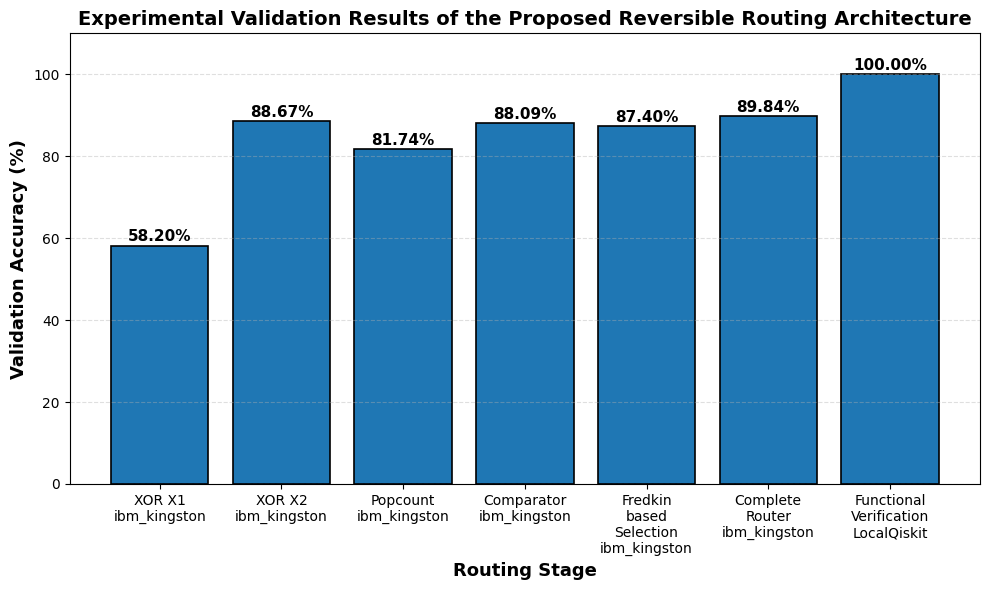

In [2]:
import matplotlib.pyplot as plt

# ===============================
# Experimental Validation Results
# ===============================

stages = [
    "XOR X1\nibm_kingston",
    "XOR X2\nibm_kingston",
    "Popcount\nibm_kingston",
    "Comparator\nibm_kingston",
    "Fredkin\nbased\nSelection\nibm_kingston",
    "Complete\nRouter\nibm_kingston",
    "Functional\nVerification\nLocalQiskit"
]

accuracy = [58.2, 88.67, 81.74, 88.09, 87.4, 89.84, 100.00]

# ===============================
# Plot
# ===============================

plt.figure(figsize=(10,6))

bars = plt.bar(
    stages,
    accuracy,
    edgecolor='black',
    linewidth=1.2
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.ylim(0,110)

plt.ylabel("Validation Accuracy (%)", fontsize=13, fontweight='bold')
plt.xlabel("Routing Stage", fontsize=13, fontweight='bold')

plt.title(
    "Experimental Validation Results of the Proposed Reversible Routing Architecture",
    fontsize=14,
    fontweight='bold'
)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig("Experimental_Validation_BarGraph.png", dpi=600)

plt.show()

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

backend = service.backend("ibm_kingston")


qiskit_runtime_service.__init__:WARNING:2026-10-08 20:42:43,518: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: student-ashokp25, QForge Quantum Club, student-otherssuc, student-nagaraju.23phd7022. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-10-08 20:42:43,518: Using instance: student-ashokp25, plan: open


In [5]:
import numpy as np

backend = service.backend("ibm_kingston")
target = backend.target

sq_fids = []

for gate_name in ["sx", "x"]:

    for qubits, props in target[gate_name].items():

        if props is None:
            continue

        if props.error is None:
            continue

        fid = 1 - props.error

        if fid > 0:
            sq_fids.append(fid)

print("Average 1Q Fidelity =", np.mean(sq_fids))
print("Minimum 1Q Fidelity =", np.min(sq_fids))
print("Maximum 1Q Fidelity =", np.max(sq_fids))

qiskit_runtime_service.backends:WARNING:2026-10-08 20:43:16,814: Using instance: student-ashokp25, plan: open


Average 1Q Fidelity = 0.9995114036580452
Minimum 1Q Fidelity = 0.9819544926885222
Maximum 1Q Fidelity = 0.9998837423118321


In [6]:
F1Q = 0.9993649480284034
FCZ = 0.9927548087306086

n1Q = 84
nCZ = 34

F_circuit = (F1Q ** n1Q) * (FCZ ** nCZ)

print("Estimated Circuit Fidelity =", F_circuit)
print("Estimated Circuit Fidelity (%) =", 100*F_circuit)

Estimated Circuit Fidelity = 0.7403779162082578
Estimated Circuit Fidelity (%) = 74.03779162082577



CX Gate Fidelity: 0.9875
Estimated Circuit Fidelity: 0.9509297119140627


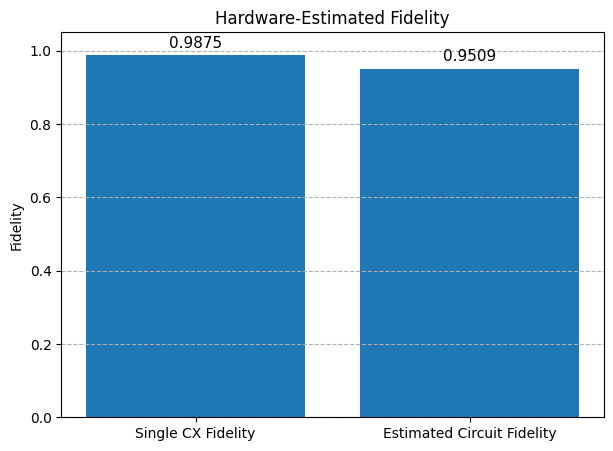

In [2]:
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit_aer import Aer

# =========================
# HELPER
# =========================
def initialize_bits(qc, reg, bitstring):
    for i, b in enumerate(reversed(bitstring)):
        if b == '1':
            qc.x(reg[i])


# =========================
# ROUTER WITH FULL BARRIERS
# =========================
def router(D_val, N1_val, N2_val):

    D  = QuantumRegister(3, 'D')
    N1 = QuantumRegister(3, 'N1')
    N2 = QuantumRegister(3, 'N2')

    X1 = QuantumRegister(3, 'X1')
    X2 = QuantumRegister(3, 'X2')

    d1 = QuantumRegister(2, 'd1')
    d2 = QuantumRegister(2, 'd2')

    anc = QuantumRegister(9, 'anc')
    flag = QuantumRegister(1, 'flag')

    OUT = QuantumRegister(3, 'OUT')
    c = ClassicalRegister(3, 'c')

    qc = QuantumCircuit(D, N1, N2, X1, X2, d1, d2, anc, flag, OUT, c)

    # INPUT
    qc.barrier(label="INPUT")
    initialize_bits(qc, D, D_val)
    initialize_bits(qc, N1, N1_val)
    initialize_bits(qc, N2, N2_val)

    # XOR
    qc.barrier(label="XOR")
    for i in range(3):
        qc.cx(N1[i], X1[i])
        qc.cx(D[i],  X1[i])

        qc.cx(N2[i], X2[i])
        qc.cx(D[i],  X2[i])

    # POPCOUNT
    qc.barrier(label="POPCOUNT")

    # d1
    qc.cx(X1[0], d1[0])
    qc.cx(X1[1], d1[0])
    qc.cx(X1[2], d1[0])

    qc.ccx(X1[0], X1[1], anc[0])
    qc.ccx(X1[0], X1[2], anc[1])
    qc.ccx(X1[1], X1[2], anc[2])

    qc.cx(anc[0], d1[1])
    qc.cx(anc[1], d1[1])
    qc.cx(anc[2], d1[1])

    # d2
    qc.cx(X2[0], d2[0])
    qc.cx(X2[1], d2[0])
    qc.cx(X2[2], d2[0])

    qc.ccx(X2[0], X2[1], anc[3])
    qc.ccx(X2[0], X2[2], anc[4])
    qc.ccx(X2[1], X2[2], anc[5])

    qc.cx(anc[3], d2[1])
    qc.cx(anc[4], d2[1])
    qc.cx(anc[5], d2[1])

    # COMPARATOR
    qc.barrier(label="COMPARATOR (d1 > d2)")

    qc.x(d2[1])
    qc.ccx(d1[1], d2[1], flag[0])
    qc.x(d2[1])

    qc.cx(d1[1], anc[6])
    qc.cx(d2[1], anc[6])
    qc.x(anc[6])

    qc.x(d2[0])
    qc.ccx(d1[0], d2[0], anc[7])
    qc.x(d2[0])

    qc.ccx(anc[6], anc[7], anc[8])
    qc.cx(anc[8], flag[0])

    # SELECTION
    qc.barrier(label="SELECTION")

    for i in range(3):
        qc.ccx(flag[0], N2[i], OUT[i])
        qc.x(flag[0])
        qc.ccx(flag[0], N1[i], OUT[i])
        qc.x(flag[0])

    # UNCOMPUTE COMPARATOR
    qc.barrier(label="UNCOMPUTE COMPARATOR")

    qc.cx(anc[8], flag[0])
    qc.ccx(anc[6], anc[7], anc[8])

    qc.x(d2[0])
    qc.ccx(d1[0], d2[0], anc[7])
    qc.x(d2[0])

    qc.x(anc[6])
    qc.cx(d2[1], anc[6])
    qc.cx(d1[1], anc[6])

    qc.x(d2[1])
    qc.ccx(d1[1], d2[1], flag[0])
    qc.x(d2[1])

    # UNCOMPUTE POPCOUNT
    qc.barrier(label="UNCOMPUTE POPCOUNT")

    qc.cx(anc[5], d2[1])
    qc.cx(anc[4], d2[1])
    qc.cx(anc[3], d2[1])

    qc.ccx(X2[1], X2[2], anc[5])
    qc.ccx(X2[0], X2[2], anc[4])
    qc.ccx(X2[0], X2[1], anc[3])

    qc.cx(X2[2], d2[0])
    qc.cx(X2[1], d2[0])
    qc.cx(X2[0], d2[0])

    qc.cx(anc[2], d1[1])
    qc.cx(anc[1], d1[1])
    qc.cx(anc[0], d1[1])

    qc.ccx(X1[1], X1[2], anc[2])
    qc.ccx(X1[0], X1[2], anc[1])
    qc.ccx(X1[0], X1[1], anc[0])

    qc.cx(X1[2], d1[0])
    qc.cx(X1[1], d1[0])
    qc.cx(X1[0], d1[0])

    # UNDO XOR
    qc.barrier(label="UNDO XOR")

    for i in range(3):
        qc.cx(D[i],  X2[i])
        qc.cx(N2[i], X2[i])

        qc.cx(D[i],  X1[i])
        qc.cx(N1[i], X1[i])

    # MEASURE
    qc.barrier(label="MEASURE")

    for i in range(3):
        qc.measure(OUT[i], c[i])

    return qc
    qc.draw('mpl')

# =====================================================
# Simple Fidelity Estimation
# =====================================================

cx_error = 0.0125

cx_fidelity = 1 - cx_error

cx_count = 4

estimated_circuit_fidelity = cx_fidelity ** cx_count

print("\nCX Gate Fidelity:", cx_fidelity)

print("Estimated Circuit Fidelity:",
      estimated_circuit_fidelity)

# =====================================================
# Plot
# =====================================================

labels = [
    "Single CX Fidelity",
    "Estimated Circuit Fidelity"
]

values = [
    cx_fidelity,
    estimated_circuit_fidelity
]

plt.figure(figsize=(7,5))

bars = plt.bar(labels, values)

plt.ylim(0,1.05)

for i,v in enumerate(values):

    plt.text(
        i,
        v+0.02,
        f"{v:.4f}",
        ha='center',
        fontsize=11
    )

plt.ylabel("Fidelity")

plt.title(
    "Hardware-Estimated Fidelity"
)

plt.grid(axis='y', linestyle='--')
